In [ ]:
import numpy as np
import math
from scipy.integrate import quad
from scipy.linalg import eigvalsh
from scipy.optimize import minimize_scalar
from scipy.stats import linregress
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import os
from scipy.stats import binom

# Basic Functions

In [2]:
#kronecker product code for more than 2 inputs
def kron(*matrices):
    result = np.array([[1]])
    for matrix in matrices:
        result = np.kron(result, matrix)
    return result

#Partial Trace Code
def IntegerDigits(n, b, l):
    digits = [0] * l
    pos = l - 1
    while pos != -1:
        digits[pos] = int(n % b)
        n //= b
        pos -= 1
    return digits

def FromDigits(digits, base):
    digits = digits[::-1]
    n = 0
    for i, d in enumerate(digits):
        n += d * base**i
        
    return n

def SwapParts(digits, p1, p2):
    new = np.copy(digits)
    new[p1] = digits[p2]
    new[p2] = digits[p1]
    return new

def dTraceSystem(D,s,dimen):
    Qudits=sorted(s)
    Qudits.reverse()
    TrkM = D
    z=len(Qudits)
    
    for q in range(z):
        n=math.log(TrkM.shape[0],dimen)
        assert n % 1 == 0
        n = int(n)
        
        M=TrkM
        M = np.array(M , dtype = complex)
        k=Qudits[q]
        temp = np.zeros(M.shape[0], dtype=complex)
        if k!=n:
            for j in range(n-k):
                b={0}
                for i in range(dimen**n):
                    digits=IntegerDigits(i,dimen,n)
                    if digits[n-1] != digits[n-j-2] and i not in  b:
                        number=FromDigits(
                            SwapParts(digits, n-1, n-j-2),
                            dimen
                        )
                        b.add(number)

                        temp[:] = M[i, :]
                        M[i, :] = M[number, :]
                        M[number, :] = temp

                        temp[:] = M[:, i]
                        M[:, i] = M[:, number]
                        M[:, number] = temp
        
        TrkM=[]
        for p in range(0,dimen**n,dimen):
            TrkM.append(
                sum(
                    M[p+h, h:dimen**n:dimen]
                    for h in range(dimen)
                )
            )
        TrkM = np.array(TrkM)
    
    return TrkM
#Recall matrix as dTraceSystem(matrix,[systems I want to trace out],dimension of system)

#defining basis vectors

#zero vector and its conjugate transpose                                         
zero= np.array([[1],[0]])
zeroCT=np.conjugate(zero.T)
#one vector and its conjugate transpose
one=np.array([[0],[1]])
oneCT=np.conjugate(one.T)
#plus vector and its conjugate transpose
plus=np.array([[1],[1]])*1/math.sqrt(2)
plusCT=np.conjugate(plus.T)
#minus vector and its conjugate transpose
minus=np.array([[1],[-1]])*1/math.sqrt(2)
minusCT=np.conjugate(minus.T)
#plusy and its conjugate transpose
plusy=np.array([[1],[complex(0.0, 1)]])*1/math.sqrt(2)
plusyCT=np.conjugate(plusy.T)
#minusy and its conjugate transpose
minusy=np.array([[1],[complex(0.0, -1)]])*1/math.sqrt(2)
minusyCT=np.conjugate(minusy.T)
#defining the Bell states
phiplus=(np.kron(zero, zero)+np.kron(one, one))*1/math.sqrt(2)
phiminus=(np.kron(zero, zero)-np.kron(one, one))*1/math.sqrt(2)
psiplus=(np.kron(zero, one)+np.kron(one, zero))*1/math.sqrt(2)
psiminus=(np.kron(zero, one)-np.kron(one, zero))*1/math.sqrt(2)
#defining the outer product of the Bell states
Phiplus=phiplus@np.conjugate(phiplus.T)
Phiminus=phiminus@np.conjugate(phiminus.T)
Psiplus=psiplus@np.conjugate(psiplus.T)
Psiminus=psiminus@np.conjugate(psiminus.T)
#defining Pauli matrices
pauliX=np.array([[0,1],[1,0]])
pauliY=np.array([[0,complex(0,-1)],[complex(0,1),0]])
pauliZ=np.array([[1,0],[0,-1]])

# GKP Qudit Code

In [ ]:
import numpy as np
from scipy.integrate import quad
from scipy.optimize import minimize_scalar
from scipy.linalg import eigvalsh
from scipy.stats import linregress
import matplotlib.pyplot as plt

# -------------------------------------------------
# Helpers: loss + squeezing
# -------------------------------------------------

def sigma_squared_from_squeezing_db(squeezing_db):
    if np.isinf(squeezing_db):
        return 0.0
    return 10 ** (-squeezing_db / 10)

def half_channel_transmissivity(loss_db):
    # loss_db is the half-channel loss in dB
    return 10 ** (-loss_db / 10)

def effective_sigma(loss_db, squeezing_db, loss_model="preamplified"):
    eta = half_channel_transmissivity(loss_db)
    sigma2 = sigma_squared_from_squeezing_db(squeezing_db)

    if loss_model == "preamplified":
        sigma2_eff = sigma2 * eta + (1 - eta)
    elif loss_model in {"cc", "cc-amplification"}:
        sigma2_eff = sigma2 + (1 - eta) / (2 * eta)
    else:
        raise ValueError("loss_model must be 'preamplified' or 'cc'")

    return np.sqrt(sigma2_eff)

# -------------------------------------------------
# Qudit Bell-diagonal model
# -------------------------------------------------

def qudit_basis(d, k):
    vec = np.zeros((d, 1), dtype=complex)
    vec[k, 0] = 1.0
    return vec

def qudit_Bell_state(d, k, l):
    psi = np.zeros((d * d, 1), dtype=complex)
    for r_ in range(d):
        phase = np.exp(2j * np.pi * r_ * l / d)
        ket1 = qudit_basis(d, r_)
        ket2 = qudit_basis(d, (r_ - k) % d)
        psi += phase * kron(ket1, ket2)
    return psi / np.sqrt(d)

def qudit_Bell_state_projector(d, k, l):
    psi = qudit_Bell_state(d, k, l)
    return psi @ psi.conj().T

# -------------------------------------------------
# Non-deterministic Homodyne detection model
# -------------------------------------------------

def homodyne_distribution(x, mu, sigma):
    return np.exp(-(x - mu)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))

def Pc_qudit(d, sigma, nu, j_cutoff=30):
    a = np.sqrt(2 * np.pi / d)
    total = 0.0
    for j in range(-j_cutoff, j_cutoff + 1):
        lower = a * (j * d - 0.5) + nu
        upper = a * (j * d + 0.5) - nu
        total += quad(lambda x: homodyne_distribution(x, 0, sigma), lower, upper)[0]
    return total

def Pf_qudit(d, sigma, nu, j_cutoff=30):
    a = np.sqrt(2 * np.pi / d)
    total = 0.0
    for k in range(1, d):
        for j in range(-j_cutoff, j_cutoff + 1):
            lower = a * (j * d + k - 0.5) + nu
            upper = a * (j * d + k + 0.5) - nu
            total += quad(lambda x: homodyne_distribution(x, 0, sigma), lower, upper)[0]
    return total

# -------------------------------------------------
# Shift probability - error model for Bell map
# -------------------------------------------------

def shift_probability(d, k, sigma, nu, j_cutoff=30):
    a = np.sqrt(2 * np.pi / d)
    total = 0.0
    for j in range(-j_cutoff, j_cutoff + 1):
        lower = a * (j * d + k - 0.5) + nu
        upper = a * (j * d + k + 0.5) - nu
        total += quad(lambda x: homodyne_distribution(x, 0, sigma), lower, upper)[0]
    return total

def shift_probability_vector(d, sigma, nu, j_cutoff=30):
    probs = np.array([shift_probability(d, k, sigma, nu, j_cutoff) for k in range(d)], dtype=float)
    total = np.sum(probs)
    if total <= 0 or not np.isfinite(total):
        raise ValueError("Shift probability normalisation failed")
    return probs / total

# -------------------------------------------------
# Constructing the memory-memory state
# -------------------------------------------------

def qudit_bell_diagonal_prob_table(d, sigma, nu, xL=0, yL=0, j_cutoff=30):
    ProbX = shift_probability_vector(d, sigma, nu, j_cutoff)
    ProbZ = shift_probability_vector(d, sigma, nu, j_cutoff)

    P_error = np.outer(ProbX, ProbZ)
    k0 = (d - xL) % d
    l0 = (d - yL) % d
    return np.roll(P_error, shift=(k0, l0), axis=(0, 1))

def qudit_hashing_bound(P_bell):
    d = P_bell.shape[0]
    P = P_bell[P_bell > 0]
    return max(0.0, np.log2(d) + np.sum(P * np.log2(P)))

def qudit_chain_distribution(P_succ, n):
    P_chain = np.fft.ifft2(np.fft.fft2(P_succ) ** (n + 1))
    P_chain = np.real_if_close(P_chain)
    P_chain = np.real(P_chain)
    P_chain = np.clip(P_chain, 0.0, None)
    P_chain = P_chain / np.sum(P_chain)
    return P_chain

# Implementing Prateek's recursive probabilistic entanglement swapping model for the repeater chain

# -------------------------------------------------
# Recursive probabilistic entanglement swapping
# -------------------------------------------------

def swap_distributions(distribution_A , distribution_B , q):

    # We combine two independent link-count distributions, A and B,
    # through one probabilistic intra-repeater entanglement-swapping stage that succeeds with probability q.

    # distribution_A[a] = Probability of a links on the left
    # distribution_B[b] = Probability of b links on the right

    # q = Probability that one local Bell swap at the repeater succeeds

    # We are calculating the probability of having c successful longer-distance entangled links after 
    # performing probabilistic entanglement swapping on two independent link-count distributions A and B.

    # This will return: output[c] = Probability of c successful longer-distance entangled links



    # -------------------------------------------------
    # -------------------------------------------------
    # We first verify that the success probability q is within the valid range [0, 1].
    if not 0 <= q <= 1:
        raise ValueError("q must be between 0 and 1")
    # -------------------------------------------------
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Maximum possible number of swaps
    # -------------------------------------------------
    # -------------------------------------------------
    # even if A and B have different lengths (different number of successful links), the maximum number of successful swaps
    # that can occur at the intra-repeater swap is limited by the shorter of the distributions.
    # We subtract 1 because we are indexing from 0.
    # -------------------------------------------------
    max_pairs = min(len(distribution_A) , len(distribution_B)) - 1
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # P(A >= k) and P(B >= k)
    # -------------------------------------------------
    # -------------------------------------------------
    # Here we are calculating the probability that the number of available entangled links in A and B
    # is greater than or equal to k. Here k represents the minimum number of links required on each side
    # to attempt k entanglement swaps.
    # -------------------------------------------------
    # We use the cumulative sum of the distributions in reverse order to calculate these probabilities.
    # We do this in reverse order because to obtain at least k links, we need to sum the probabilities
    # of having exactly k , k + 1 , k + 2 , ... , up to the maximum possible number of links.
    # -------------------------------------------------
    # For instance, consider the array distribution_A = [a , b , c , d], where:
    # a = P(A = 0), no entangled links
    # b = P(A = 1), one entangled link
    # c = P(A = 2), two entangled links
    # d = P(A = 3), three entangled links
    # -------------------------------------------------
    # First, reverse the array: [d , c , b , a]
    # Taking the cumulative sum gives: [d , d + c , d + c + b , d + c + b + a]
    # Reversing this result gives: [a + b + c + d , b + c + d , c + d , d]

    # These entries correspond to:
    # P(A >= 0) = a + b + c + d = 1
    # P(A >= 1) = b + c + d
    # P(A >= 2) = c + d
    # P(A >= 3) = d

    # Thus, the final array contains the probability of having at least 0 , 1 , 2 , and 3 links, respectively.
    # -------------------------------------------------
    # The notation [::-1] reverses the order of an array.
    # -------------------------------------------------
    # Therefore, distribution_A[::-1] reverses the original probability distribution,
    # while the final [::-1] restores the original indexing order after calculating the cumulative sums.
    # -------------------------------------------------
    # Mathematically, we are calculating:

    # P(A >= k) = sum_{a=k}^{A_max} P(A = a)
    # P(B >= k) = sum_{b=k}^{B_max} P(B = b)

    # For example:
    # P(A >= 0) = P(A=0) + P(A=1) + ... + P(A=A_max)
    # P(A >= 1) = P(A=1) + P(A=2) + ... + P(A=A_max)
    # P(A >= 2) = P(A=2) + P(A=3) + ... + P(A=A_max)
    # and so on.
    # -------------------------------------------------
    # These quantities are called upper-tail probabilities, because they sum the probability distribution
    # from k upwards. We need them because the number of possible entanglement-swap attempts is limited by the
    # smaller of the two available link counts:
    # -------------------------------------------------
    probability_distribution_A = np.cumsum(distribution_A[::-1])[::-1]
    probability_distribution_B = np.cumsum(distribution_B[::-1])[::-1]
    # -------------------------------------------------




    # -------------------------------------------------
    # -------------------------------------------------
    # P(min(A , B) >= k)
    # -------------------------------------------------
    # -------------------------------------------------
    # C = min(A, B)
    # -------------------------------------------------
    # To have at least k possible swap attempts, BOTH sides must contain at least k links.
    # Therefore: P(C >= k) = P(A >= k AND B >= k)
    # -------------------------------------------------
    # Since A and B are independent:
    # P(C >= k) = P(A >= k) * P(B >= k)
    # this is the probability that the minimum of random variables A and B is greater than or equal to k
    min_tail = (probability_distribution_A[:max_pairs + 1] * probability_distribution_B[:max_pairs + 1])
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Convert to P(min(A , B) >= t) into P(min(A , B) = t)
    # -------------------------------------------------
    # -------------------------------------------------
    # We have calculated the probability that BOTH sides of the repeater contain at least t links,
    # recall that we defined T = min(A , B), where T is the number of possible entanglement
    # swapping attempts at the repeater stations.
    # -------------------------------------------------
    # The above array min_tail[t], for a given t, contains AT LEAST t attempts being available
    # min_tail[t] = P(T >= t).
    # However, to calculate how many of these attempts ACTUALLY succeed, we need to calculate the
    # probability of having EXACTLY t available attempts, so we therefore need to convert
    # P(T >= t) --> P(T = t)
    # -------------------------------------------------
    # Recall that the probability of having AT LEAST t available attempts includes the possibilities of
    # having exactly t , t + 1 , t + 2 , ... , T_max attempts, at least t for up to T_max measn t is the lowest possible value.
    # Mathematically, P(T >= t) = P(T = t) + P(T = t + 1) + ... + P(T = T_max)
    # Similarly, P(T >= t + 1) = P(T = t + 1) + P(T = t + 2) + ... + P(T = T_max)
    # Subtracting the second expression from the first removes every possibility involving more than t attempts,
    # therefore, P(T = t) = P(T >= t) - P(T >= t + 1)
    # -------------------------------------------------
    # -------------------------------------------------
    # For example, if we consider min_tail = [1.0 , 0.9 , 0.5],
    # this means that P(T >= 0) = 1.0 , P(T >= 1) = 0.9 , P(T >= 2) = 0.5,
    # we can then calculate the probability of obtaining exactly t = [0 , 1 , 2] as
    # P(T = 0) = P(T >= 0) - P(T >= 1) = 1.0 - 0.9 = 0.1
    # P(T = 1) = P(T >= 1) - P(T >= 2) = 0.9 - 0.5 = 0.4
    # P(T = 2) = P(T >= 2) - P(T >= 3) = 0.5 - 0.0 = 0.5
    # therefore, p_attempts = [0.1 , 0.4 , 0.5]
    # -------------------------------------------------
    # -------------------------------------------------
    probability_of_attempts = min_tail - np.append(min_tail[1:] , 0.0)
    # -------------------------------------------------
    # here min_tail represents P(T >= t) and min_tail[1:] represents P(T >= t + 1)
    # so we write min_tail[1:] which considers all elements of P(T >= t) except the first, i.e., t + 1 , ... , T_max
    # we also append 0.0 here because we require that P(T >= T_max + 1 = 0),
    # this was specified in the above example where we had up to P(T >= 2) and P(T >= 3) was
    # not a valid outcome so we set it to 0.0, this is because it is impossible to have
    # MORE available swaps than the maximum supported by the two inputs.
    # We thus subtract the shifted array P(T >= t + 1) from P(T >= t) to give us
    # the probability of EXACTLY t available attempts for every t from 0 up to T_max.
    # -------------------------------------------------
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Initialisation of output probability distribution
    # -------------------------------------------------
    # -------------------------------------------------
    # We have now determined the probability of having exactly t possible entanglement-swapping attempts,
    # however, not every attempted swap suceeds. Each intra-repeater swap succeeds independently with probability q, and so,
    # we wish to calculate q(C = c), where C is the number of SUCCESSFUL longer-distance entangled links produced by this swapping stage.

    # Since we cannot obtain more successful swaps than the maximum number of available attempts:
    # C = 0 , 1 , 2 , ... , max_pairs
    # we create an array of length max_pairs + 1 containing zeros, i.e., 0 listed max_pairs + 1 times.
    # Each position output[c] will eventually contain the probability of exactly c successful swaps.
    # We initialise with zeros because contributions from different possible values of T will be added together in the following loop.
    # -------------------------------------------------
    output = np.zeros(max_pairs + 1)
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Consider every possible number of swap attempts
    # -------------------------------------------------
    # -------------------------------------------------
    # Recall that T is a random variable.
    # We do not know how many successful swap attempts there will be in a particular multiplexing block,
    # We therefore must consider every possible value:
    # T = 0 , 1 , 2 , ... , max_pairs
    # Each value occurs with probability q(T = t), which is stored in probability_of_attempts[t].
    # The enumerate() function provides both:
    #  - attempts = t
    #  - probability_of_attempts = q(T = t)
    # This pair can be described using the following example:
    # -------------------------------------------------
    # Consider probability_of_attempts = [0.1 , 0.4 , 0.5], the loop will consider:
    # attempts = 0 , probability_of_attempt = 0.1
    # attempts = 1 , probability_of_attempt = 0.4
    # attempts = 2 , probability_of_attempt = 0.5
    # -------------------------------------------------
    for attempts , probability_of_attempt in enumerate(probability_of_attempts):
        # -------------------------------------------------
        # -------------------------------------------------
        # Skip outcomes with zero probability
        # -------------------------------------------------
        # -------------------------------------------------
        # If q(T = t) = 0, this number of available attempts never occurs.
        # It therefore contributes nothing to the final output probability distribution.
        # Therefore, we skip it to avoid unnecessary calculations.
        if probability_of_attempt <= 0:
            continue
        # -------------------------------------------------
        # -------------------------------------------------
        # Possible numbers of successful swaps
        # -------------------------------------------------
        # -------------------------------------------------
        # Suppose we have exactly t available entanglement-swapping attempts,
        # and since each attempt can either succeed or fail, the possible number of successful swaps is:
        # C = 0 , 1 , 2 , ... , t
        # For example, if we have 3 available attempts, the possible number of successful swaps is:
        # C = 0 , 1 , 2 , 3
        # so successful_swap_values = [0 , 1 , 2 , 3]
        # which can be generalised to successful_swap_values = np.arange(attempts + 1)
        # -------------------------------------------------
        successful_swap_values = np.arange(attempts + 1)
        # -------------------------------------------------



        # -------------------------------------------------
        # -------------------------------------------------
        # Conditional binomial distribution
        # -------------------------------------------------
        # -------------------------------------------------
        # We now calculate the probability that exactly c of the t available entanglement swaps succeed.
        # Each swap is a Bernoulli swap, meaning that
        # - the connection across the repeater is successfully generated with probability q
        # - the connection across the repreater fails to be generated with probability 1 - q
        # We also assume the swap attempts are independent.
        # -------------------------------------------------
        # Therefore, conditioned on T = t,
        # the number of successful swaps C follows a binomial distribution C ~ Binomial(T = t, q),
        # we read this expression as T = t trials where each trial succeeds with probability q which is a binomial distribution.
        # Mathematically, the probability of having exactly c successful swaps given t available attempts is:
        # for successful_swap_values = c
        # P(C = c | T = t) = (t choose c) * q^c * (1 - q)^(t - c)
        # where (t choose c) = t! / (c! * (t - c)!) is the binomial coefficient, 
        # where the binomial coefficient counts the number of ways to choose c successful swaps from t available attempts,
        # q^c is the probability of having exactly c successful entanglmenet swap attempts,
        # and (1 - q)^(t - c) is the probability of having the remaining t - c attempts be failures.
        # -------------------------------------------------
        # For example,
        # if attempts = 2 and q = 0.7
        # then P(C = 0 | T = 2) = (2 choose 0) * 0.7^0 * (1 - 0.7)^(2 - 0) = 1 * 1 * 0.3^2 = 0.09
        # P(C = 1 | T = 2) = (2 choose 1) * 0.7^1 * (1 - 0.7)^(2 - 1) = 2 * 0.7 * 0.3 = 0.42
        # P(C = 2 | T = 2) = (2 choose 2) * 0.7^2 * (1 - 0.7)^(2 - 2) = 1 * 0.49 * 1 = 0.49
        # and the resulting probability array is probability_of_successes = [0.09 , 0.42 , 0.49]
        # scipy.stats.binom.pmf() calculates all these probabilities simultaneously for
        # every possible number of successful swaps successful_swap_values = 0 , 1 , ... , t, and returns them in an array.
        # This is known as the probability mass function (pmf) of the binomial distribution.
        # -------------------------------------------------
        probability_of_successes = binom.pmf(successful_swap_values , attempts , q)
        # -------------------------------------------------



        # -------------------------------------------------
        # -------------------------------------------------
        # Weight by the probability of having this many available swap attempts
        # -------------------------------------------------
        # -------------------------------------------------
        # We have calculated P(T = t) = probability of attempt T succeeding,
        # and P(C = c | T = t) = probability of c successful swaps given t available attempts.
        # We now combine these two probabilities to obtain the joint probability of having exactly
        # t available attempts AND obtaining exactly c successful swaps. This is defined as
        # P(C = c AND T = t) = P(T = t) * P(C = c | T = t)
        # -------------------------------------------------
        # However, exactly c successful swaps can occur for several different numbers of attempts,
        # for instance, if we have exactly one successful swap, C = 1, this could occur when the total number of available swaps is equal to
        # T = 1 : and the single swap succeeds
        # T = 2 : so exactly one of the swaps succeeded and the other failed
        # T = 3 : sp exactly one of the swaps succeeded and the other two failed
        # and so on for the number of available attempts...
        # -------------------------------------------------
        # We must therefore add all these possibilities together, which is stated by the law of total probability for exactly c successful swaps
        # P(C = c) = sum_{t = c} ^ {T_max} P(T = t) * P(C = c AND T = t)
        # P(C = c) = sum_{t = c} ^ {T_max} P(T = t) * (t choose c) * q^{c} * (1 - q)^{t - c}
        # -------------------------------------------------
        # For example, we consider
        # P(T = 0) = 0.1 , P(T = 1) = 0.4 , P(T = 2) = 0.5 and suppose that q = 0.7,
        # we can calculate the probability of obtaining exactly one successful swap for
        # -------------------------------------------------
        # - When T = 1:
        # -------------------------------------------------
        #   P(T = 1) = 0.4, meaning there is a 40% chance of having one available attempt,
        #   given one attempt, the probability of one success is 0.7, therefore,
        #   P(C = c | T = t) = P(T = 1) * P(C = 1 | T = 1)
        #   Therefore P(C = 1 , T = 1) = (0.4) * (0.7) = 0.28
        # -------------------------------------------------
        # - When T = 2:
        # -------------------------------------------------
        #   P(T = 2) = 0.5, meaning there is a 50% probability of having two available attempts,
        #   given two attempts, the probability of having exactly one success is
        #   P(C = 1 | T = 2) = (2 choose 1) * (0.7) * (0.3) = 0.42
        #   Therefore P(C = 1 , T = 2) = (0.5) * (0.42) = 0.21
        # -------------------------------------------------
        # - When T = 0 one swap is impossible so we neglect it
        # -------------------------------------------------
        # Therefore P(C = 1) = P(C = 1 , T = 1) + P(C = 1 , T = 2) = 0.28 + 0.21 = 0.49
        # This is the unconditional probability of obtaining exactly one successful longer-distance entangled link.
        # We can also calculate P(C = 0) = 0.265 and P(C = 2) = 0.245, where P(C = 0) + P(C = 1) + P(C = 2) = 1.0
        # -------------------------------------------------
        # We therefore consider [:attempts + 1] to select the first 'attempts + 1' elements of the output array,
        # which correspond to c = 0 , 1 , ... , attempts,
        # the operator '+=' adds the contributions from this particular value of T to the existing values in the output array.
        # After the loop finishes considering every possible value of T, the output array will contain 
        # the final probability distribution of having exactly c successful longer-distance entangled links.
        # -------------------------------------------------
        output[:attempts + 1] += (probability_of_attempt * probability_of_successes)
        # -------------------------------------------------
        # This final output is the UNCONDITIONAL probability of having exactly t available attempts AND obtaining exactly c successful swaps
        # where each element of this summation is a joint probability.



    # -------------------------------------------------
    # -------------------------------------------------
    # Remove tiny numerical errors
    # -------------------------------------------------
    # -------------------------------------------------
    # Every entry in a probability distribution MUST be non-negative. In exact arithmetic, the above calculations produce non-negative
    # probabilities. Furthermore, floating-point calculations can introduce tiny numerical errors. For example, subtracting two
    # nearly equal upper-tail probabilities may produce a very small negative value instead of EXACTLY zero.
    # The function np.maximum(output , 0.0) replaces ANY negative entries with zero, whilst preserving positive entries. This is a numerical
    # safeguard to ensure that the output is a valid probability distribution.
    output = np.maximum(output, 0.0)
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Normalisation of the output probability distribution
    # -------------------------------------------------
    # -------------------------------------------------
    # Since output[c] represents the probability of having exactly c successful longer-distance entangled links, the complete
    # probability distribution must satisfy sum_{c = 0}^{max_pairs} P(C = c) = 1.0, so we thus calculate the total probability
    # -------------------------------------------------
    total = np.sum(output)
    # -------------------------------------------------



    # -------------------------------------------------
    # If the total probability is zero, negative, infinite, or undefined, normalisation is invalid.
    # We therefore stop the calculation and report an error rather than returning an invalid probability distribution.
    # -------------------------------------------------
    if total <= 0 or not np.isfinite(total):
        raise ValueError("Swapping distribution failed")
    # -------------------------------------------------
    # We therefore divide every probability by the total, thus ensuring that the returned distribution sums to one, up to numerical precision.
    # The final result is output[c] = P(C = c).
    # This distribution can now be used as an input to the NECT recursive swapping stage.
    # -------------------------------------------------
    return output / total




# -------------------------------------------------
# Nested swapping across the repeater chain
# -------------------------------------------------

def recursive_network_distribution(pELEM_dist , n , q):

    # -------------------------------------------------
    # We now use the previously defined swap_distributions() function to connect ALL elementary segments of the repeater chain.
    # Recall that pELEM_dist is the complete probability distribution for the number of successfully heralded elementary links in ONE segment.
    # For K = M * m multiplexed elementary-link attempts, the number of successful elementary links X is defined by the binomial distribution
    # X ~ Binomial(K , q), where q is the probability that one intra-repeater Bell swap succeeds.
    # -------------------------------------------------
    # Therefore pELEM_dist = P(X = k) - (K choose k) * q^{k} * (1 - q)^{K - k},
    # meaning that the number of successful elementary links X, defined by the binomial distribution, is equal to exactly k links.
    # This distribution already accounts for probabilistic elementary link generation, we are simply stating the link generations are binomial
    # and that the purpose of this function is NOT to repeat elementary-link generation, but to connect the successfully generated links
    # through probabilistic intra-repeater swapping.
    # -------------------------------------------------
    # This function has the following inputs:
    #   - p_ELEM_dist: the probability distribution of elementary-link counts for each segment
    #   Note: This function is used later in the qudit_hashing_rate function where the elementary links also have a binomial distribution
    #   - n: the number of intermediate repeater stations
    #   - q: probability that one local intraprepeater entanglement swap succeeds
    # -------------------------------------------------
    # The output of this function is pNETWORK_dist[z] = P(Z = z)
    # this is the probability of exactly z complete end-to-end entangled pairs
    # where Z is the number of complete end-to-end entangled pairs after stitching together all intra-repeater swaps.
    # -------------------------------------------------
    
    # -------------------------------------------------
    # -------------------------------------------------
    # Number of elementary segments
    # -------------------------------------------------
    # -------------------------------------------------

    # -------------------------------------------------
    # As we know, for a linear chain connecting n intermediate repeater stations, we will have n + 1 elementary segments
    n_segments = n + 1
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Initialize the elementary-link distributions
    # -------------------------------------------------
    # -------------------------------------------------



    # -------------------------------------------------
    # Every elementary segment is assumed to have the same physical parameters, and therefore, the same elementary-link probability distribution.
    # We construct one distribution for each segment,
    # for example, if n = 3, then n_segments = 4, where
    # level [P_X1 , P_X2 , P_X3 , P_X4]
    # with each P_Xi being initially equal to pELEM_dist.
    # -------------------------------------------------
    # This statement does not mean that all four segments generate the same number of successful links.
    # Rather, it means that their link counts are independent random variables with the same distribution.
    level = [pELEM_dist.copy() for _ in range(n_segments)] 
    # We generate a separate array for each segment (for each separate distribution)
    # -------------------------------------------------



    # -------------------------------------------------
    # -------------------------------------------------
    # Continue until the entire chain is connected
    # -------------------------------------------------
    # -------------------------------------------------



    # -------------------------------------------------
    # At the beginning, we have n + 1 separate elementary-link distributions. 
    # Each iteration of the following while loop combines neighbouring segments into longer-distance entangled links.
    # The loop continues until one one distribution remains, corresponding to the complete Alice-Bob connection.
    # -------------------------------------------------
    # For example, with four elementary segments:
    # -------------------------------------------------
    # Level 0 = [P_X1 , P_X2 , P_X3 , P_X4]
    # -------------------------------------------------
    # Level 1 = [P_12 , P_34]
    # -------------------------------------------------
    # Level 2 = [P_1234]
    # -------------------------------------------------
    # Here, P_12 and P_34 describe longer-distance segments obtained after the first swapping level
    # P_1234 describes the complete end-to-end Bell pair between Alice and Bob.
    # -------------------------------------------------




    while len(level) > 1:
        
        # -------------------------------------------------
        # We initially create an empty list for the next swapping level.
        # Each new distribution will represent a longer segment formed by combining two neighbouring segments from the current level.
        next_level = []
        # -------------------------------------------------




        # -------------------------------------------------
        # -------------------------------------------------
        # Combine adjacent segments in pairs
        # -------------------------------------------------
        # -------------------------------------------------



        # -------------------------------------------------
        # We now wish to consider distributions in neighbouring pairs
        # so we write range(0 , len(level) , 2) which generates
        # 0 , 2 , 4 , ...
        # so we then consider distributions in the following neighbouring pairs
        # (level[0] , level[1])
        # (level[2] , level[3])
        # (level[4] , level[5])
        # and so on...
        # This is what constructs the nested swapping schedule
        # -------------------------------------------------

        for i in range(0 , len(level) , 2):

            # -------------------------------------------------
            # We then check whether a neighbouring distribution exists.
            # If i + 1 is within the list, we have two neighbouring segments that can be connected.
            # -------------------------------------------------

            if i + 1 < len(level):
                
                # -------------------------------------------------
                # We now perform ONE probabilistic swapping stage
                # -------------------------------------------------
                # The prior function swap_distributions() calculates the full probability distribution of successful longer-distance
                # links obtained by joining the two input segments. 
                # -------------------------------------------------
                # Importantly, the output distribution already accounts for:
                #   1. The probability of different available link counts on both sides of the repeater station
                #   2. The number of possible swap attempts, which is limited by the smaller link count
                #   3. The independent success probability q of each attempted intra-repeater swap.
                # -------------------------------------------------
                # Thus, the returned distribution is
                # P(C = c) = Probability of exactly c successful longer-distance links.
                # -------------------------------------------------

                combined = swap_distributions(level[i] , level[i + 1] , q)

                # -------------------------------------------------
                # Next, we store the resulting longer-distance distribution for the next level
                # -------------------------------------------------
                next_level.append(combined)


                # -------------------------------------------------
                # But what if we have an unmatched segment?
                # -------------------------------------------------
            
            # -------------------------------------------------
            # -------------------------------------------------
            else:
            # -------------------------------------------------
            # -------------------------------------------------



                # -------------------------------------------------
                # -------------------------------------------------
                # Handling an unmatched segment
                # -------------------------------------------------
                # -------------------------------------------------
                # If the current level contains an odd number of segments, the final segment has NO neighbour to combine with at this level.
                # -------------------------------------------------
                # For example:
                # level = [P_1 , P_2 , P_3]
                # We first combine P_1 and P_2, giving P_12, yet P_3 remains unchainged.
                # Therefore, next_level = [P_12 , P_3], so in the following iteration, P_12 and P_3 are combined.
                # This does not mean P_3 has failed, rather it simply waits until the NEXT swapping level before it can be connected.
                # -------------------------------------------------

                next_level.append(level[i])

        # -------------------------------------------------
        # -------------------------------------------------
        # Advance to the next swapping level
        # -------------------------------------------------
        # -------------------------------------------------



        # -------------------------------------------------
        # We replace the current list of link-count distributions with the NEWLY constructed list of longer connection distributions.
        # The new distributions represent longer-distance links produced by the previous swapping stage.
        # This is why the model is recursive:
        #   the output distribution of one swapping stage becomes the input distribution of the next
        # It is important to note that we are not repeating the elementary-link generation process, here we are simply combining distributions.

        level = next_level


    # -------------------------------------------------
    # -------------------------------------------------
    # Final end-to-end probability distribution
    # -------------------------------------------------
    # -------------------------------------------------

    # The while loop above terminates when only ONE probability distribution remains.
    # This final distribution represents the number of completed entangled pairs connecting the two end nodes of the repeater chain.
    # If Z is the number of completed end-to-end pairs:
    # pNETWORK_dist[z] = P(Z = z)

    # This array contains probabilities for Z = 0 , 1 , 2 , ... , K
    # where K = M * m , i.e., the maximum number of elementary-link attempts per segment (which is multiplexed by M and m)

    pNETWORK_dist = level[0]

    # -------------------------------------------------
    # -------------------------------------------------
    # Check normalisation
    # -------------------------------------------------
    # -------------------------------------------------

    # Since pNETWORK_dist is a complete probability distribution, all its entries must sum to one, thus sum_z (P(Z = z)) = 1
    # We use np.isclose() to allow for small floating-point numerical errors, if the normalisation check fails, assert raises an error

    assert np.isclose(np.sum(pNETWORK_dist) , 1.0)

    # -------------------------------------------------
    # Return the complete distribution of the number of completed end-to-end entangled pairs
    # -------------------------------------------------
    return pNETWORK_dist



# -------------------------------------------------
# GKP Qudit Hashing Rate - Multiple-success model
# -------------------------------------------------

def qudit_hashing_rate(Nreg , squeezing_db , nu , L , n , M , q , tau , m , j_cutoff=30 , loss_model="preamplified" , return_details=False):

    # ---------------------------------------------
    # 1. Logical dimension and effective noise
    # ---------------------------------------------

    d = 2 ** Nreg

    half_loss_db = 0.2 * L / (2 * (n + 1))

    sigma_eff = effective_sigma(half_loss_db , squeezing_db , loss_model = loss_model)
 
    # ---------------------------------------------
    # 2. GKP elementary-link heralding probability
    # ---------------------------------------------

    Pc = Pc_qudit(d , sigma_eff , nu , j_cutoff = j_cutoff)

    Pf = Pf_qudit(d , sigma_eff , nu , j_cutoff = j_cutoff)

    pSWAP = (Pc + Pf) ** 2

    # Check physical probability range
    if not -1e-10 <= pSWAP <= 1 + 1e-10:
        raise ValueError("Invalid elementary success probability")
    # restriction of pSWAP between 0 and 1
    pSWAP = float(np.clip(pSWAP, 0.0, 1.0))

    # ---------------------------------------------
    # 3. Binomial elementary-link distribution
    # ---------------------------------------------

    # -------------------------------------------------
    # New part of the model
    # -------------------------------------------------
    # Previously, our model calculated the probability of obtaining AT LEAST one successful elementary link: pELEM = 1 - (1 - pSWAP)^(M * m) .
    # However, this did not retain any information about HOW many elementary links succeeded, it only considered the case where ONE succeeds,
    # our new aim is to retain the FULL probability distribution of successful link counts.
    # Considering M the number of spatially multiplexed attempts per temporal bin and m the number of temporal bins,
    # the total number of elementary link attempts per segment in one multiplexing block is K = M * m
    # -------------------------------------------------

    K = M * m

    # -------------------------------------------------
    # A binomial distribution requires an integer number of trials, we first verify K is a positive integer
    # -------------------------------------------------
    if K < 1 or int(K) != K:
        raise ValueError("M*m must be a positive integer")

    K = int(K)

    # -------------------------------------------------
    # The number of successfully generated links can be any integer from 0 to K,
    # therefore we use np.arange(K + 1) = [0 , 1 , 2 , ... , K]
    # -------------------------------------------------

    k_values = np.arange(K + 1)

    # -------------------------------------------------
    # Each elementary link attempt has two possible outcomes:
    #   - link succeeds with probability pSWAP
    #   - link fails with probability 1 - pSWAP
    # -------------------------------------------------
    # By assuming K independent and identical attempts, the number of X successful links is a binomial distribution X ~ Binomial(K , pSWAP)
    # Therefore, P(X = k) = (K choose k) * pSWAP^{k} * (1 - pSWAP)^{K - k}, where binom.pmf() calculates these probabilities for every value of k.
    # The resulting array contains:
    #   - pELEM_dist[0] = P(X = 0)
    #   - pELEM_dist[1] = P(X = 1)
    #   - ...
    #   - pELEM_dist[K] = P(X = K)
    # -------------------------------------------------
    # This is where the GKP elementary link advantage enters the recursive model, we know that for the low-loss setting pSWAP is almost 
    # deterministic, so the distribution is concentrated near K successful links, i.e., every instance of multiplexing basically guarantees
    # an extra link. Whereas, in the high-loss setting where GKP struggles to establish connections at higher transmission distances,
    # the distribution is concentrated near zero successful links.
    # -------------------------------------------------

    pELEM_dist = binom.pmf(k_values , K , pSWAP)




    # ---------------------------------------------
    # 4. Recursive nested swapping
    # ---------------------------------------------

    # Now that we have established that elementary links are ALSO binomially distributed, we NOW thus have the probability distribution of
    # successfully generating elementary links in each segment. These links MUST be connected through the n intermediate repeater stations.
    # This is where we incorporate the prior functions which accomplish the following tasks:
    # -------------------------------------------------
    #   - swap_distributions(): combining two independent elementary link distributions and outputs the probability of c successful
    #                           longer-distance entangled links, where the intra-repeater swap succeeds with probability q.
    
    #   - recursive_network_distribution(): - using the combinations of independent probability distributions from swap_distributions,
    #                                         we now connect ALL elementary segments of the repeater chain to obtain the probability of obtaining
    #                                         exactly z complete end-to-end entangled pairs after stitching together all intra-repeater swaps.
    # -------------------------------------------------
    # Therefore at each swapping stage:
    #   1. Two neighbouring link-count distributions are combined
    #   2. The number of possible swaps is limited by the smaller available link count
    #   3. Each swap independently succeeds with probability q
    #   4. The complete output distribution is propagated to the next swapping level
    # -------------------------------------------------
    # This is looped until the complete end-to-end link count distribution is obtained. Importantly, we DO NOT repeat elementary link generation
    # at every level, we only connect links ALREADY generated during the initial multiplexing block.
    # -------------------------------------------------

    pNETWORK_dist = recursive_network_distribution(pELEM_dist , n , q)





    # ---------------------------------------------
    # 5. Network statistics
    # ---------------------------------------------

    # The final array contains pNETWORK_dist[z] = P(Z = z), where Z is the random number of completed end-to-end entangled pairs.
    # We can use this distribution to calculate the expected number of completed pairs, which is different to our previous analysis of
    # obtaining at least one end-to-end pair.
    # -------------------------------------------------
    # The expected number of completed pairs is calculated as E[Z] = sum_{z = 1}^{K} z * P(Z = z)
    # such that each possible number of completed pairs is WEIGHTED by its probability.
    # -------------------------------------------------
    #  For example, if
    #   P(Z = 0) = 0.2
    #   P(Z = 1) = 0.5
    #   P(Z = 2) = 0.3
    # Then E[Z] = (0 * 0.2) + (1 * 0.5) + (2 * 0.3) = 1.1
    # This does not mean that a particular multiplexing block produces 1.1 pairs, rather it means an average number of completed pairs
    # approaches 1.1 over MANY blocks.
    # -------------------------------------------------
    # We first itemise all possible events by creating an arange of all possible outcomes
    # -------------------------------------------------

    z_values = np.arange(len(pNETWORK_dist))

    # -------------------------------------------------
    # Next, we use np.dot() to multiply corresponding entries of two arrays and add the products.
    # Therefore, np.dot(z_values , pNETWORK_dist) = [0 * P(Z = 0)] + [1 * P(Z = 1)] + ... + [K * P(Z = K)]

    expected_network_pairs = np.dot(z_values , pNETWORK_dist)






    # ---------------------------------------------
    # 6. End-to-end generation rates
    # ---------------------------------------------
    # We now convert the entirety of our network statistics into entanglement rates by dividing by the multiplexing block duration (m * tau).
    # In our current model, tau = duration of ONE temporal attempt and m = number of temporal bins. This total time (m * tau) assumes additional
    # communication, storage, and swapping delays, which we assume to be already included in the pulse duration tau.
    # -------------------------------------------------
    # We then count every completed pair as E[Z] / (m * tau) which counts the average number of completed end-to-end pairs per second
    # -------------------------------------------------

    rate_multi = (expected_network_pairs / (tau * m))





    # ---------------------------------------------
    # 7. Existing Bell-diagonal error model
    # ---------------------------------------------
    # So far, we have calculated HOW MANY entangled pairs are successfully generated, however, successful heralding does not necessarily
    # produce a perfect maximally entangled state. Finite squeezing of GKP qudits, transmission loss, and homodyne decoding errors induce logical shift errors.
    # The existing Bell-diagonal error model describes the quantum state of one successfully heralded elementary link. We define P_elem to be the distribution
    # of logical Bell errors WITHIN a single successfully heralded link. This is different from pELEM_dist which is the distribution of the NUMBER of links.
    # -------------------------------------------------

    P_elem = qudit_bell_diagonal_prob_table(d , sigma_eff , nu , j_cutoff = j_cutoff)

    # -------------------------------------------------
    # The end-to-end state is obtained by propagating this Bell-diagonal error distribution through n entanglement-swapping operations. In this model, this is
    # represented by a circular convolution of the Bell error probability error table across n + 1 elementary links. The qudit_chain_distribution() function
    # evaluates this convolution using a two-dimensional FFT. The output P_chain describes the logical Bell-error probabilities of a completed end-to-end
    # entangled pair. This calculation concerns state QUALITY, NOT the number of completed pairs.
    # -------------------------------------------------

    P_chain = qudit_chain_distribution(P_elem , n)

    # -------------------------------------------------
    # Then we calculate the hashing bound of the completed end-to-end Bell-diagonal state
    # -------------------------------------------------
    state_bound = qudit_hashing_bound(P_chain)

    # ---------------------------------------------
    # 8. Hashing rates
    # ---------------------------------------------

    hashing_rate_multi = (rate_multi * state_bound)

    # ---------------------------------------------
    # 9. Optional diagnostic information
    # ---------------------------------------------

    if return_details:

        return {
            "pSWAP": pSWAP,
            "pELEM_dist": pELEM_dist,
            "pNETWORK_dist": pNETWORK_dist,
            "expected_network_pairs": expected_network_pairs,
            "rate_multi": rate_multi,
            "state_bound": state_bound,
            "hashing_rate_multi": hashing_rate_multi
        }

    # Default output for optimization and plotting
    return hashing_rate_multi



# -------------------------------------------------
# -------------------------------------------------
# Optimised GKP Qudit Hashing Rate
# -------------------------------------------------
# -------------------------------------------------
def optimal_qudit_hashing_rate(Nreg , squeezing_db , L , n , M , q , tau , m , j_cutoff = 30 , loss_model = "preamplified" , return_nu = False):

    d = 2 ** Nreg

    spacing = np.sqrt(2 * np.pi / d)

    # -------------------------------------------------
    # Defining the objective function
    # -------------------------------------------------
    # We want to find the postselection window nu that maximises the GKP hashing rate. Mathematically, nu_opt = argmax_nu HR_multi(nu)
    # meaning our hashing rate depends on nu through:
    #   1. the accepted homodyne probabilities Pc and Pf
    #   2. the elementary link success probability pSWAP = (Pc + Pf)**2
    #   3. the binomial elementary link distribution of pSWAP across one multiplexing block (how many successful elementary links can be generated?)
    #   4. the recursively generated end-to-end link count distribution (by linking together intra repeater Bell swaps to form end-to-end links)
    #   5. the conditional Bell-diagonal error distribution and its hashing bound
    # -------------------------------------------------
    # Therefore, changing nu affects both the number of successfully generated pairs AND the entanglement quality of those pairs.
    # -------------------------------------------------
    # scip.optimize.minimize_scalaer() minimizes a function rather than maximizing it, so we therefore define the negative hashing rate:
    # neg_rate(nu) = -HR_multi(nu)
    # such that when we minimise this quantity, this is in fact equivalent to maximising the original hashing rate.
    # -------------------------------------------------

    def neg_rate(nu):

        # -------------------------------------------------
        # We calculate the multiple-success hashing rate for the current trial value of nu.
        # All other physical and network parameters are held fixed during the optimisation.
        # -------------------------------------------------

        value = qudit_hashing_rate(Nreg = Nreg , squeezing_db = squeezing_db , nu = nu , L = L , n = n , M = M , q = q , tau = tau , m = m , j_cutoff = j_cutoff , loss_model = loss_model)

        # -------------------------------------------------
        # If the hahsing rate is finite, return its negative so that minimize_scalar() can search for the maxmimum.
        # If the value is NOT finite, return infinity.
        # This prevents the optimiser from treating an invalid numerical result as a valid candidate solution.
        # -------------------------------------------------

        return -value if np.isfinite(value) else np.inf
    
    # -------------------------------------------------
    # -------------------------------------------------
    # Perform the bounded scalar optimisation
    # -------------------------------------------------
    # -------------------------------------------------
    # The postselection window must lie within 0 <= nu <= lattice_spacing / 2.
    # -------------------------------------------------
    #   - For nu = 0 there is no additional exclusion window around the logical decision boundaries.
    #   - By increasing nu we reject a larger region of ambiguous homodyne outcomes.
    #   - For nu approaching lattice_spacing / 2 the accepted interval shrinks towards zero width
    # -------------------------------------------------
    # We therefore search for the optimum within the physically allowed interval.
    # method = "bounded" instructs scipy to use a bounded one-dimensional optimisation.
    # -------------------------------------------------

    result = minimize_scalar(neg_rate , bounds = (0 , spacing / 2) , method = "bounded")

    # -------------------------------------------------
    # -------------------------------------------------
    # Recover the optimised hashing rate
    # -------------------------------------------------
    # -------------------------------------------------
    # The optimiser returns the minimum value of the NEGATIVE hashing rate function, so we therefore multiply by -1 to recover the maximum hashing rate.
    # The function result.success indicates whether the optimiser reports successful convergence, if the optimisation fails, we return 0.0, we also use
    # max(0.0 , -result.fun) because the hashing rate is defined to be non-negative.

    rate = max(0.0 , -result.fun) if result.success else 0.0

    # -------------------------------------------------
    # -------------------------------------------------
    # Optionally return the optimal postselection window
    # -------------------------------------------------
    # -------------------------------------------------
    # If return_nu = True, return both
    #   1. rate: maxmimum multiple-success hashing rate
    #   2. result.x: postselection window nu at which the optimiser found this maximum multiple-success hashing rate
    # -------------------------------------------------
    # This may be useful if we ever require to plot how the optimal postselection window changes with impactful variables like
    # distance, squeezing, logical qudit dimension, multiplexing resources, etc.
    # -------------------------------------------------

    if return_nu:
        return rate , result.x

    # -------------------------------------------------
    # Otherwise, return only the optimised multiple-success hashing rate
    # -------------------------------------------------
    return rate

# Hashing Rate data generation

## Nreg = [1,2,3,4,5,6,7,8,9] , m = [1,2,...,20] , n = [1,2,4,8,16]

In [4]:
# ----------------------------
# Parameters
# ----------------------------
Ls = np.arange(0, 150, 1.0)
Nreg_values = [1, 2, 3, 4, 5, 6, 7, 8, 9]
m_values = np.arange(1, 21)
n_vals = [1, 2, 4, 8, 16]
n_scan_vals = np.arange(1, 17)

squeezing_dB = 5
M = 1
q = 0.7
tau = 1e-8

# output folder for plots
output_dir = "gkp_raw_rate_plots"
os.makedirs(output_dir, exist_ok=True)

In [5]:
# ----------------------------
# Compute all data
# ----------------------------
all_results = {}

for Nreg in Nreg_values:
    print(f"\nComputing all raw rate data for Nreg = {Nreg}")
    all_results[Nreg] = {}

    for m in m_values:
        print(f"  m = {m}")

        fixed_n_data = {n: {"rate": []} for n in n_vals}

        # compute raw fixed-n curves for this (Nreg, m)
        for L in Ls:
            for n in n_vals:
                rate = optimal_qudit_hashing_rate(
                    Nreg, squeezing_dB, L, n, M, q, tau, m,
                    return_nu=False
                )
                fixed_n_data[n]["rate"].append(rate)

        # convert lists to arrays
        for n in n_vals:
            fixed_n_data[n]["rate"] = np.array(fixed_n_data[n]["rate"], dtype=float)

        # store everything for this (Nreg, m)
        all_results[Nreg][m] = {
            "Ls": np.array(Ls),
            "Nreg": Nreg,
            "m": m,
            "fixed_n_data": fixed_n_data,
        }

# ----------------------------
# Save the raw data to disk
# ----------------------------
# If you want a single file:
np.save("gkp_raw_results.npy", all_results, allow_pickle=True)


Computing all raw rate data for Nreg = 1
  m = 1


/Users/conallcampbell/notebook_env/lib/python3.12/site-packages/scipy/optimize/_optimize.py:2358: RuntimeWarning: invalid value encountered in scalar subtract
  p = (xf - fulc) * q - (xf - nfc) * r
/Users/conallcampbell/notebook_env/lib/python3.12/site-packages/scipy/optimize/_optimize.py:2359: RuntimeWarning: invalid value encountered in scalar subtract
  q = 2.0 * (q - r)


  m = 2
  m = 3
  m = 4
  m = 5
  m = 6
  m = 7
  m = 8
  m = 9
  m = 10
  m = 11
  m = 12
  m = 13
  m = 14
  m = 15
  m = 16
  m = 17
  m = 18
  m = 19
  m = 20

Computing all raw rate data for Nreg = 2
  m = 1
  m = 2
  m = 3
  m = 4
  m = 5
  m = 6
  m = 7
  m = 8
  m = 9
  m = 10
  m = 11
  m = 12
  m = 13
  m = 14
  m = 15
  m = 16
  m = 17
  m = 18
  m = 19
  m = 20

Computing all raw rate data for Nreg = 3
  m = 1
  m = 2
  m = 3
  m = 4
  m = 5
  m = 6
  m = 7
  m = 8
  m = 9
  m = 10
  m = 11
  m = 12
  m = 13
  m = 14
  m = 15
  m = 16
  m = 17
  m = 18
  m = 19
  m = 20

Computing all raw rate data for Nreg = 4
  m = 1
  m = 2
  m = 3
  m = 4
  m = 5
  m = 6
  m = 7
  m = 8
  m = 9
  m = 10
  m = 11
  m = 12
  m = 13
  m = 14
  m = 15
  m = 16
  m = 17
  m = 18
  m = 19
  m = 20

Computing all raw rate data for Nreg = 5
  m = 1
  m = 2
  m = 3
  m = 4
  m = 5
  m = 6
  m = 7
  m = 8
  m = 9
  m = 10
  m = 11
  m = 12
  m = 13
  m = 14
  m = 15
  m = 16
  m = 17
  m = 18
  m

KeyboardInterrupt: 

In [11]:
for Nreg in sorted(all_results.keys()):
    print(Nreg, sorted(all_results[Nreg].keys()))

1 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
2 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
3 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
4 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np

In [17]:
completed_results = {
    Nreg: all_results[Nreg]
    for Nreg in range(1, 7)
}

np.save(
    "gkp_raw_results_5dB_Nreg1_to_6.npy",
    completed_results,
    allow_pickle=True
)

## Plotting Everything


Plotting all m-plots for Nreg = 1


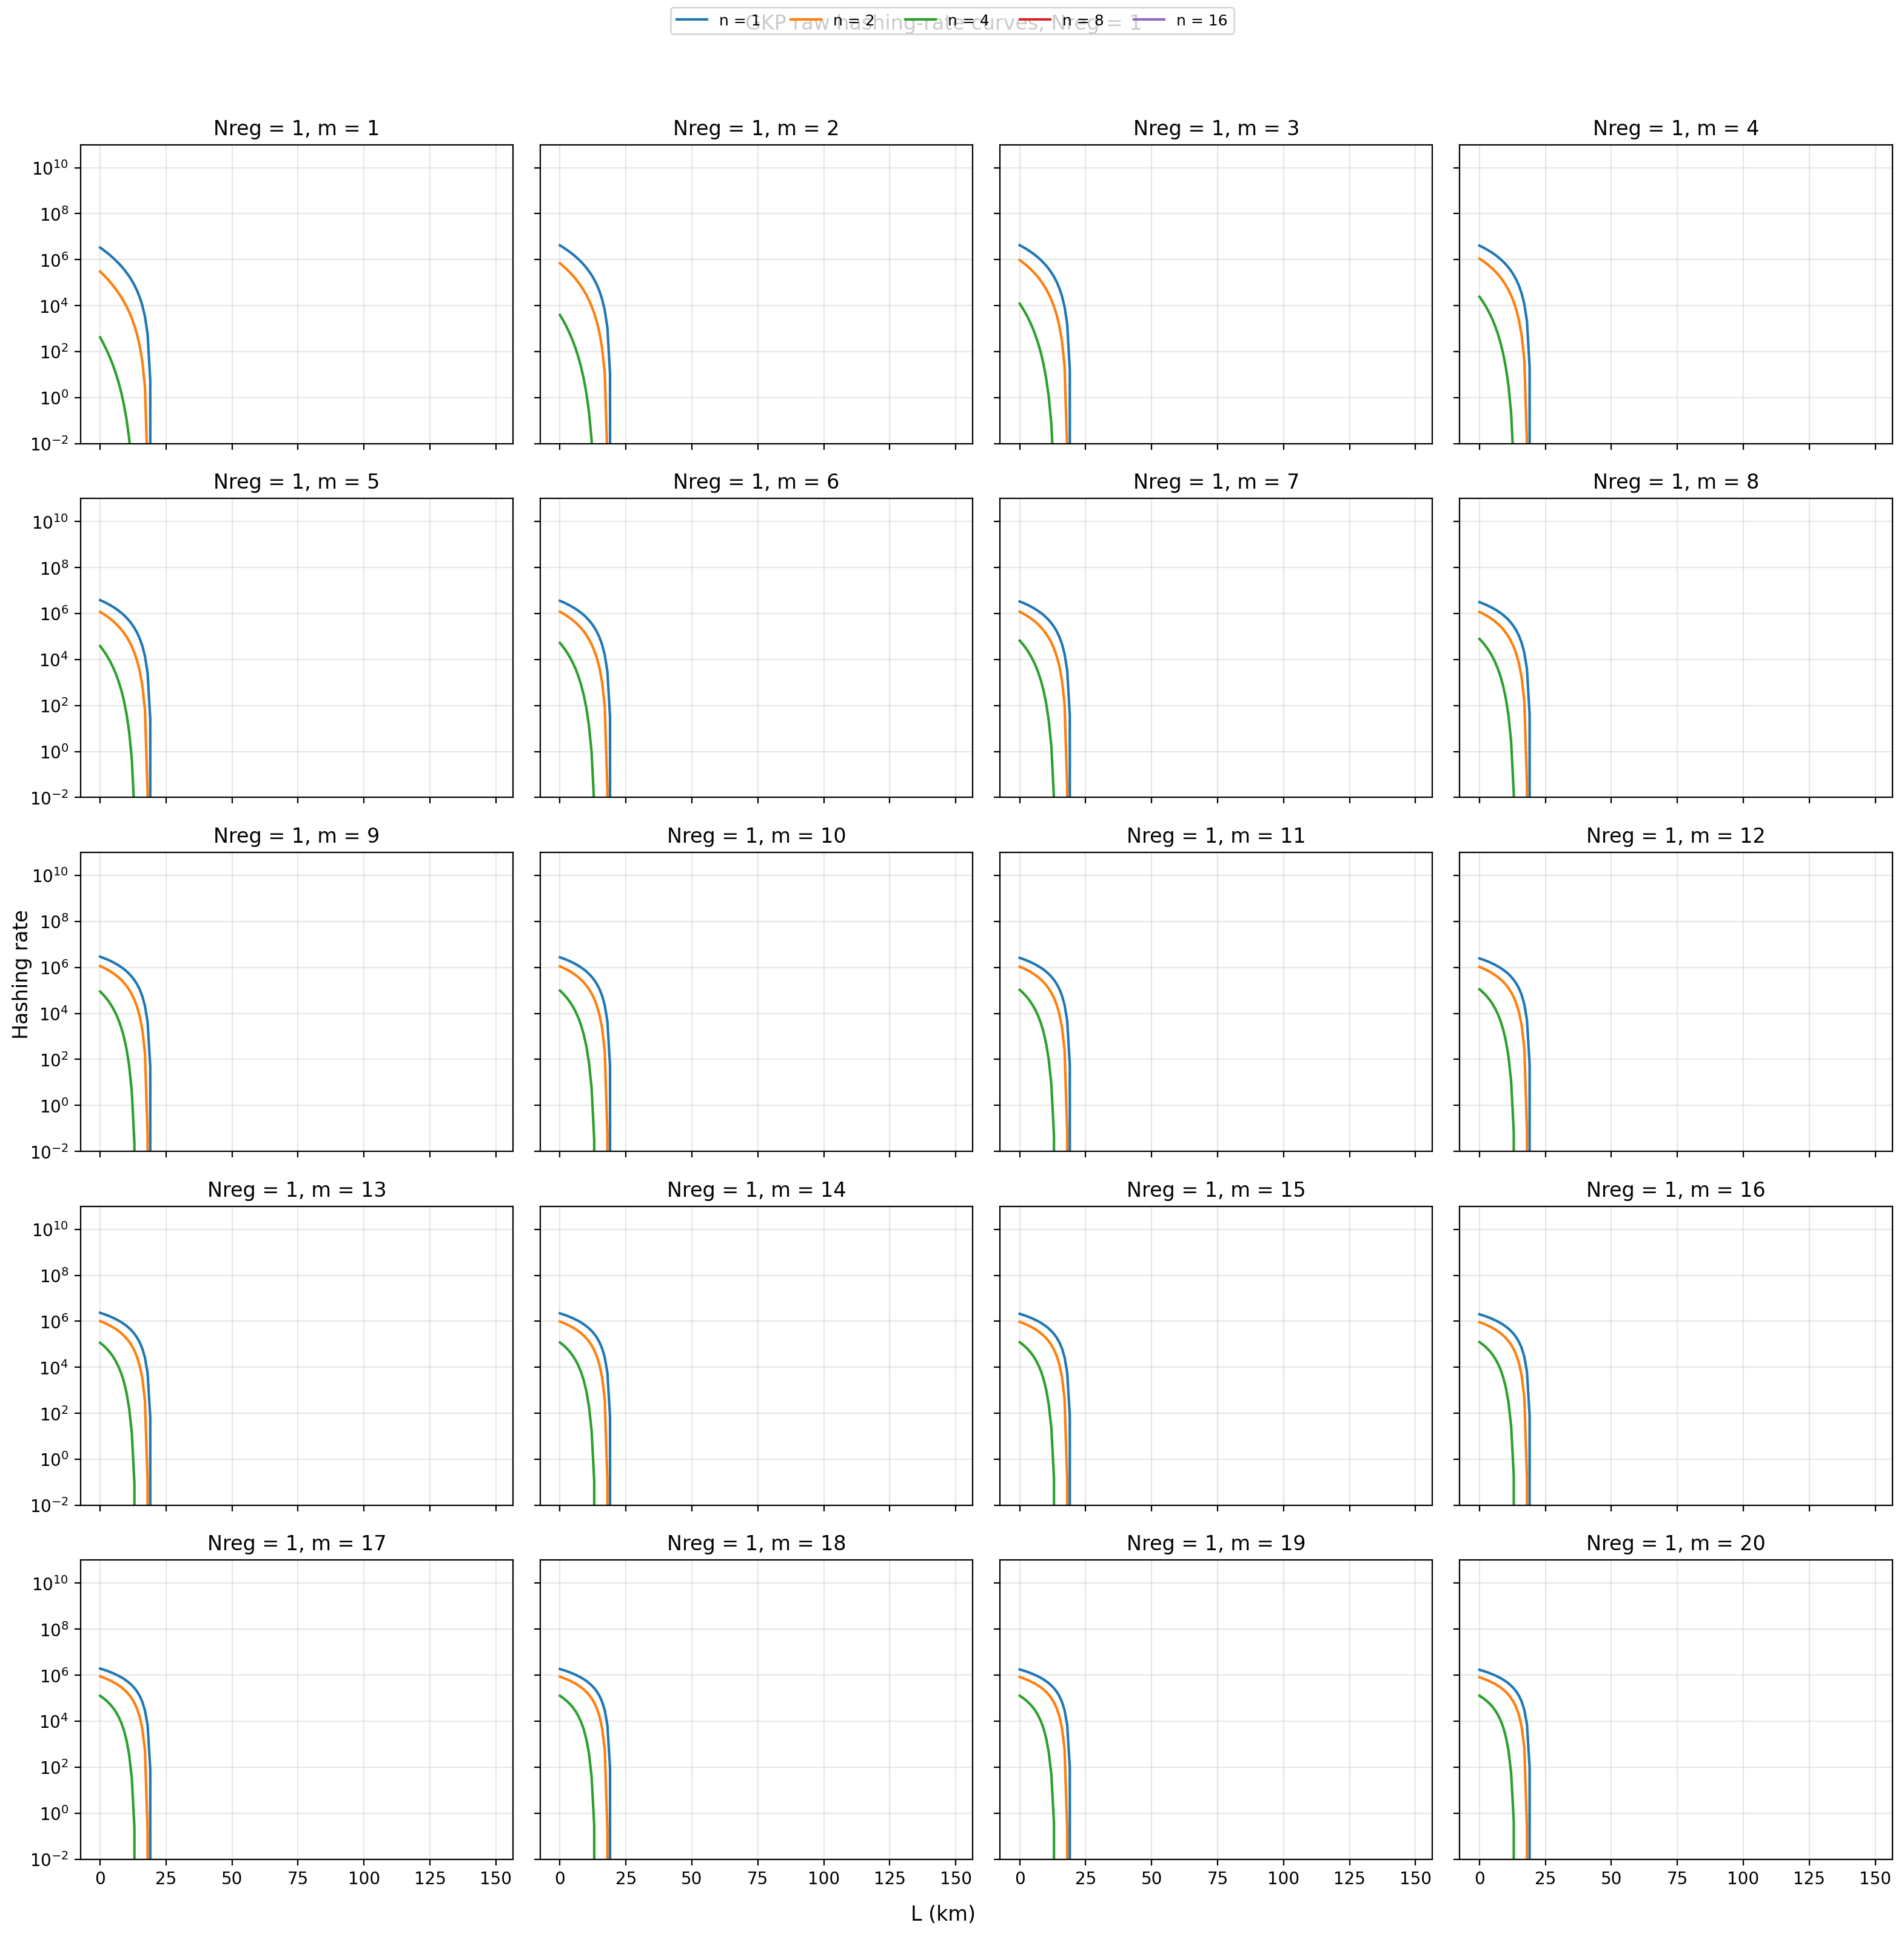


Plotting all m-plots for Nreg = 2


/var/folders/sf/j_bpvxs106x0w5f73qjrvpfh0000gn/T/ipykernel_9096/1687583300.py:32: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale("log")


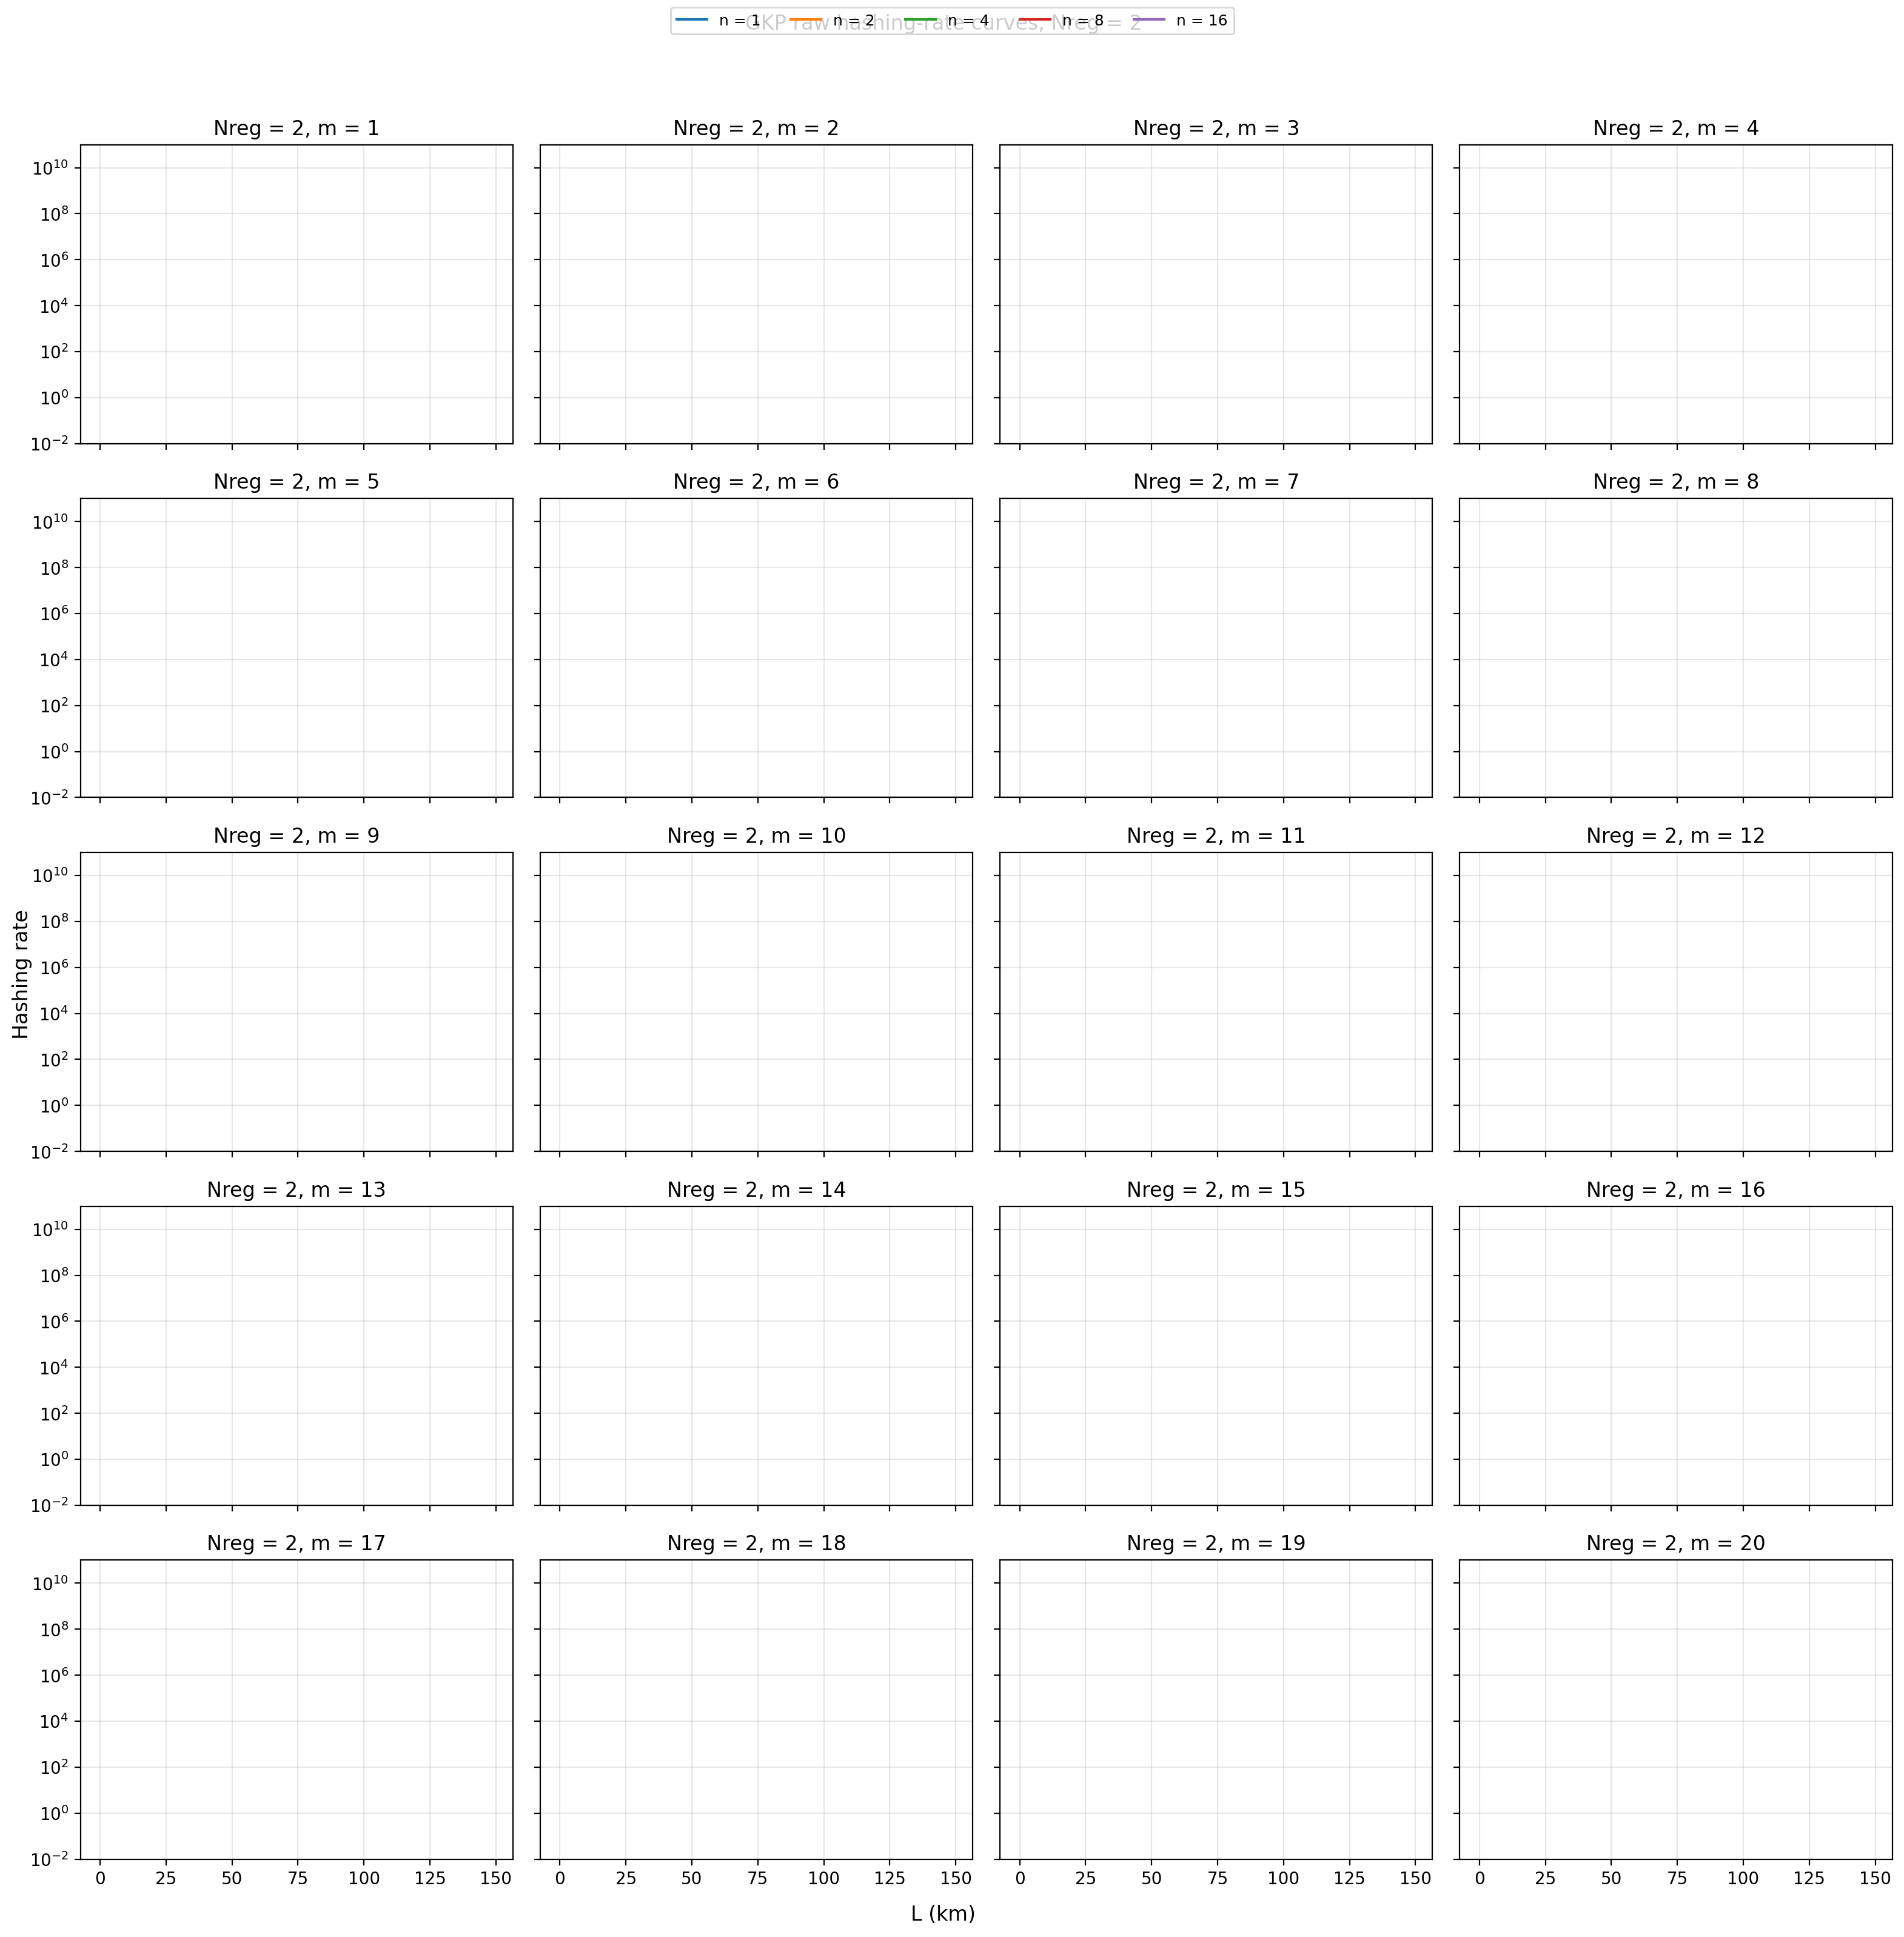


Plotting all m-plots for Nreg = 3


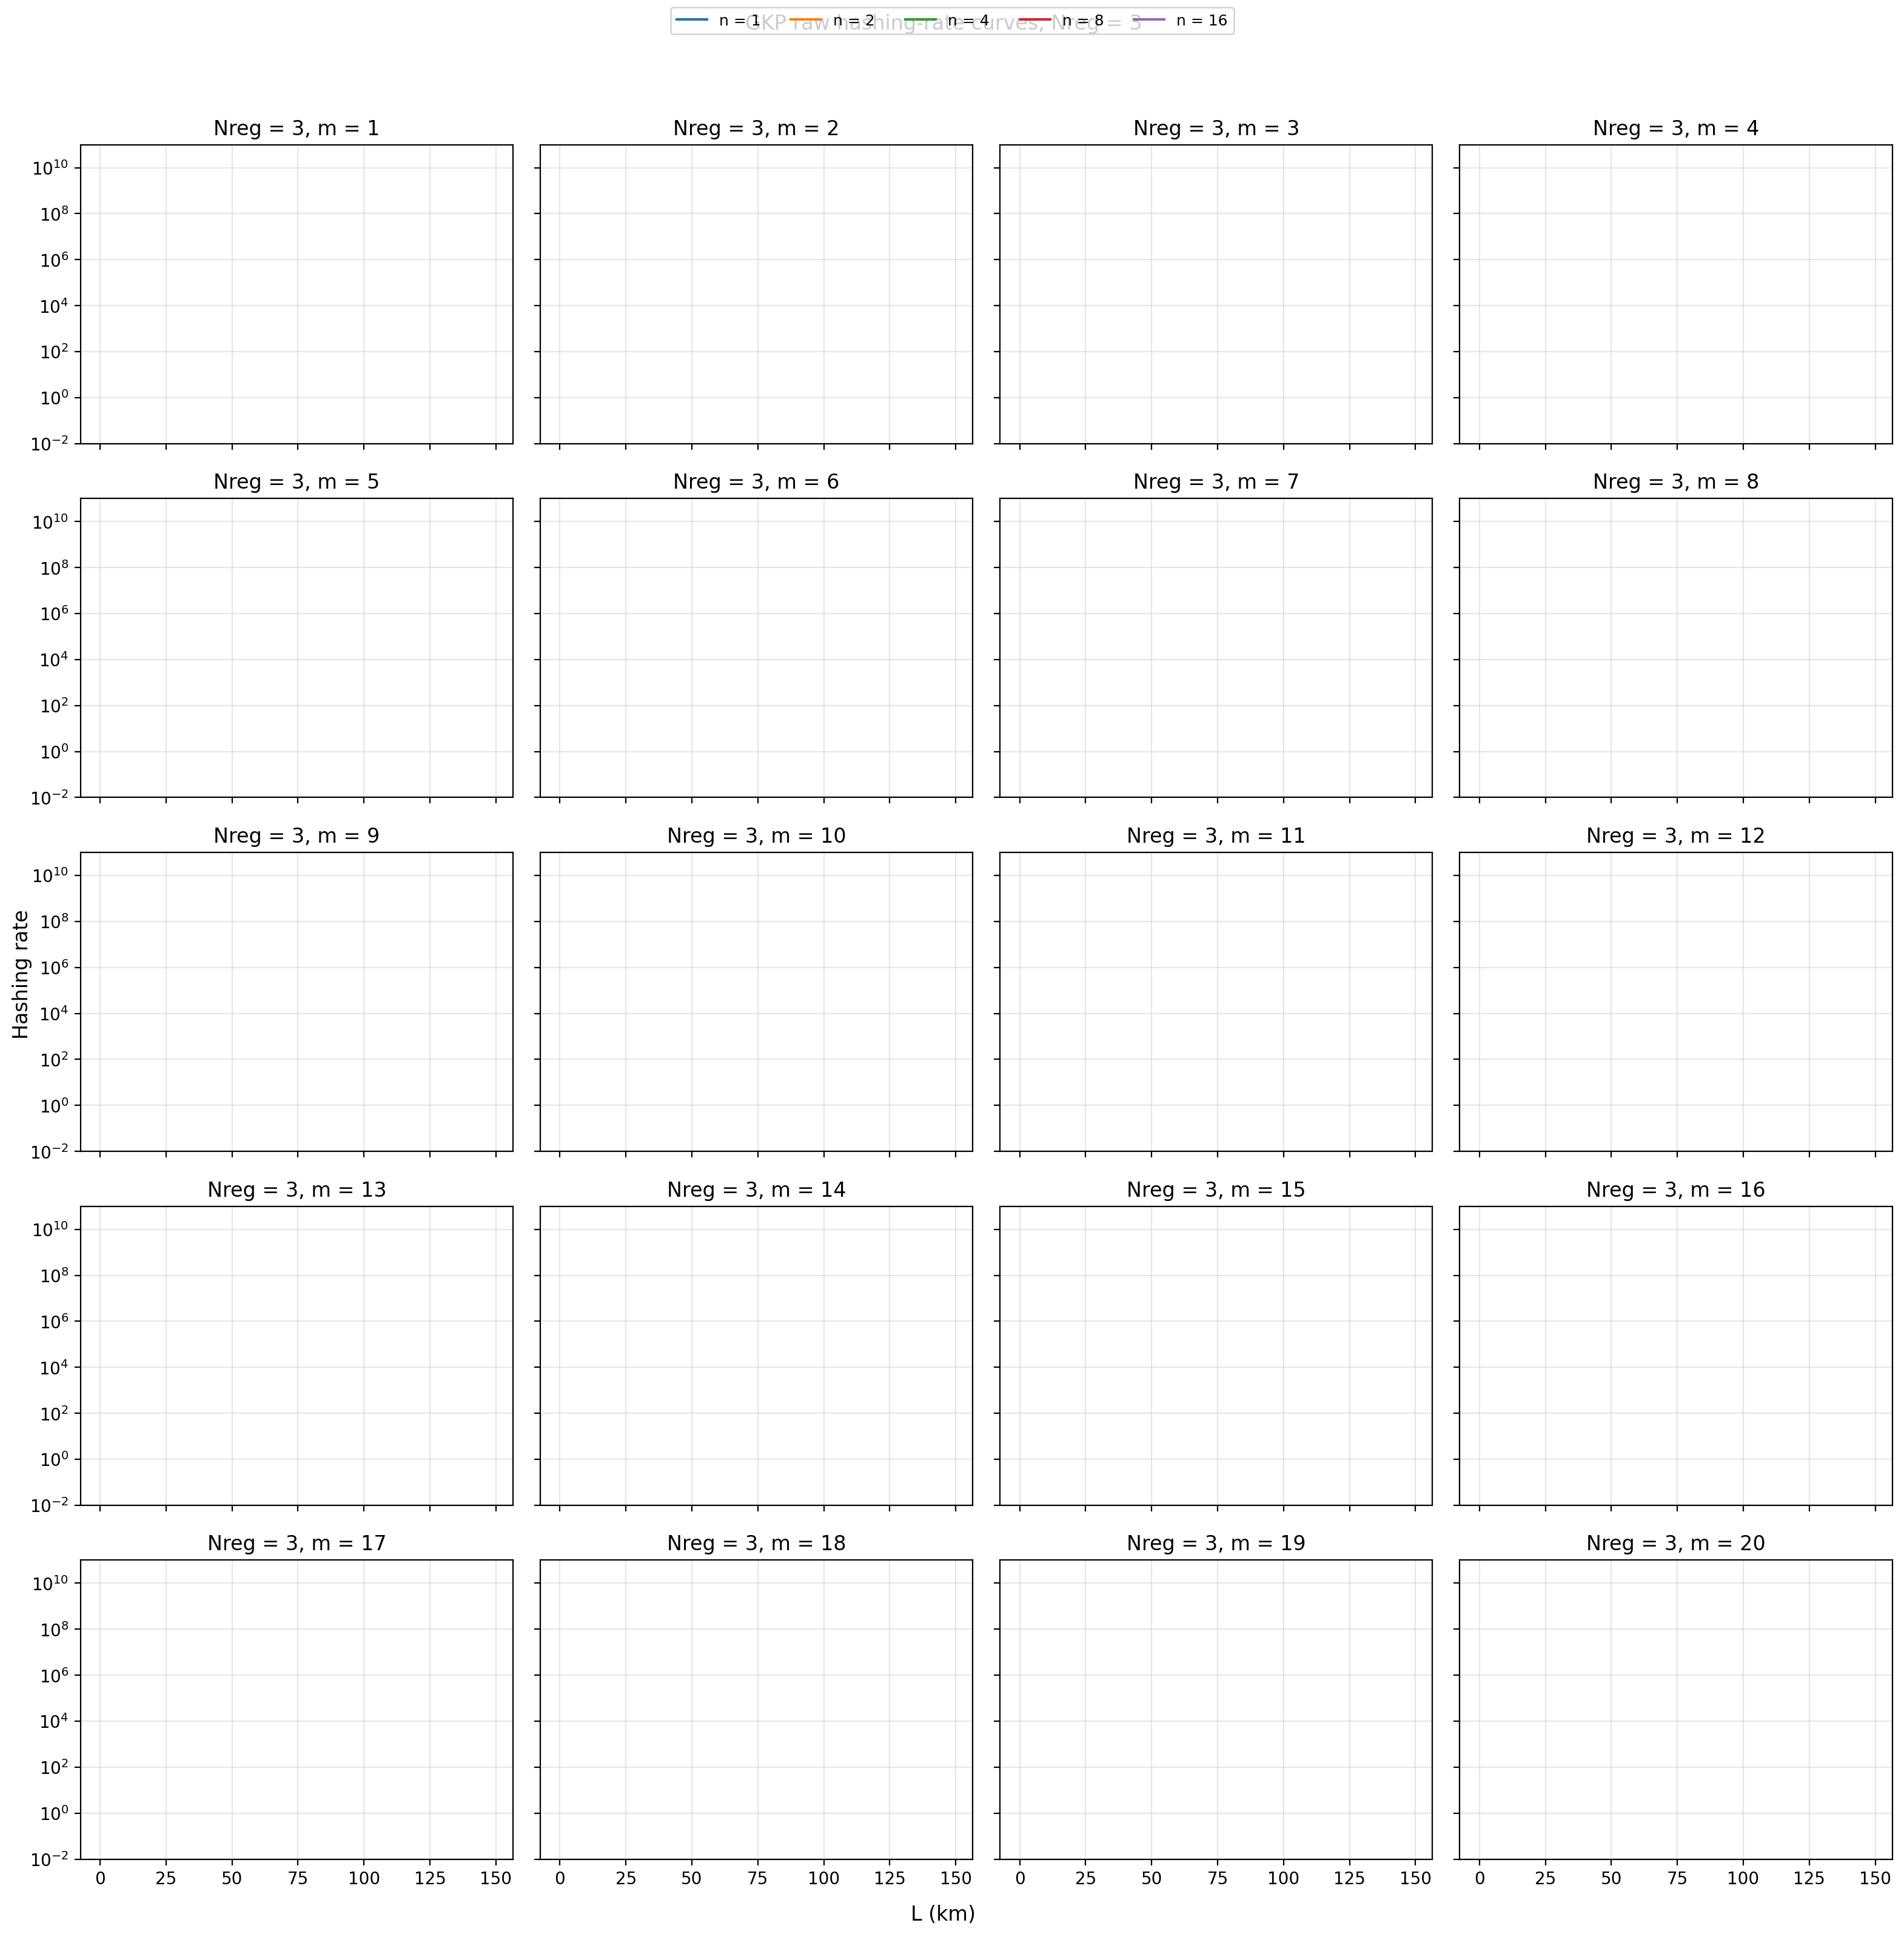


Plotting all m-plots for Nreg = 4


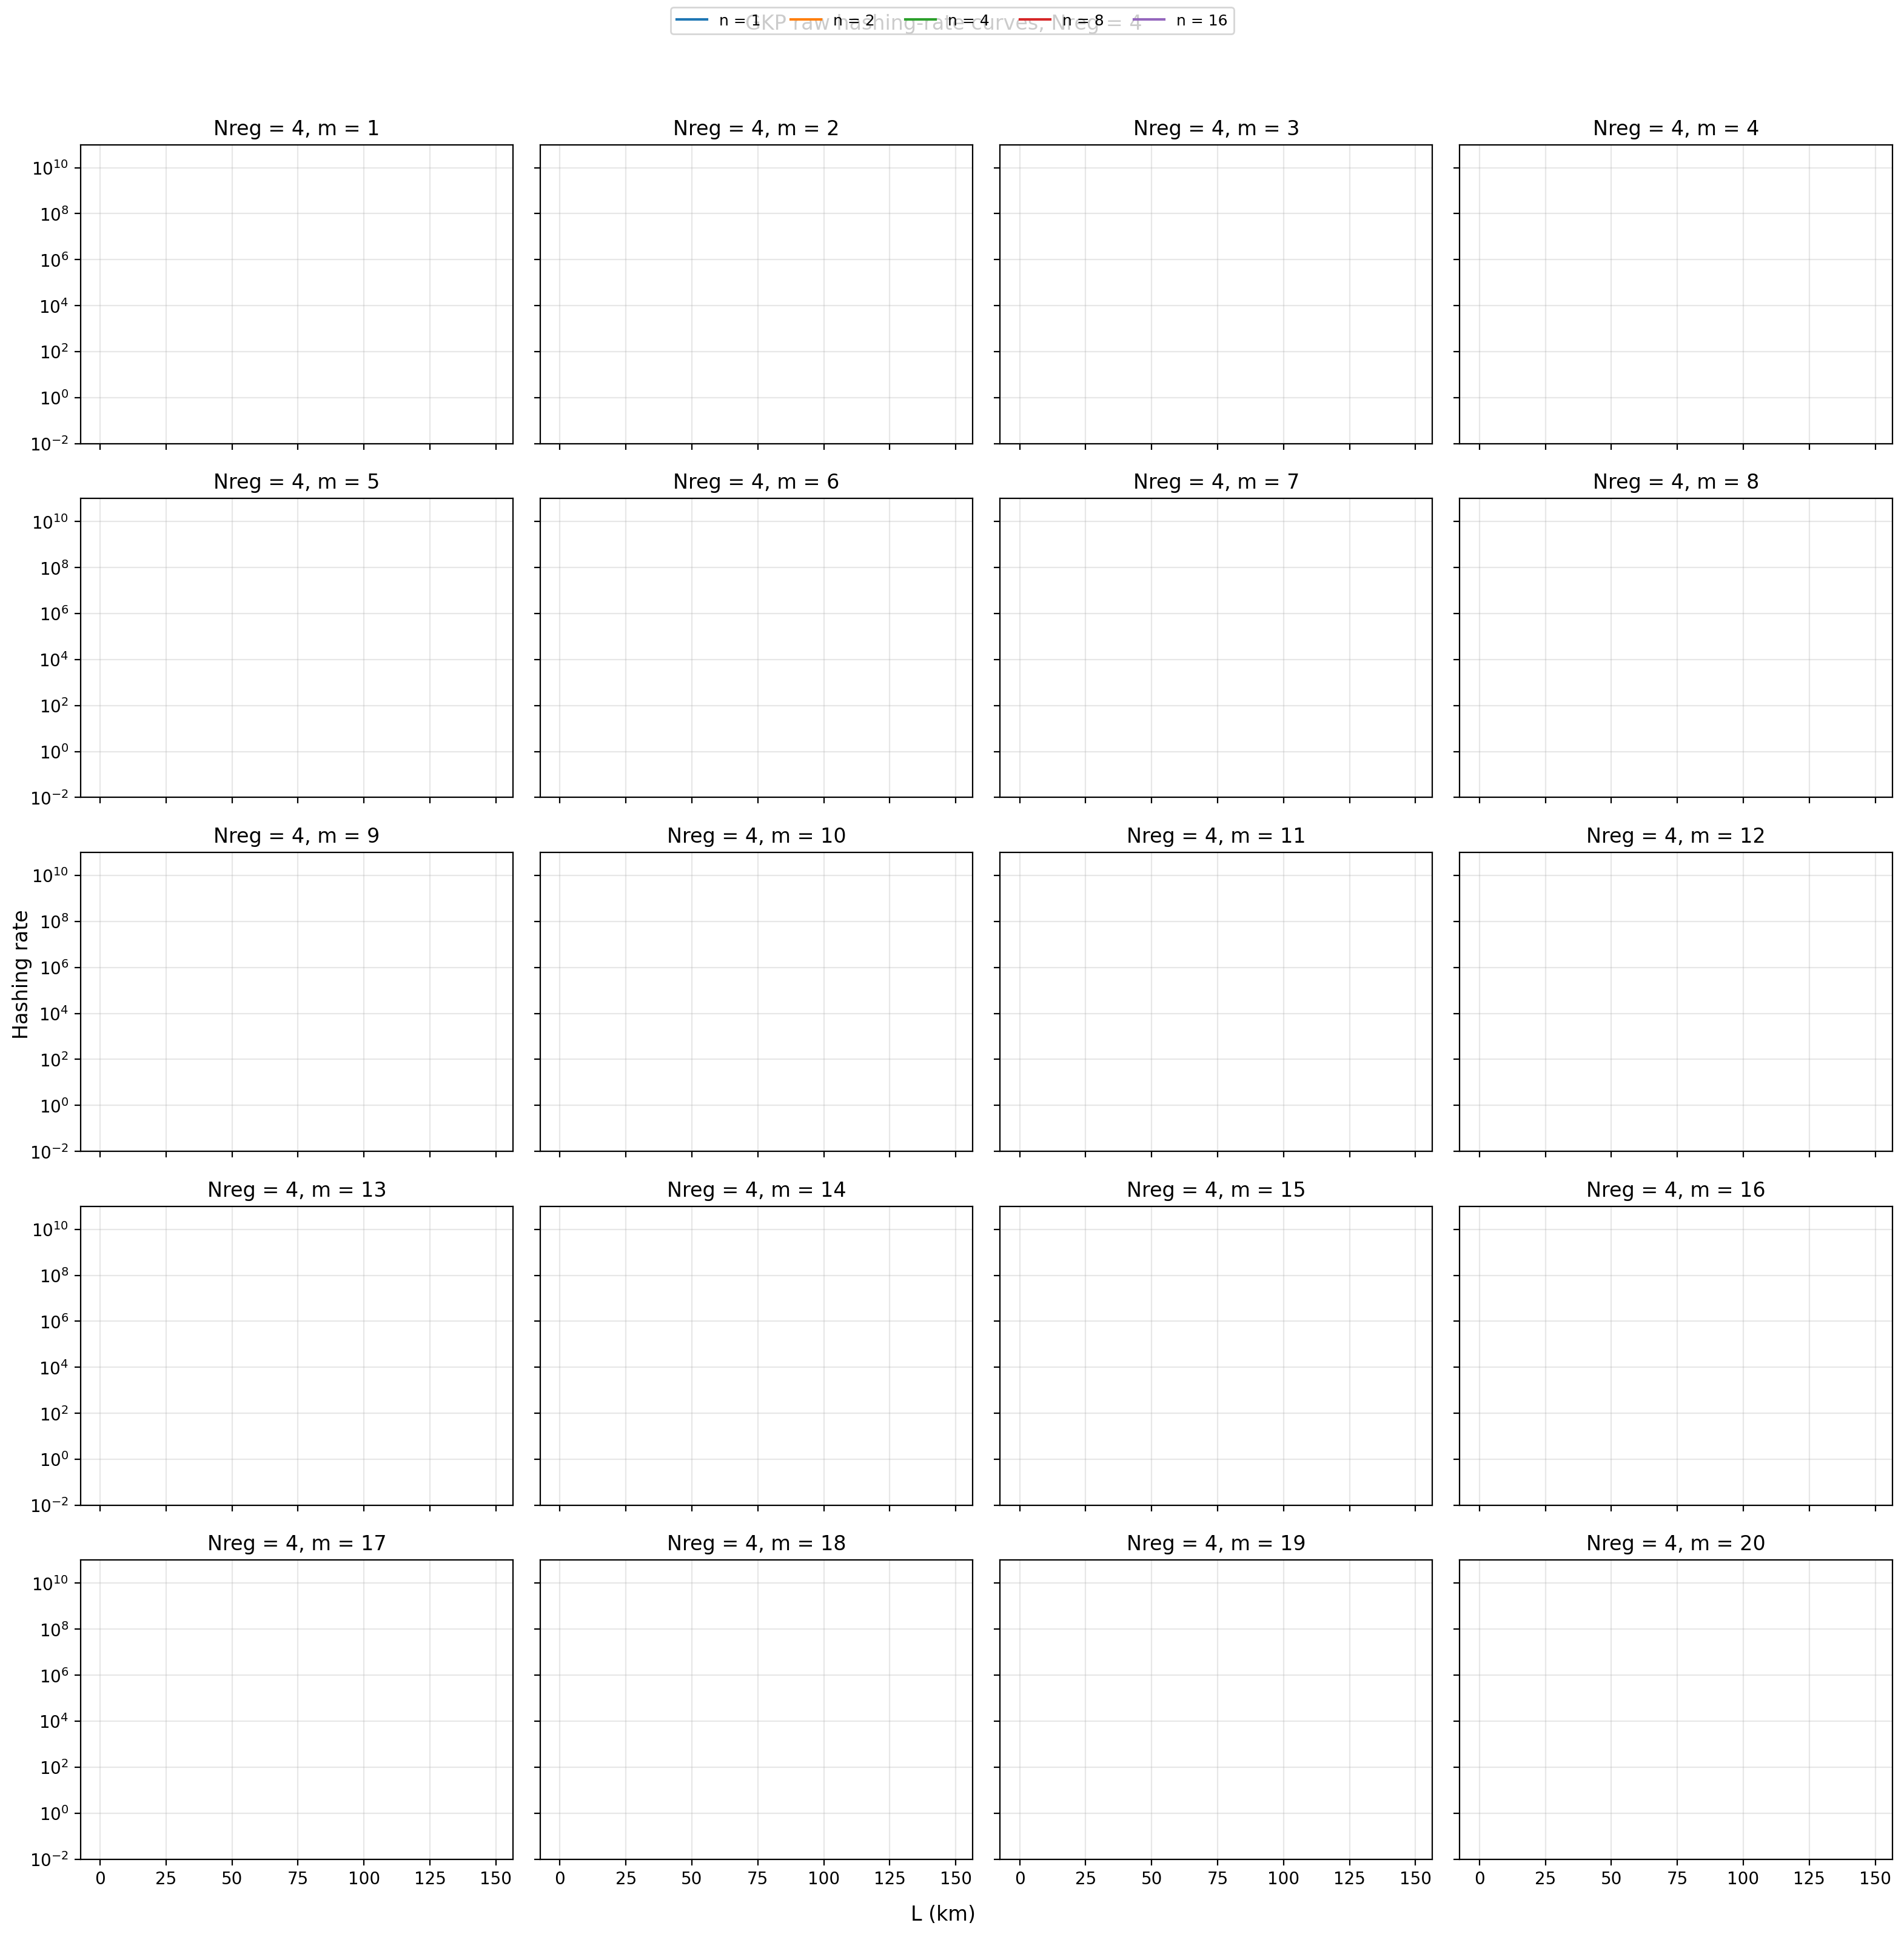


Plotting all m-plots for Nreg = 5


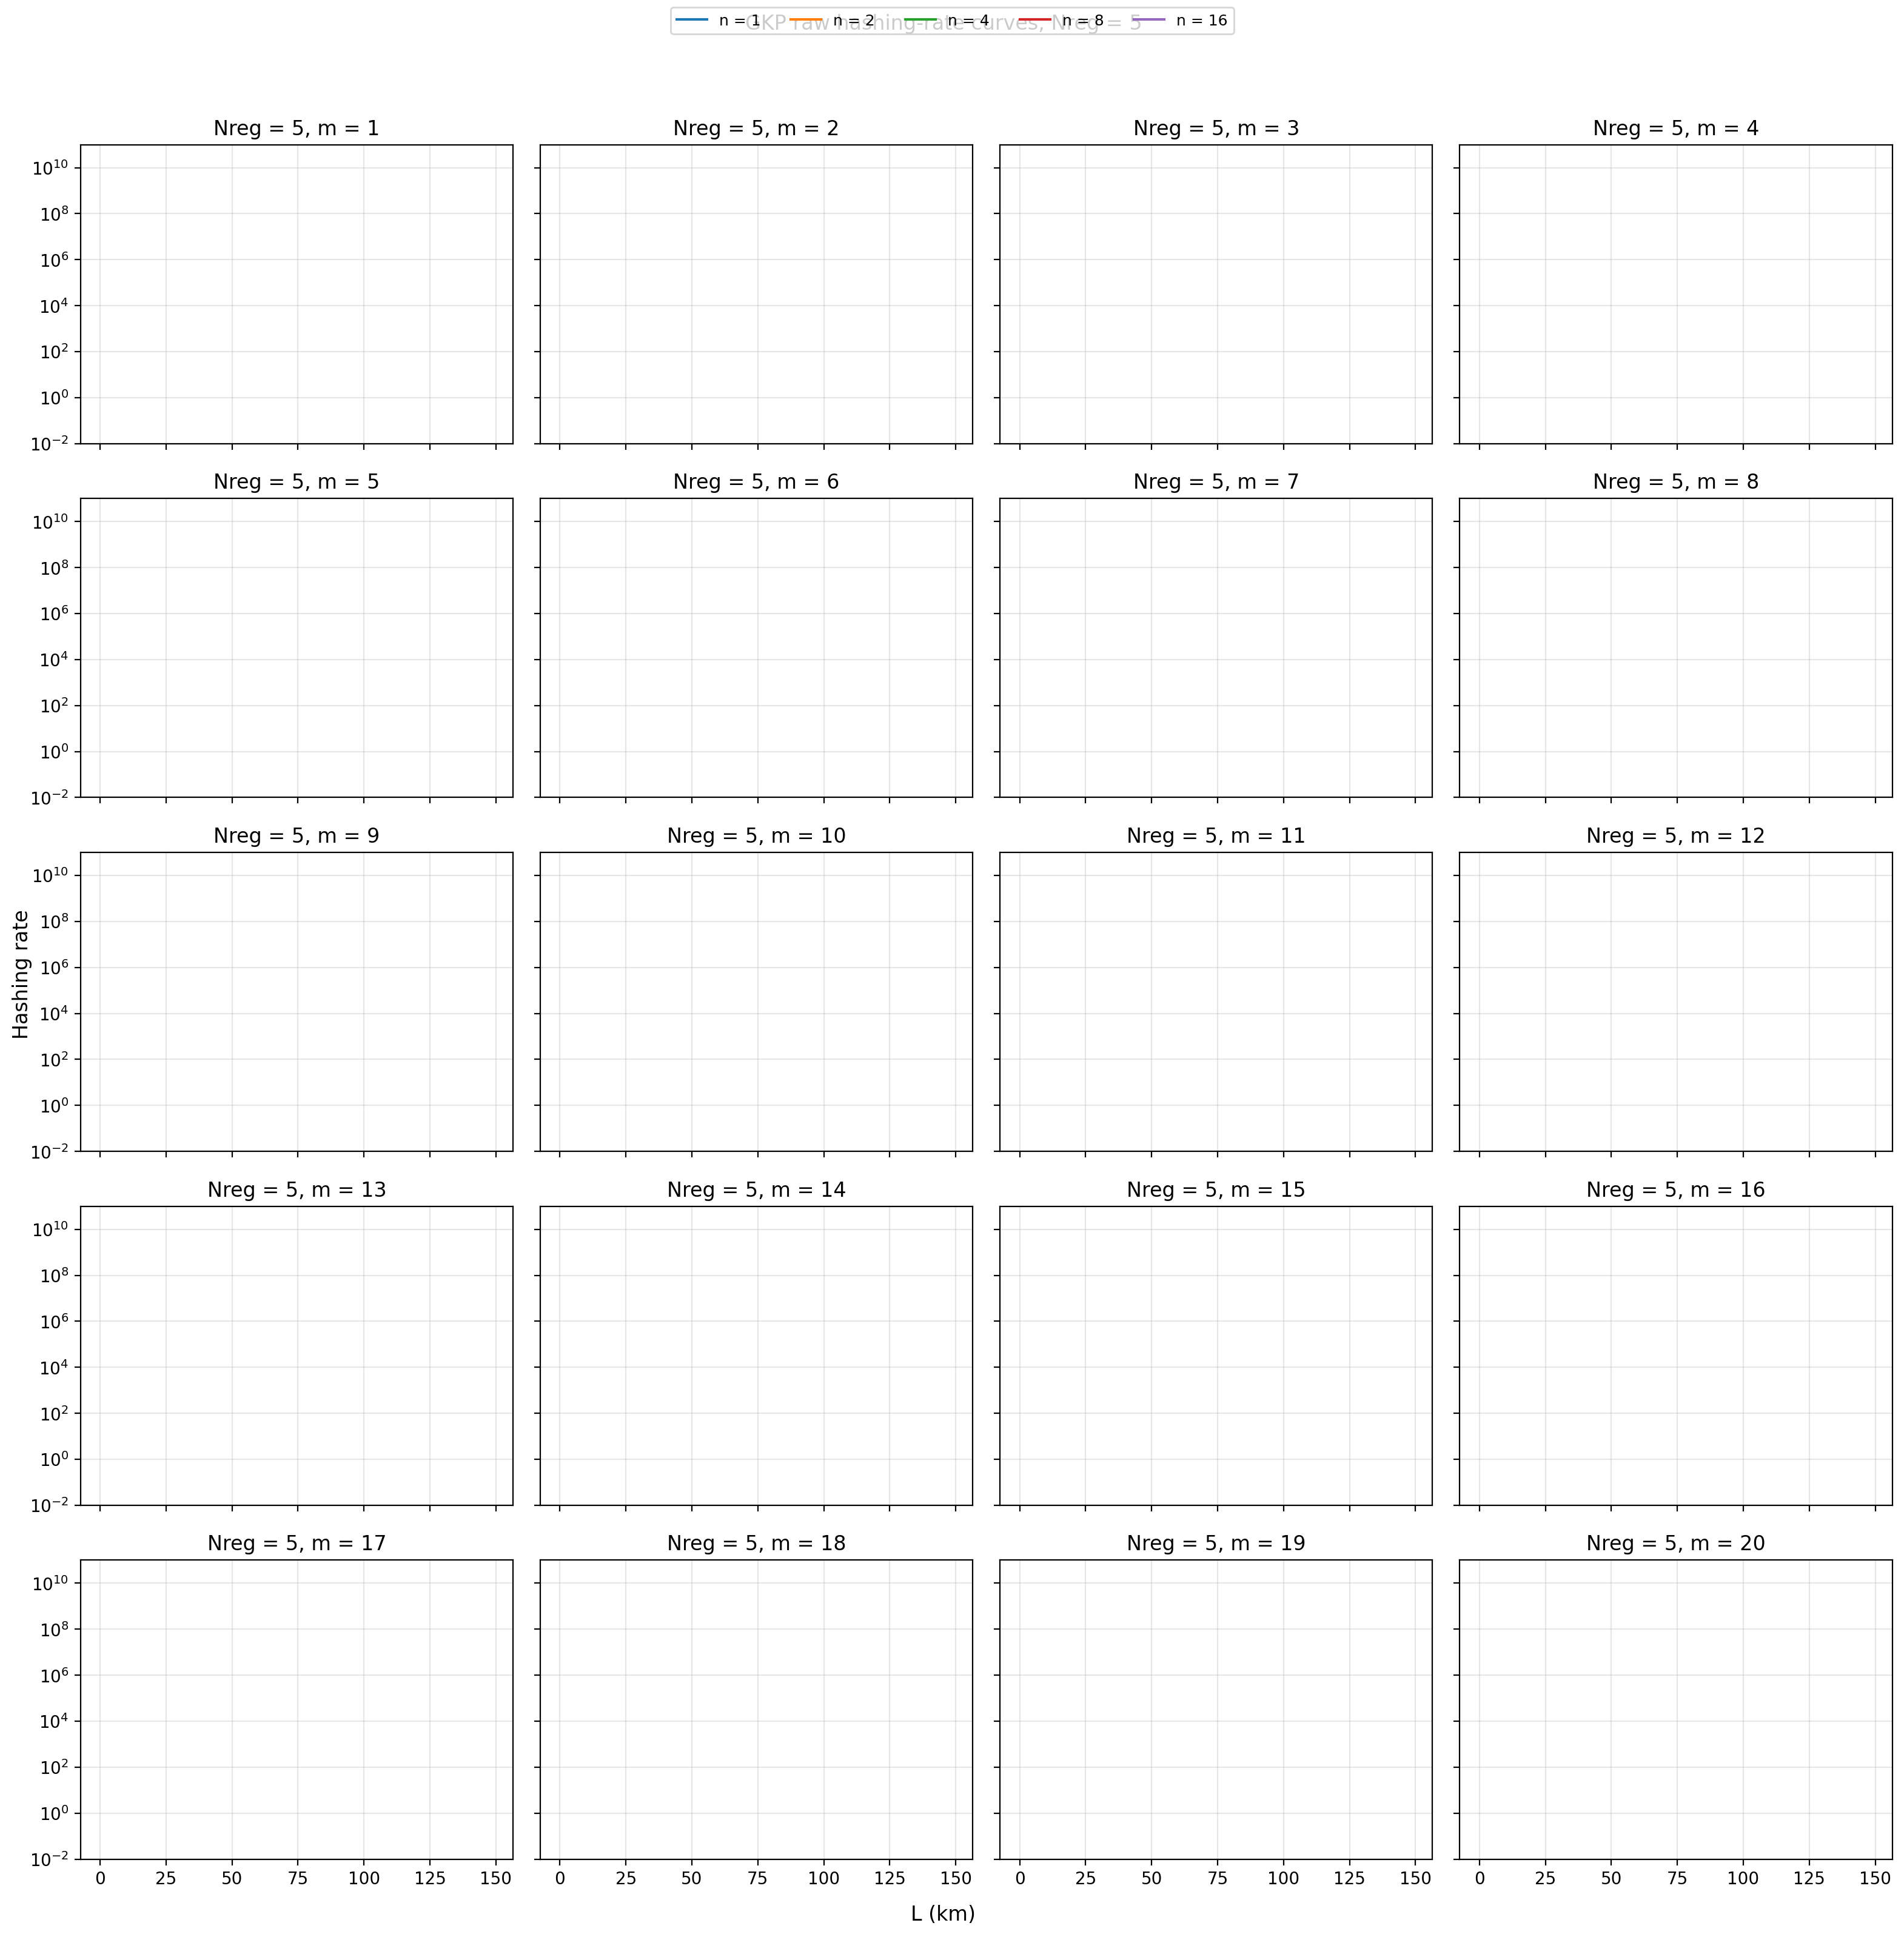


Plotting all m-plots for Nreg = 6


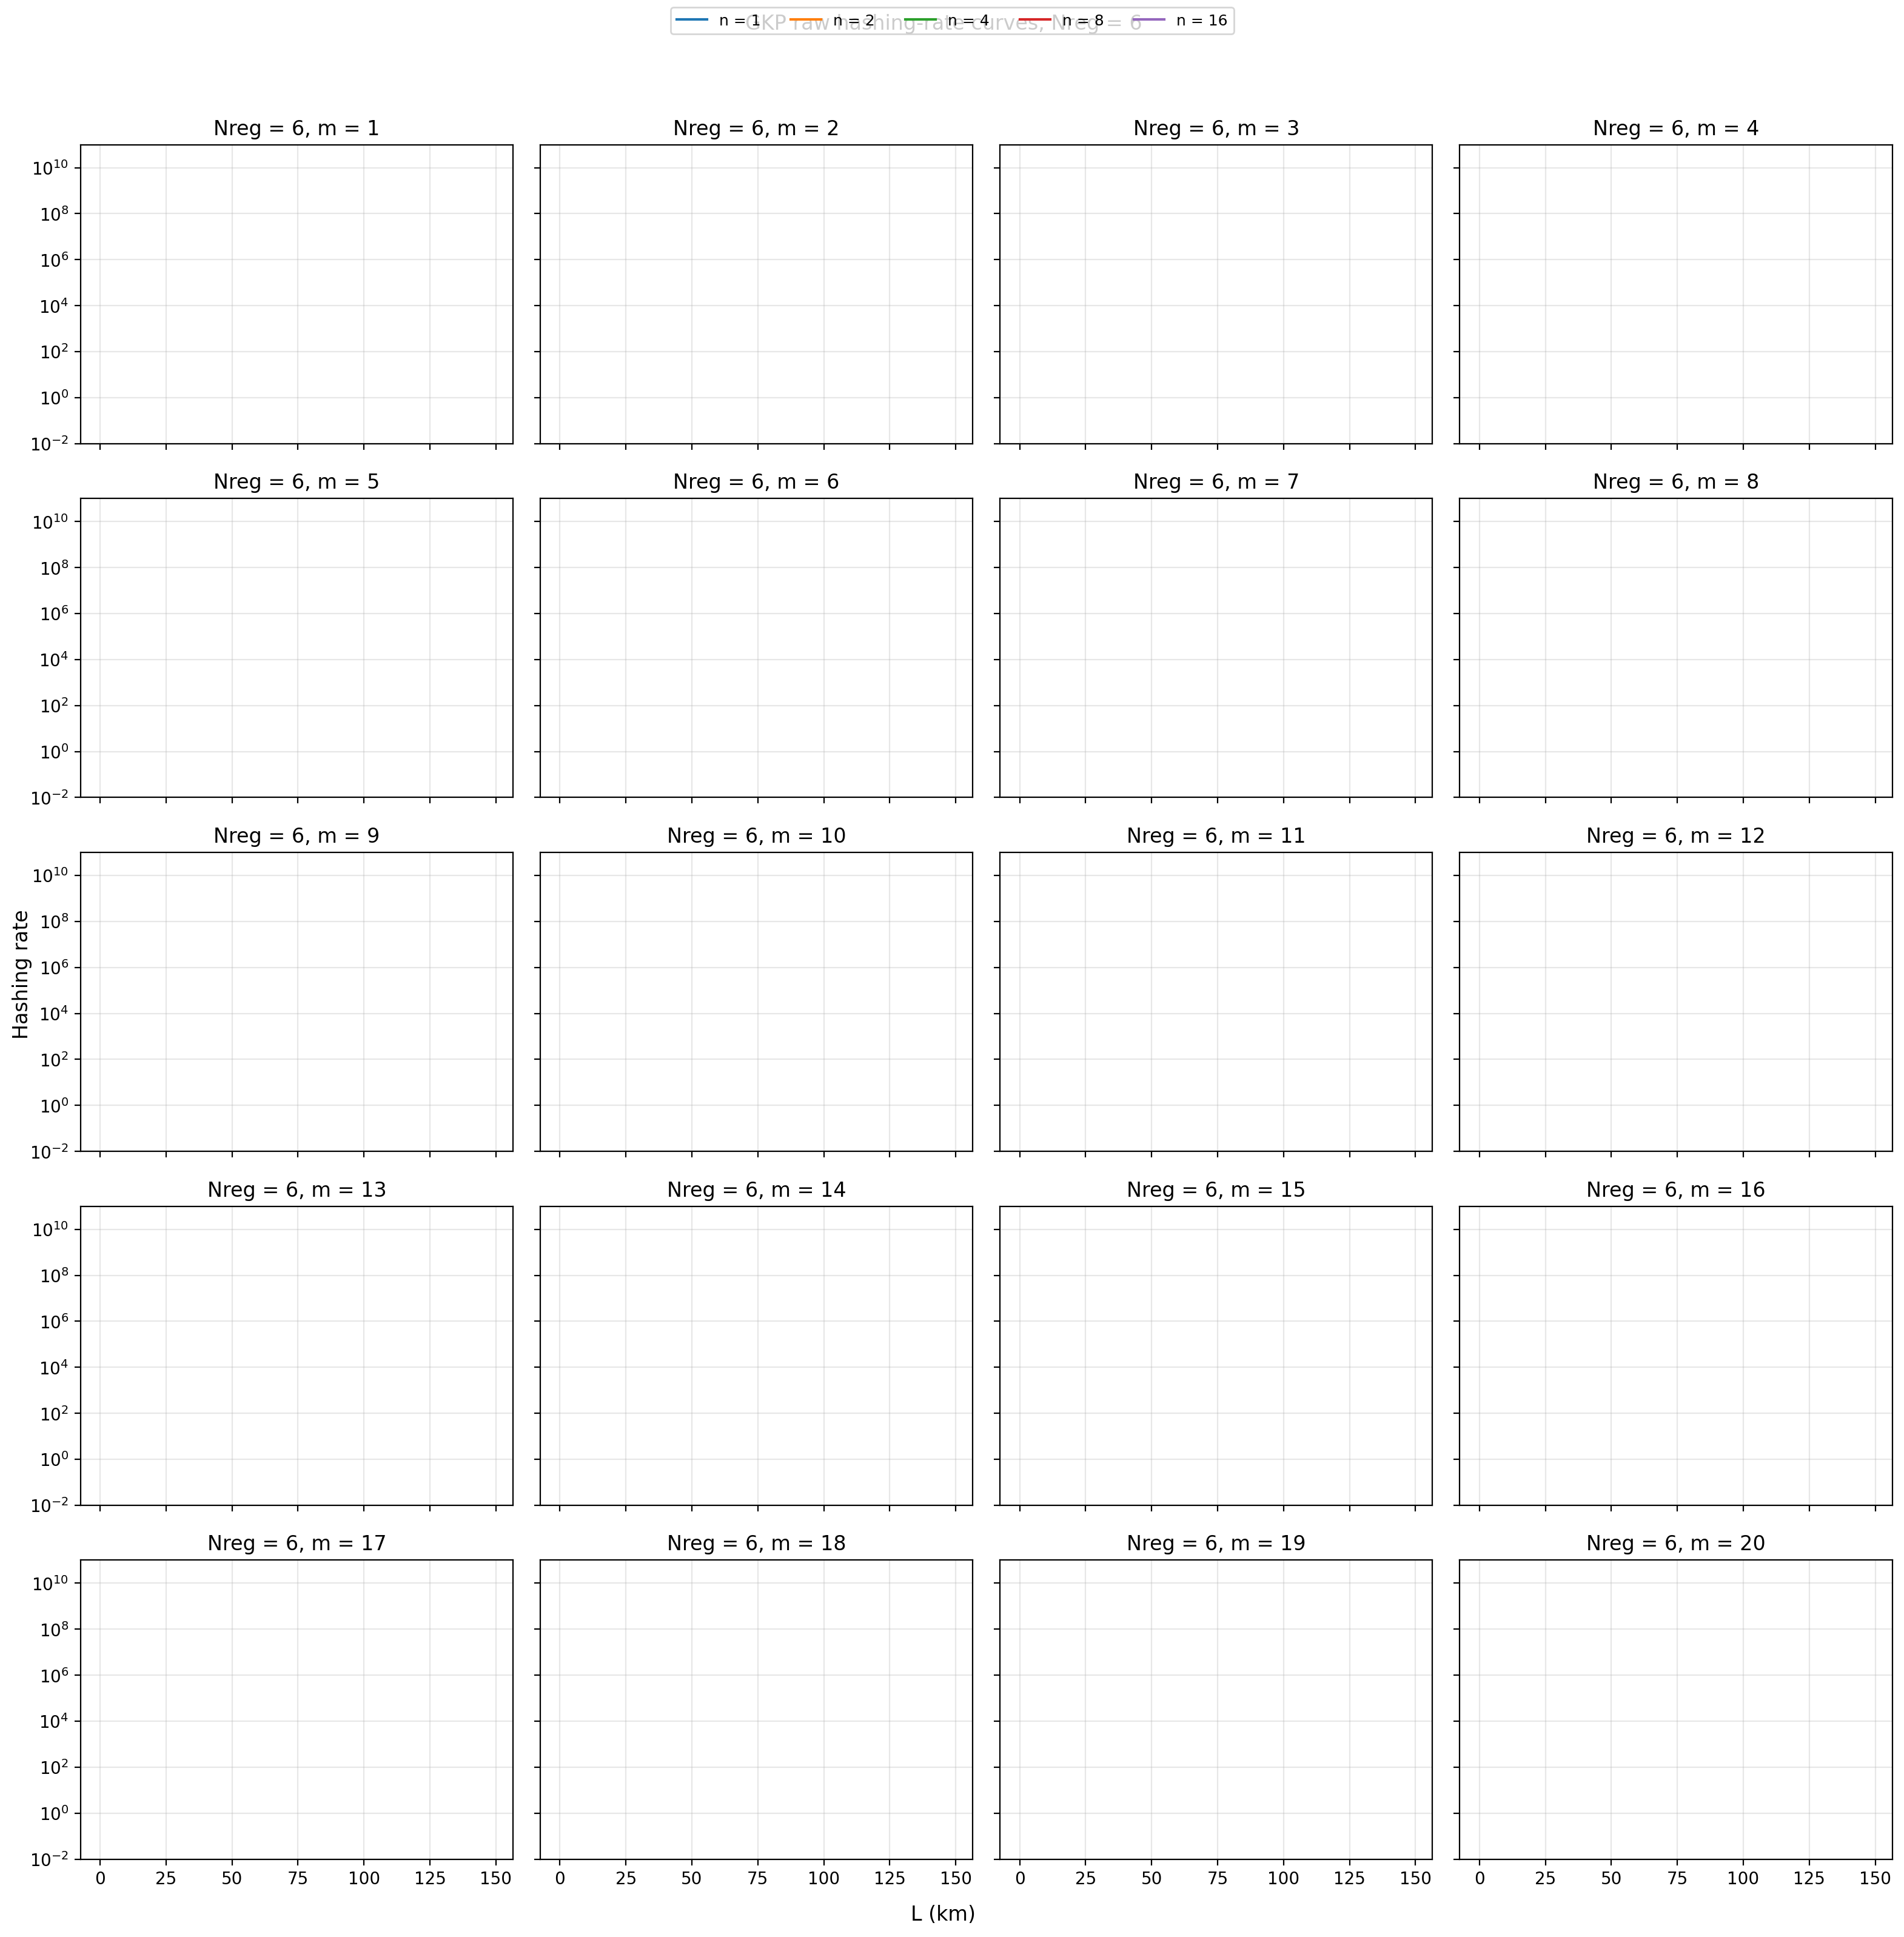


Plotting all m-plots for Nreg = 7


KeyError: np.int64(10)

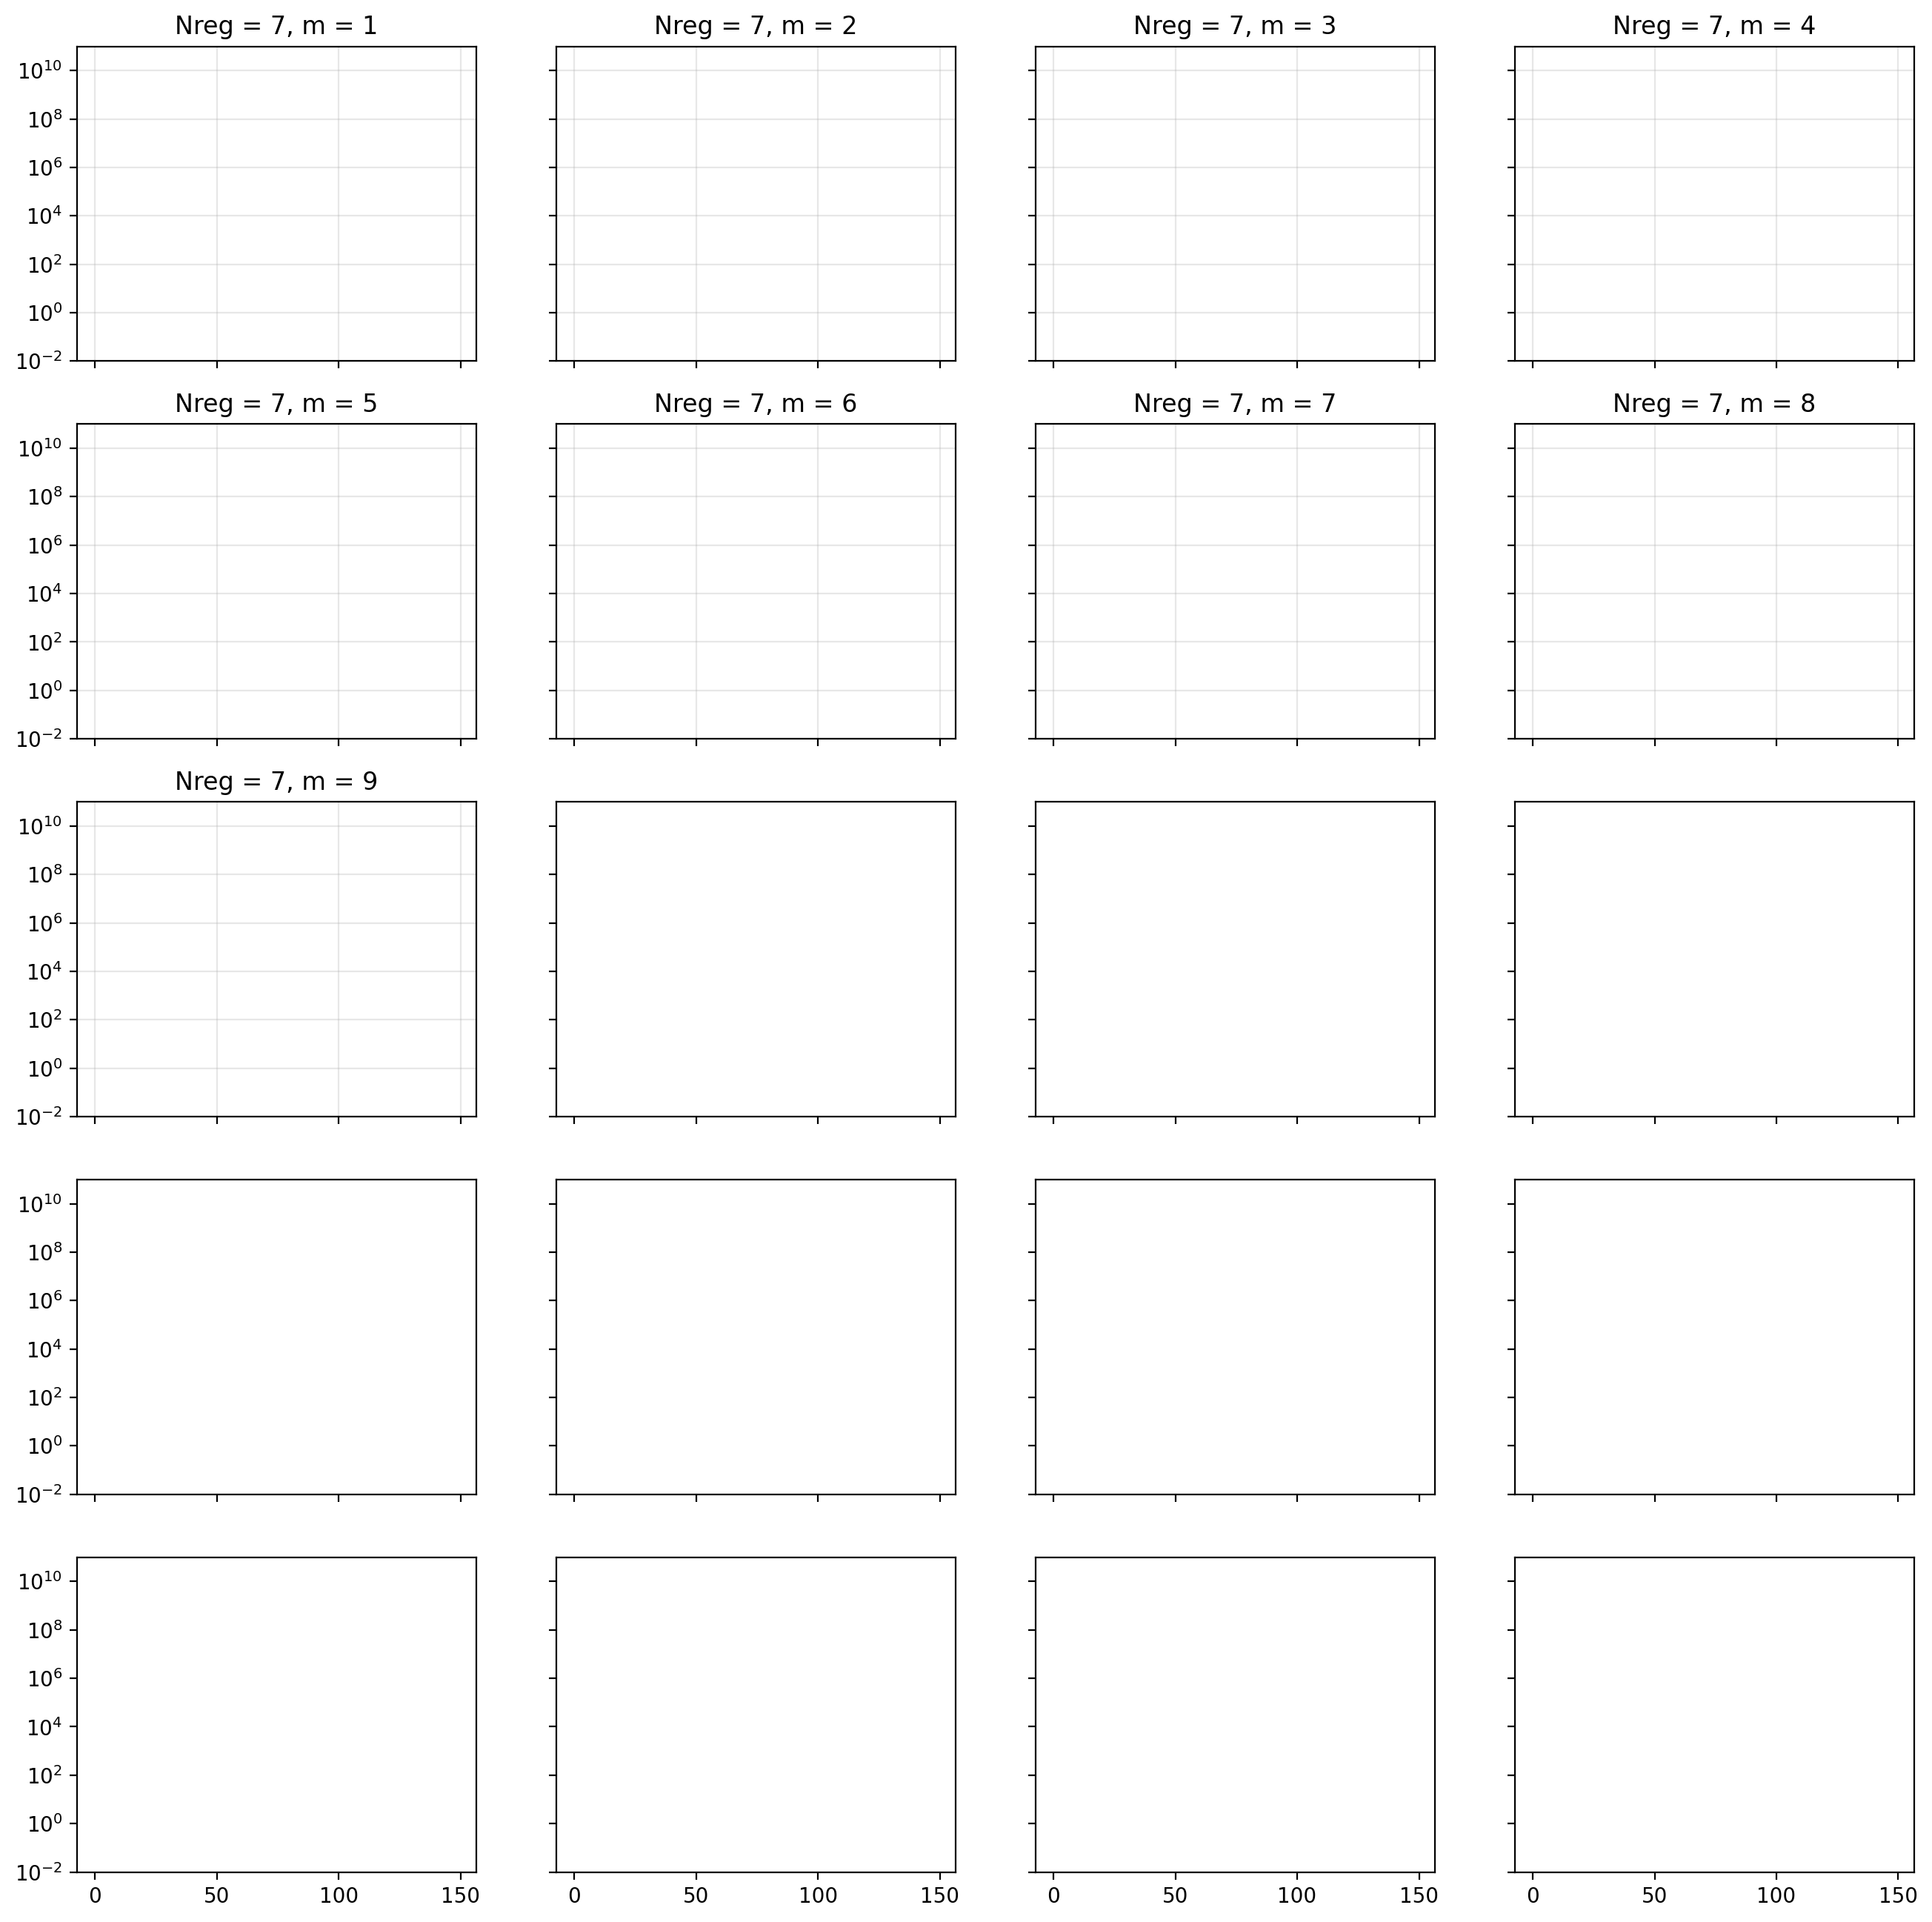

In [13]:
# ----------------------------
# Plot all 20 m-plots for each Nreg
# ----------------------------
for Nreg in Nreg_values:
    print(f"\nPlotting all m-plots for Nreg = {Nreg}")

    nplots = len(m_values)
    ncols = 4
    nrows = int(np.ceil(nplots / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(4 * ncols, 3.2 * nrows),
        dpi=200,
        sharex=True,
        sharey=True,
    )
    axes = np.array(axes).reshape(-1)

    for idx, m in enumerate(m_values):
        ax = axes[idx]
        out = all_results[Nreg][m]

        for n in n_vals:
            ax.plot(
                out["Ls"],
                out["fixed_n_data"][n]["rate"],
                label=f"n = {n}"
            )

        ax.set_yscale("log")
        ax.set_ylim(bottom = 1e-2 , top = 1e11)
        ax.set_title(f"Nreg = {Nreg}, m = {m}")
        ax.grid(True, which="both", alpha=0.3)

    # turn off unused subplots
    for j in range(nplots, len(axes)):
        axes[j].axis("off")

    # one shared legend
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(n_vals), fontsize=9)

    fig.suptitle(f"GKP raw hashing-rate curves, Nreg = {Nreg}", y=0.995)
    fig.supxlabel("L (km)")
    fig.supylabel("Hashing rate")

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    fig_path = os.path.join(output_dir, f"gkp_raw_curves_Nreg_{Nreg}.png")
    plt.savefig(fig_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("\nDone.")

In [ ]:
all_results = np.load(
    "gkp_raw_results.npy",
    allow_pickle=True
).item()

In [ ]:
all_results

# Maximisation over HR curves


Plotting all available m-plots for Nreg = 1


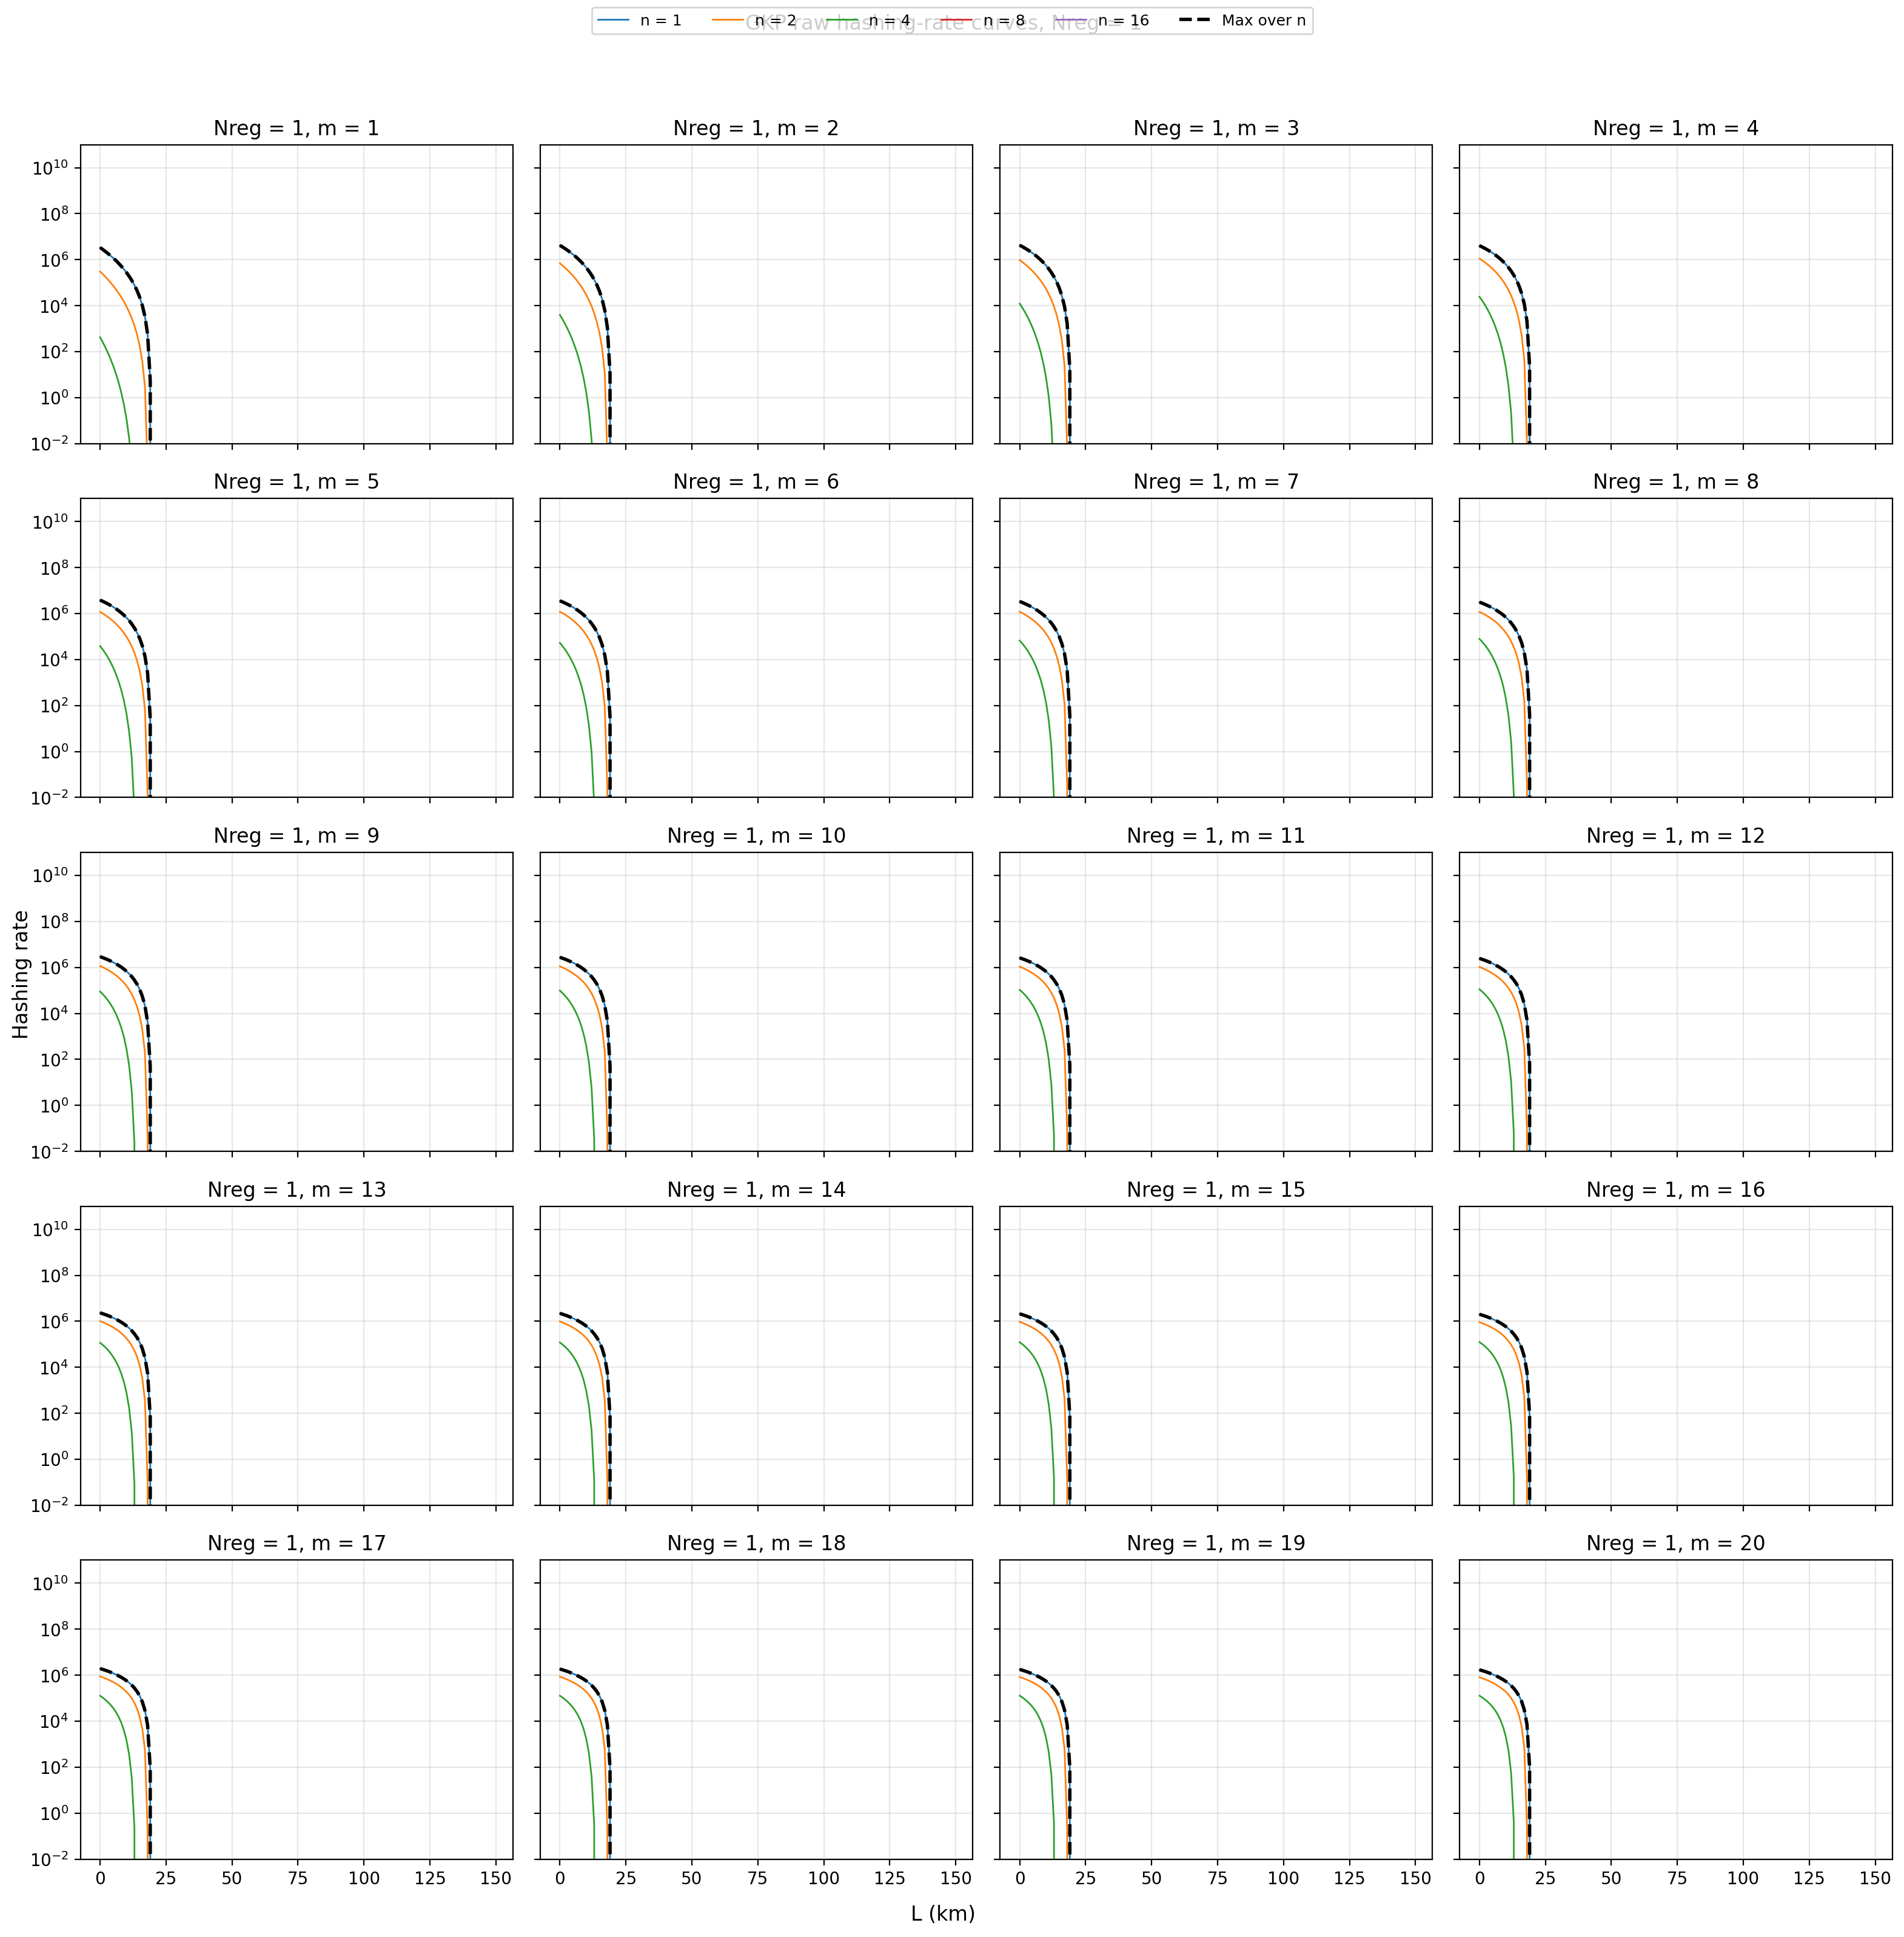


Plotting all available m-plots for Nreg = 2


/var/folders/sf/j_bpvxs106x0w5f73qjrvpfh0000gn/T/ipykernel_9096/3877607531.py:57: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale("log")


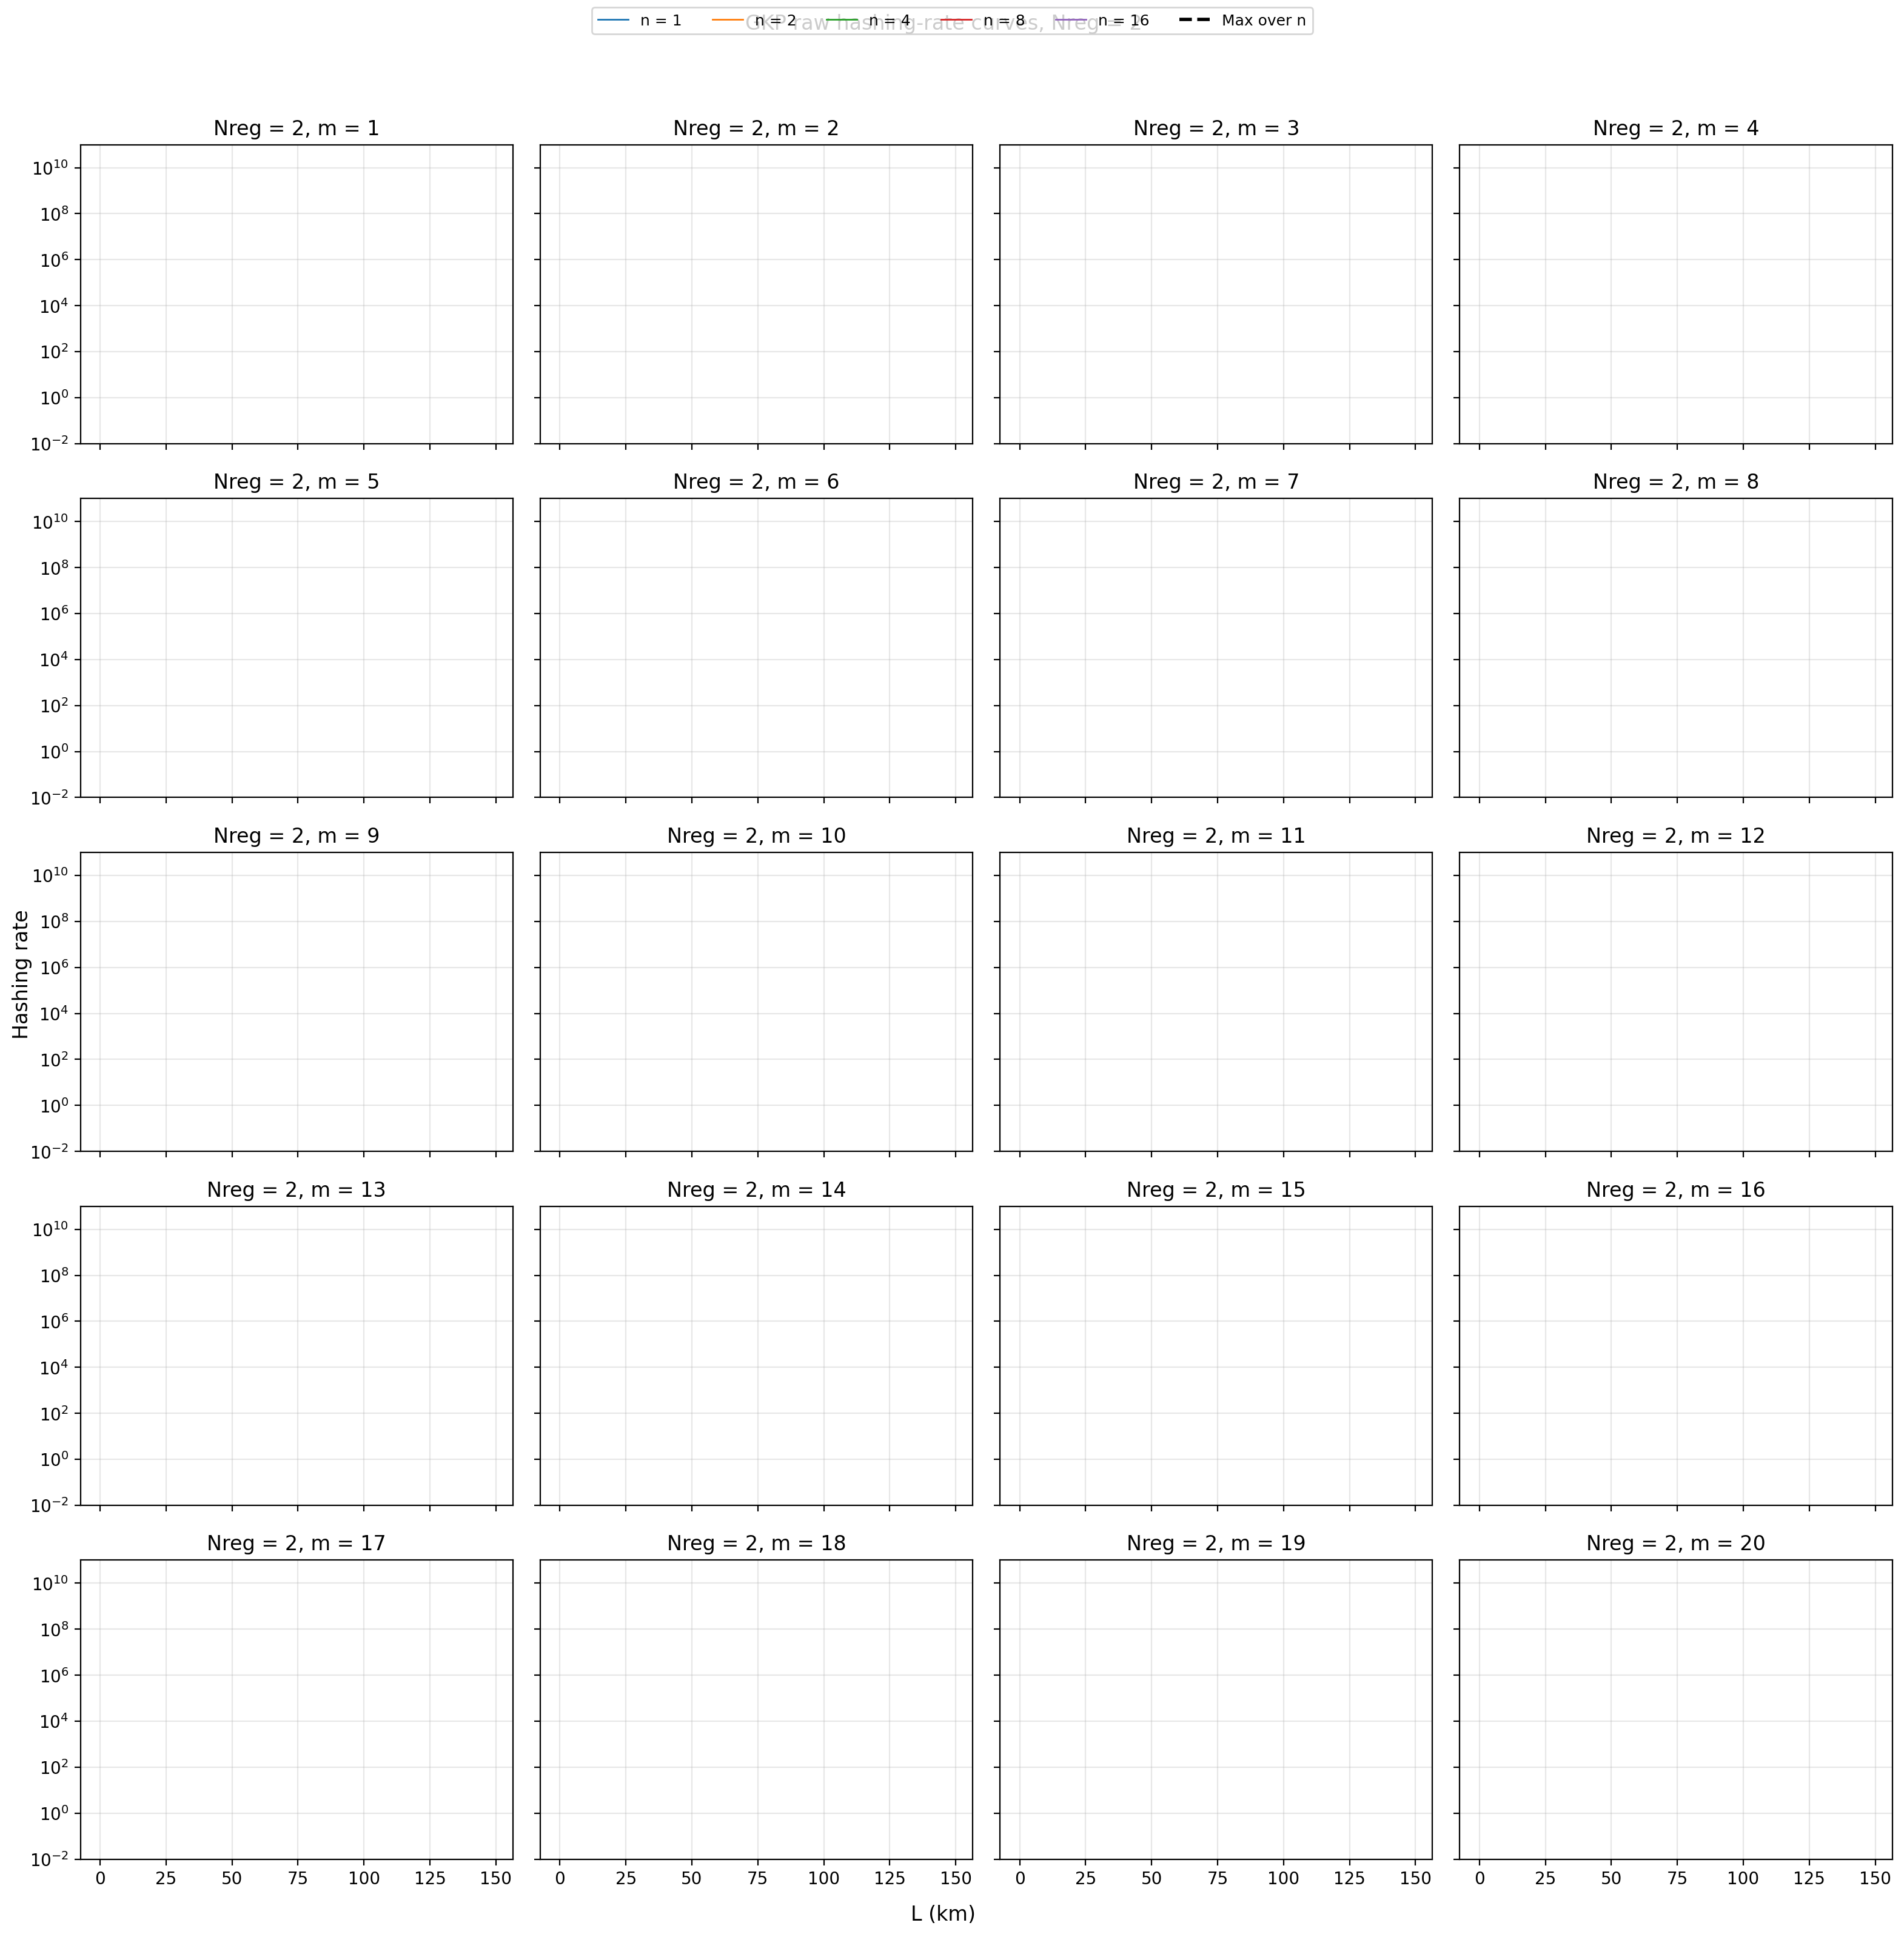


Plotting all available m-plots for Nreg = 3


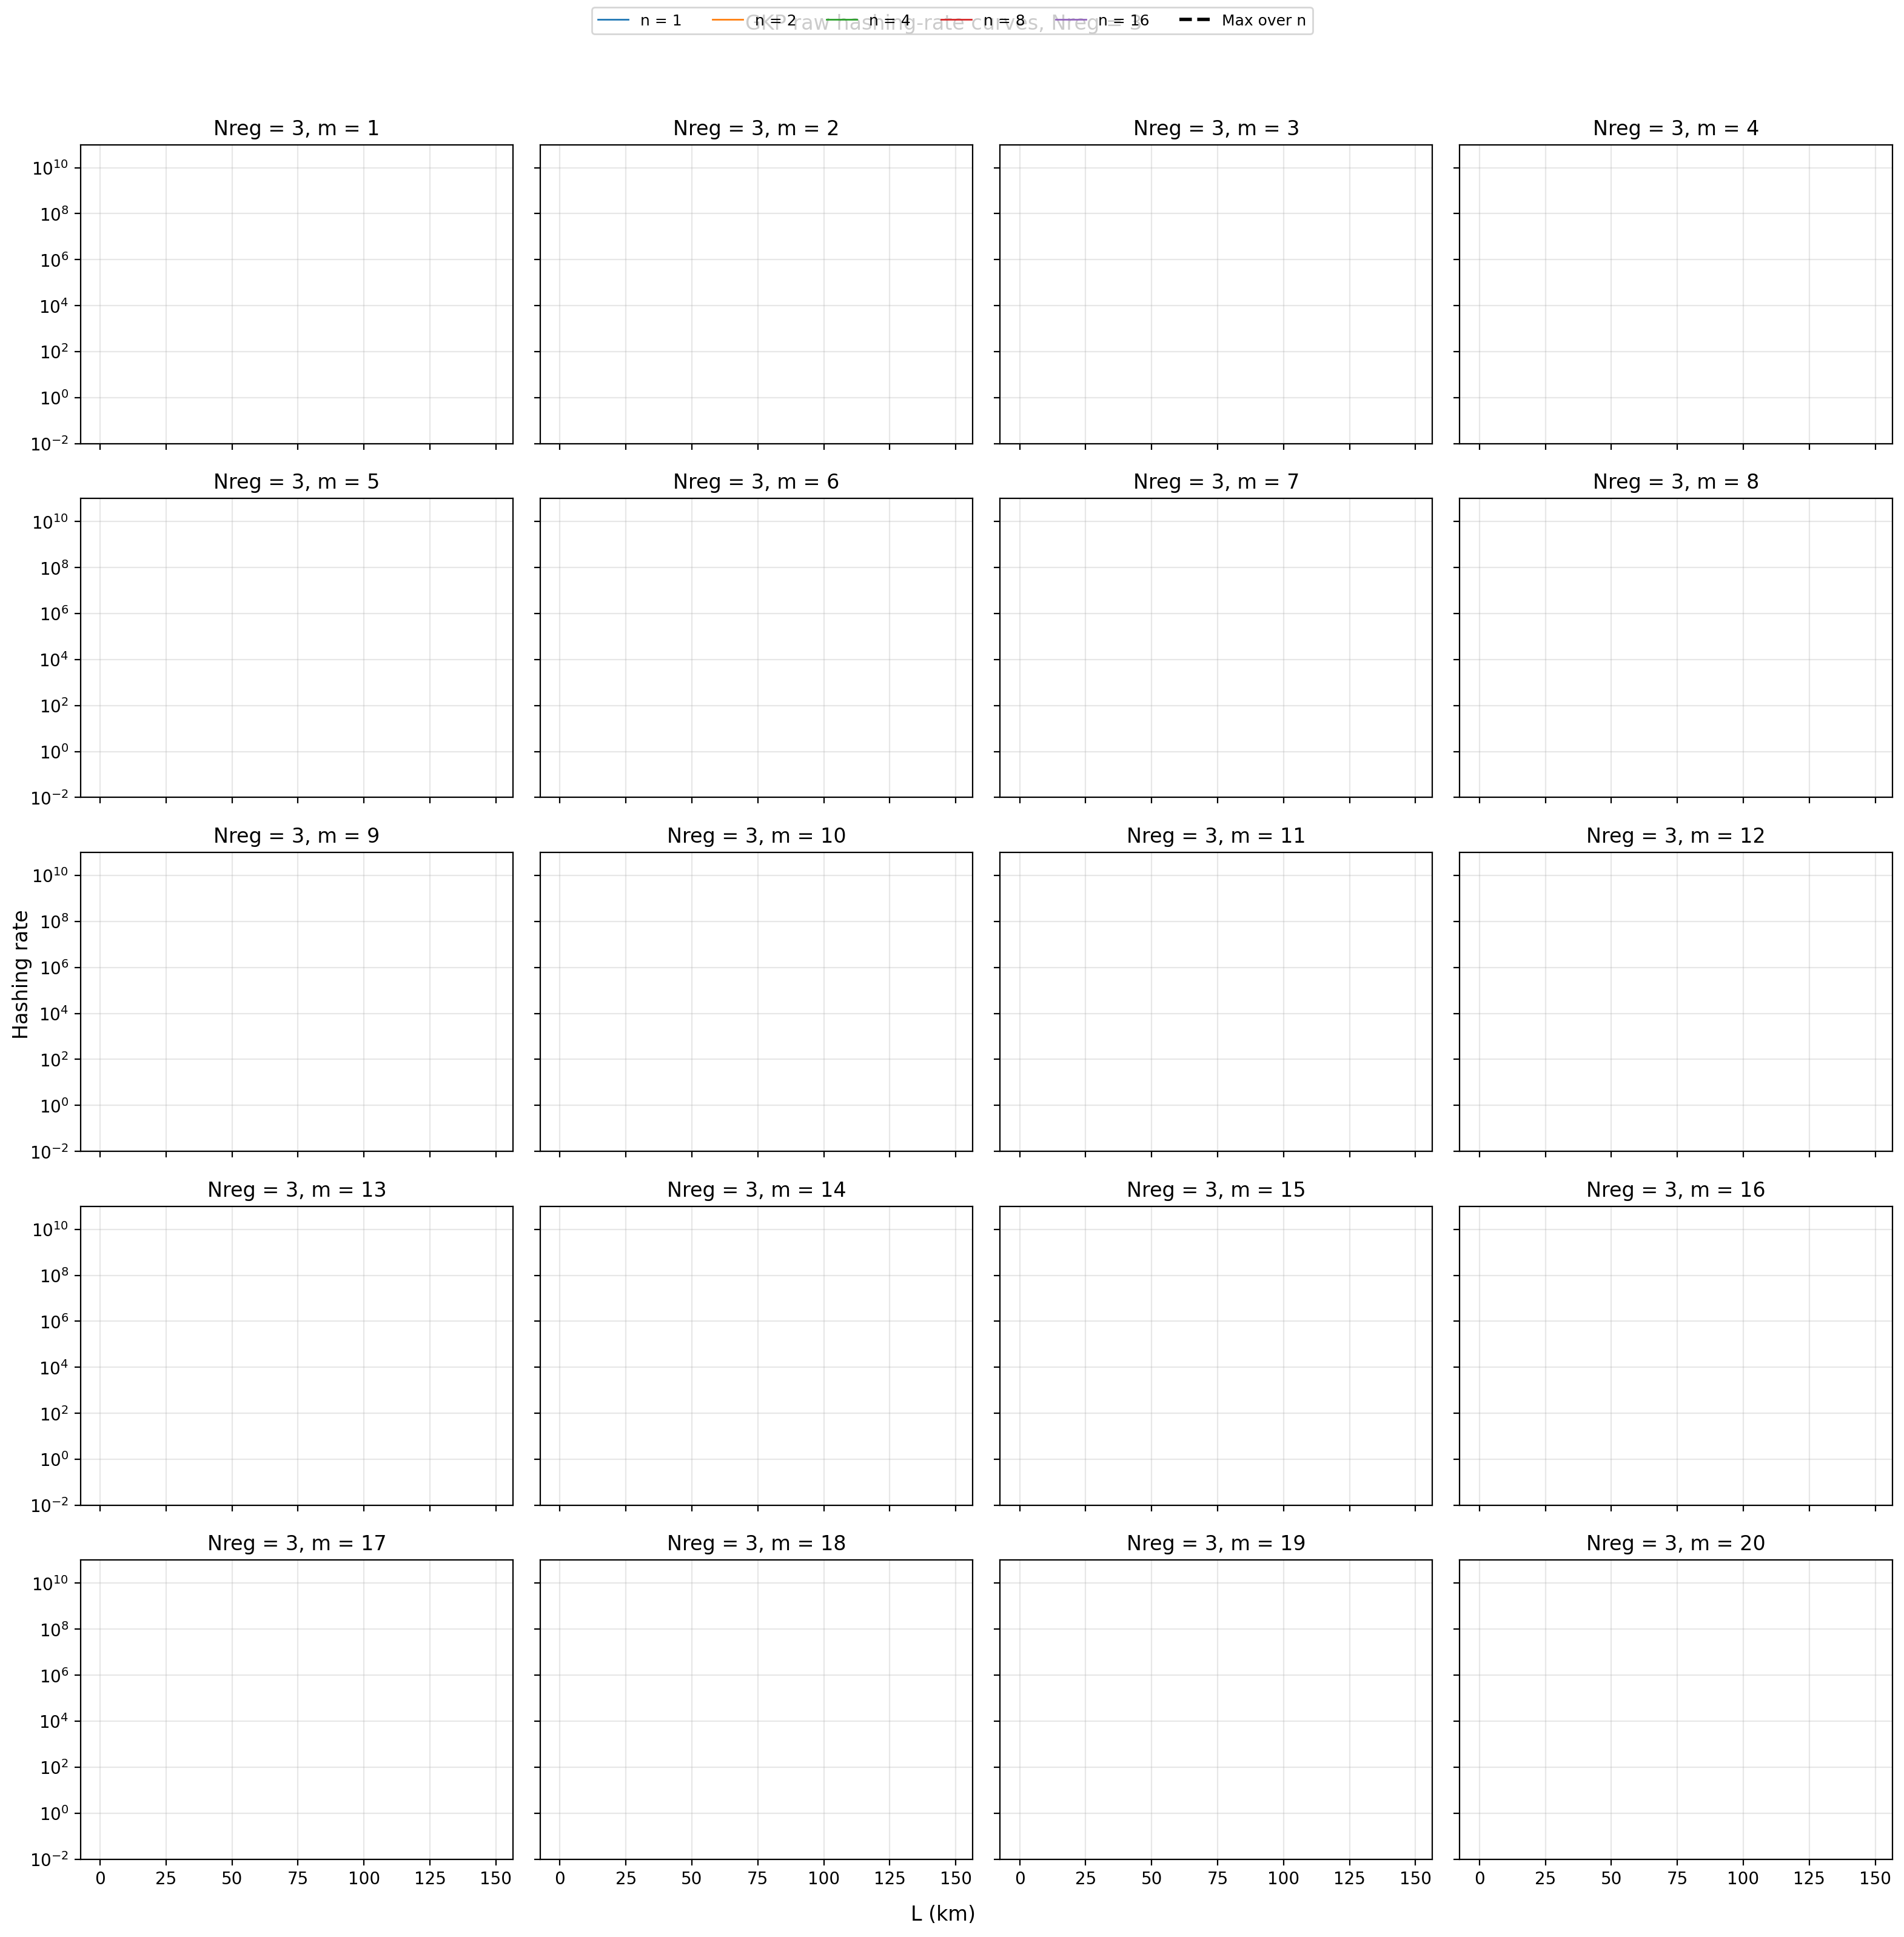


Plotting all available m-plots for Nreg = 4


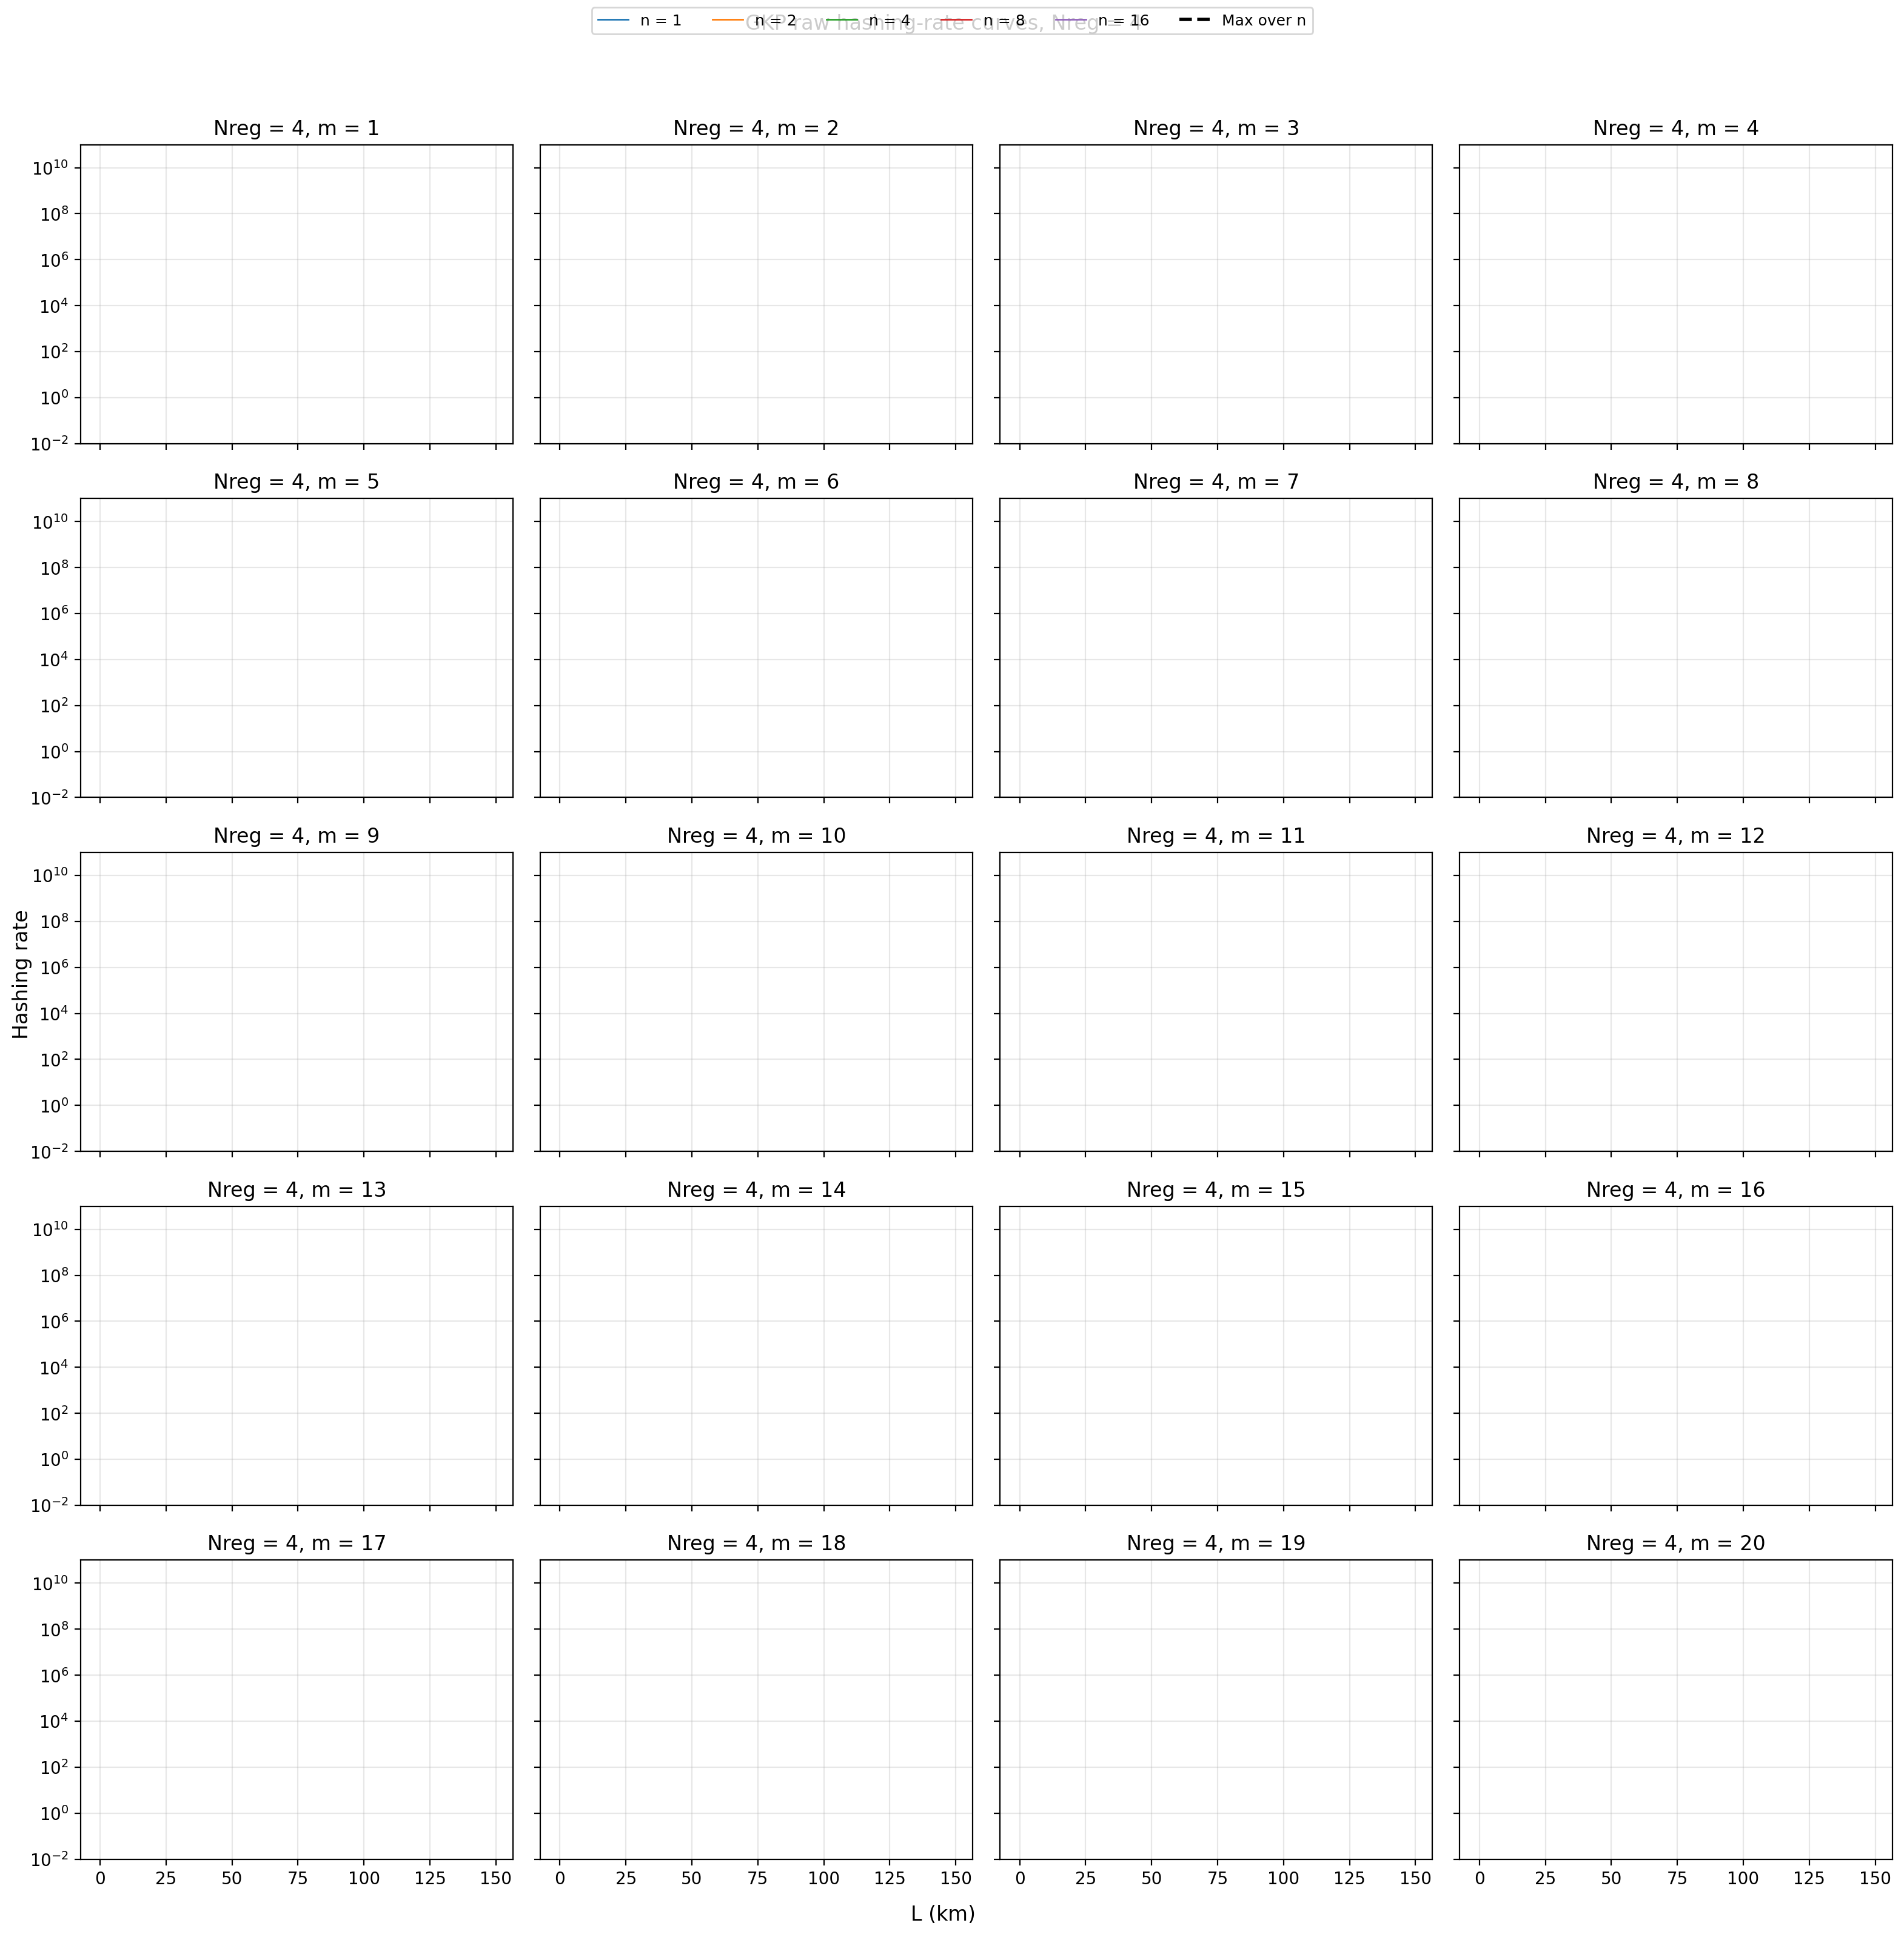


Plotting all available m-plots for Nreg = 5


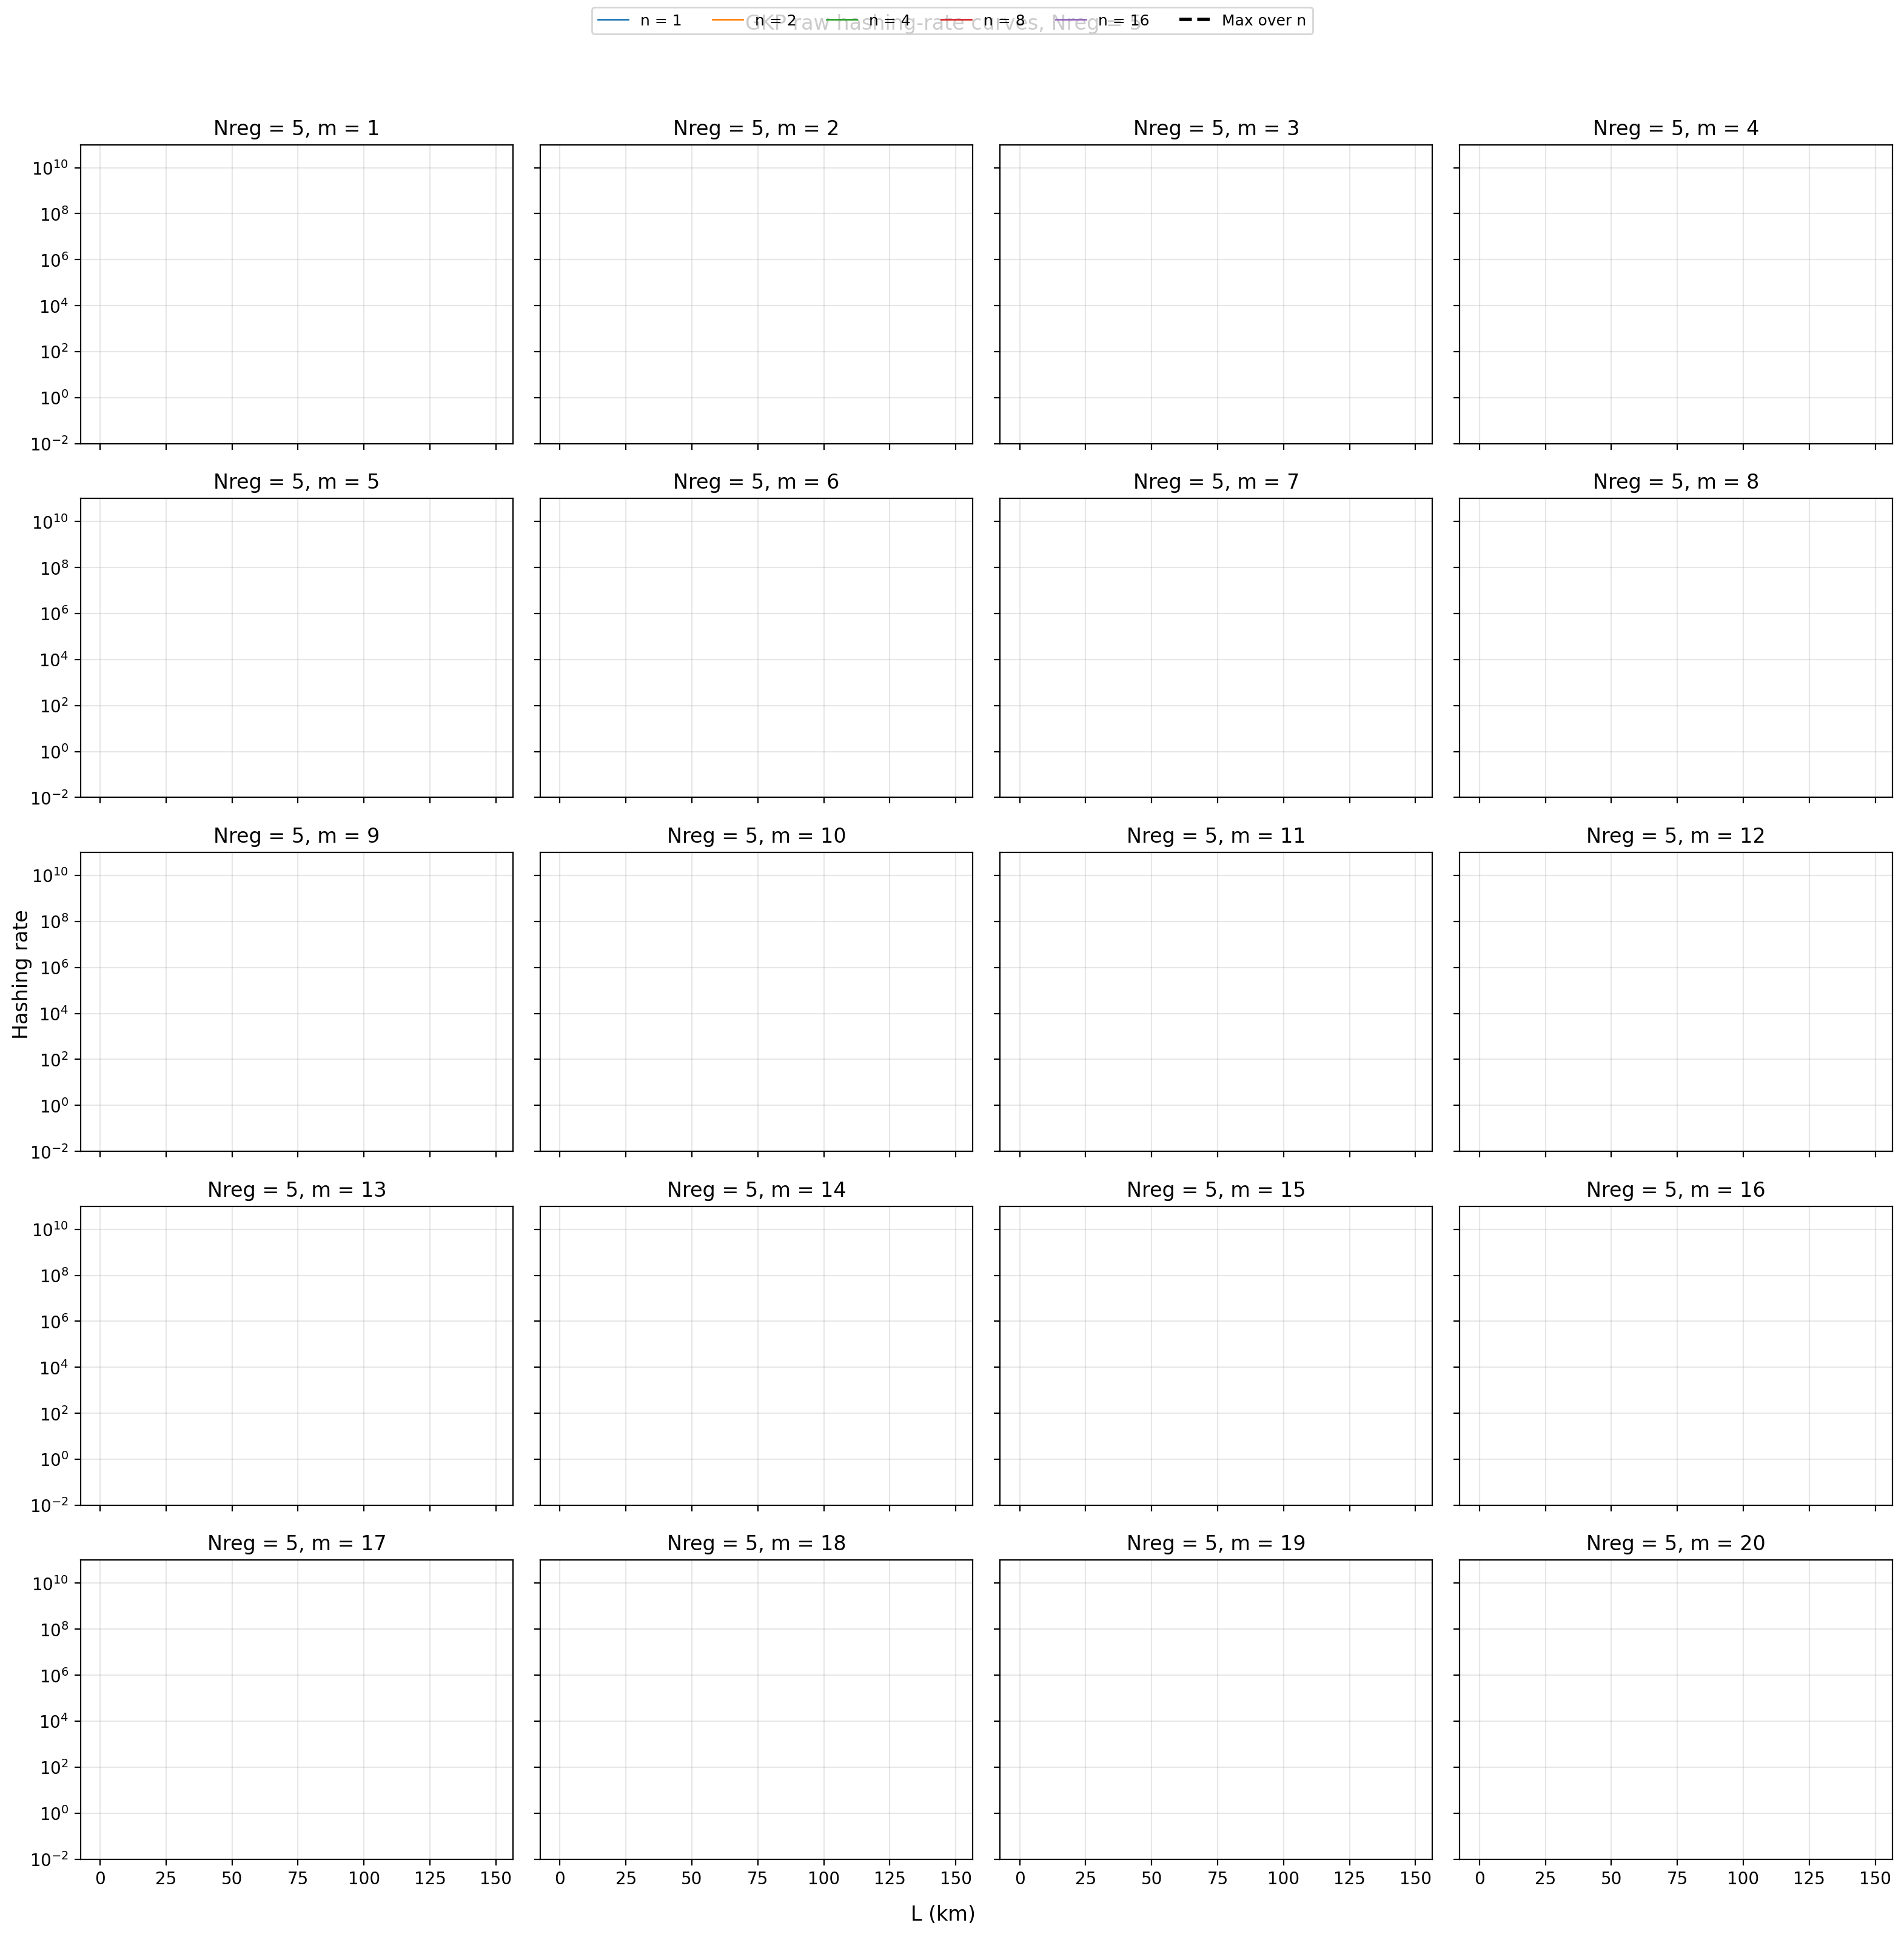


Plotting all available m-plots for Nreg = 6


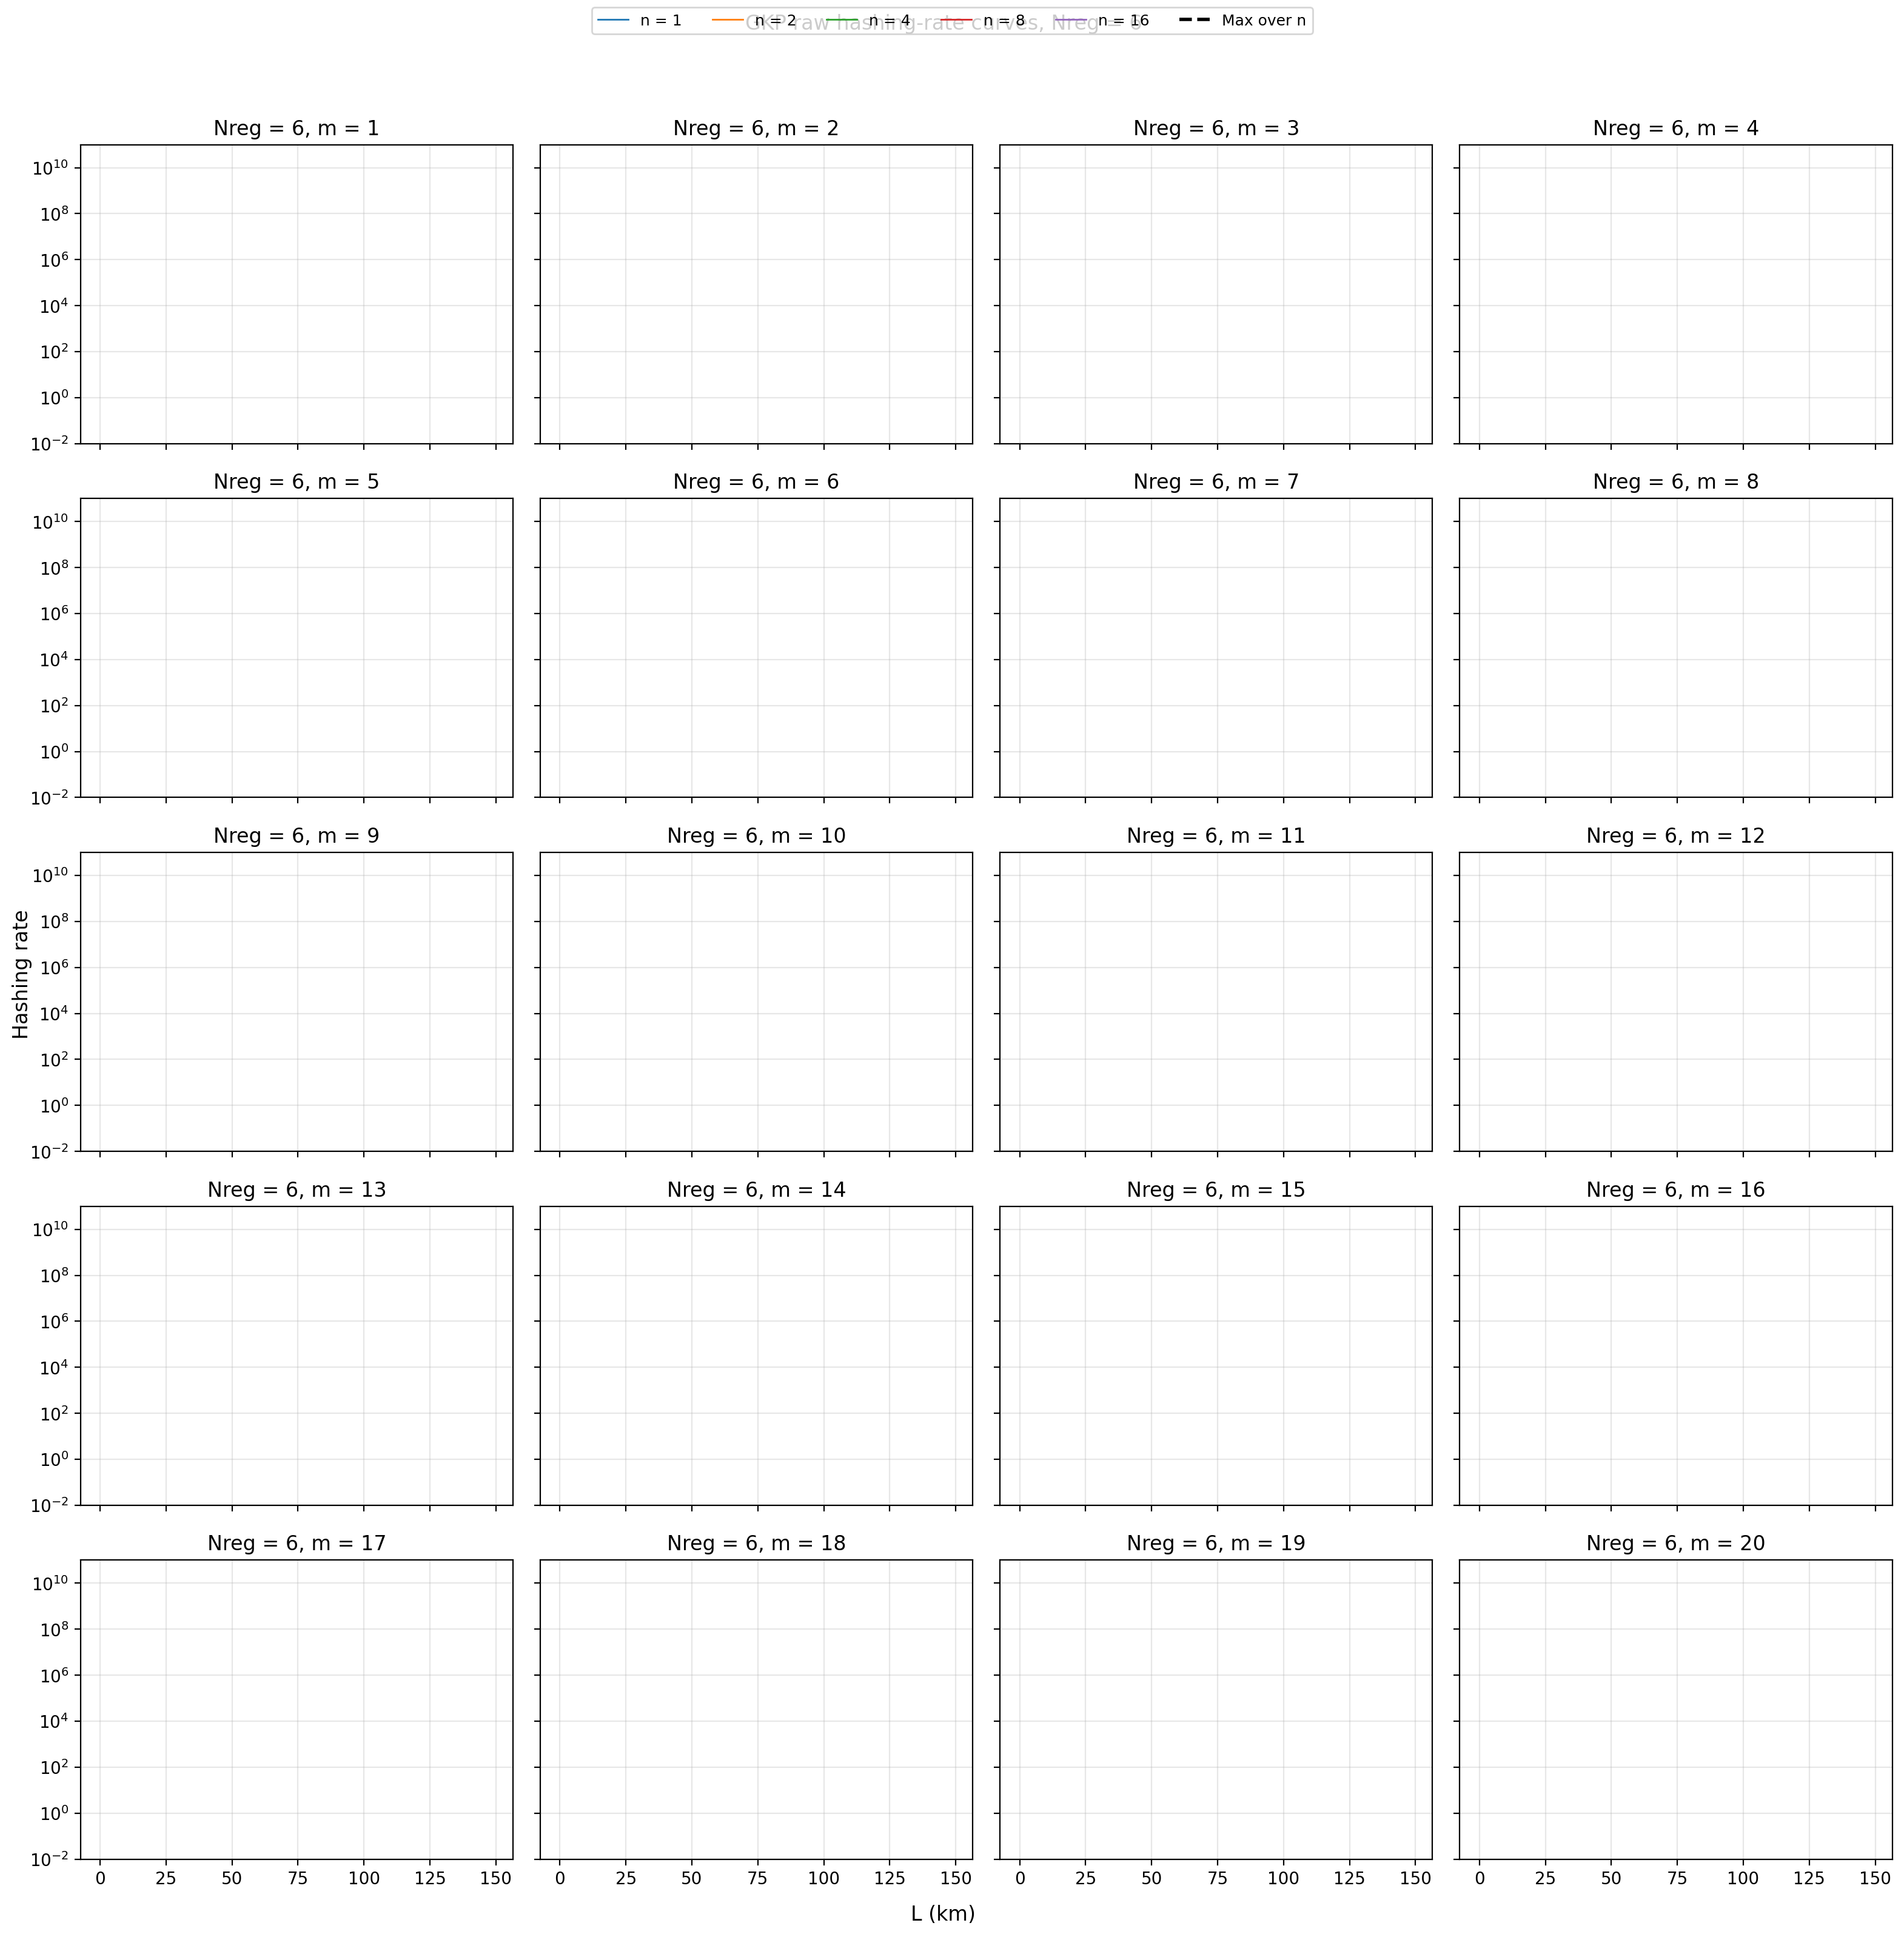


Plotting all available m-plots for Nreg = 7


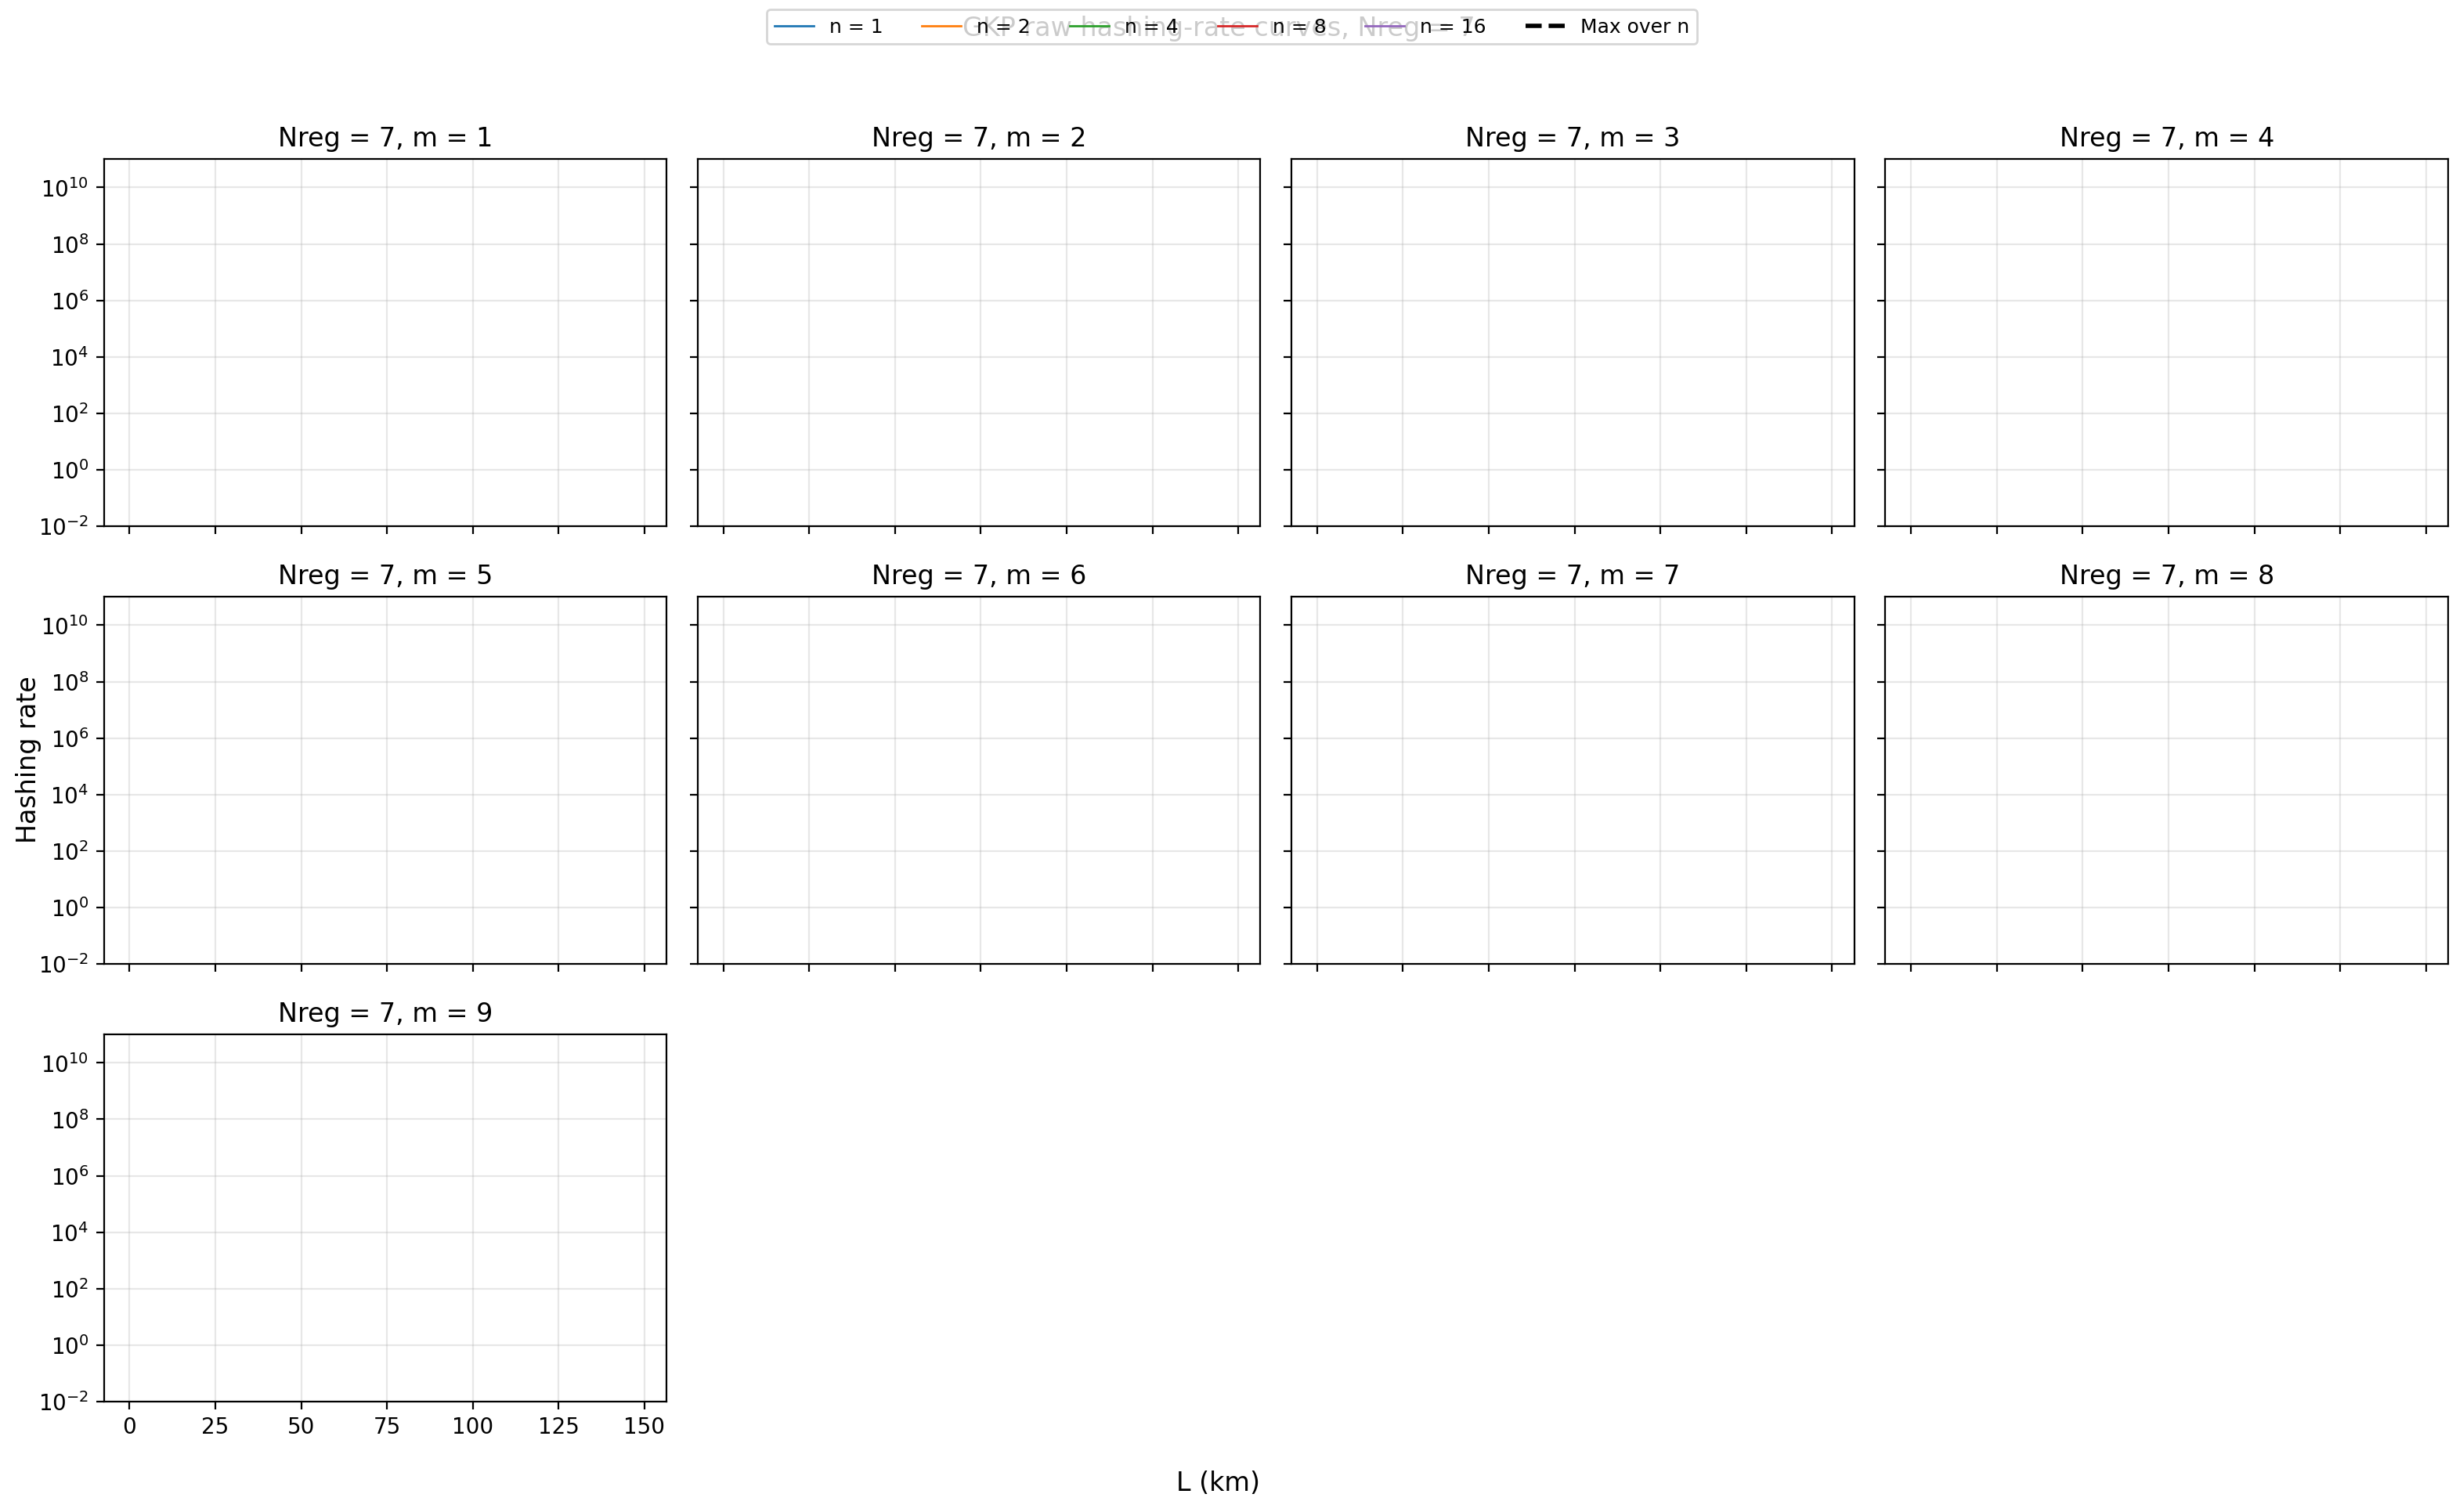


Plotting all available m-plots for Nreg = 8


KeyError: 8

In [15]:
for Nreg in Nreg_values:

    print(f"\nPlotting all available m-plots for Nreg = {Nreg}")

    available_m = sorted(all_results[Nreg].keys())

    nplots = len(available_m)
    ncols = 4
    nrows = int(np.ceil(nplots / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(4 * ncols, 3.2 * nrows),
        dpi=200,
        sharex=True,
        sharey=True,
    )

    axes = np.asarray(axes).reshape(-1)

    for idx, m in enumerate(available_m):

        ax = axes[idx]
        out = all_results[Nreg][m]

        fixed_n_curves = []

        for n in n_vals:

            curve = out["fixed_n_data"][n]["rate"]
            fixed_n_curves.append(curve)

            ax.plot(
                out["Ls"],
                curve,
                label=f"n = {n}",
                linewidth=1.0
            )

        fixed_n_curves = np.vstack(fixed_n_curves)

        maximisation_over_n_for_fixed_m = np.max(
            fixed_n_curves,
            axis=0
        )

        ax.plot(
            out["Ls"],
            maximisation_over_n_for_fixed_m,
            color="black",
            linestyle="--",
            linewidth=2,
            label="Max over n"
        )

        ax.set_yscale("log")
        ax.set_ylim(1e-2, 1e11)
        ax.set_title(f"Nreg = {Nreg}, m = {m}")
        ax.grid(True, which="both", alpha=0.3)

    # Turn off unused axes
    for j in range(nplots, len(axes)):
        axes[j].axis("off")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=len(n_vals) + 1,
        fontsize=9
    )

    fig.suptitle(
        f"GKP raw hashing-rate curves, Nreg = {Nreg}",
        y=0.995
    )

    fig.supxlabel("L (km)")
    fig.supylabel("Hashing rate")

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    fig_path = os.path.join(
        output_dir,
        f"gkp_raw_curves_with_envelope_Nreg_{Nreg}.png"
    )

    plt.savefig(
        fig_path,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nDone.")


Plotting max-over-n curves for Nreg = 1


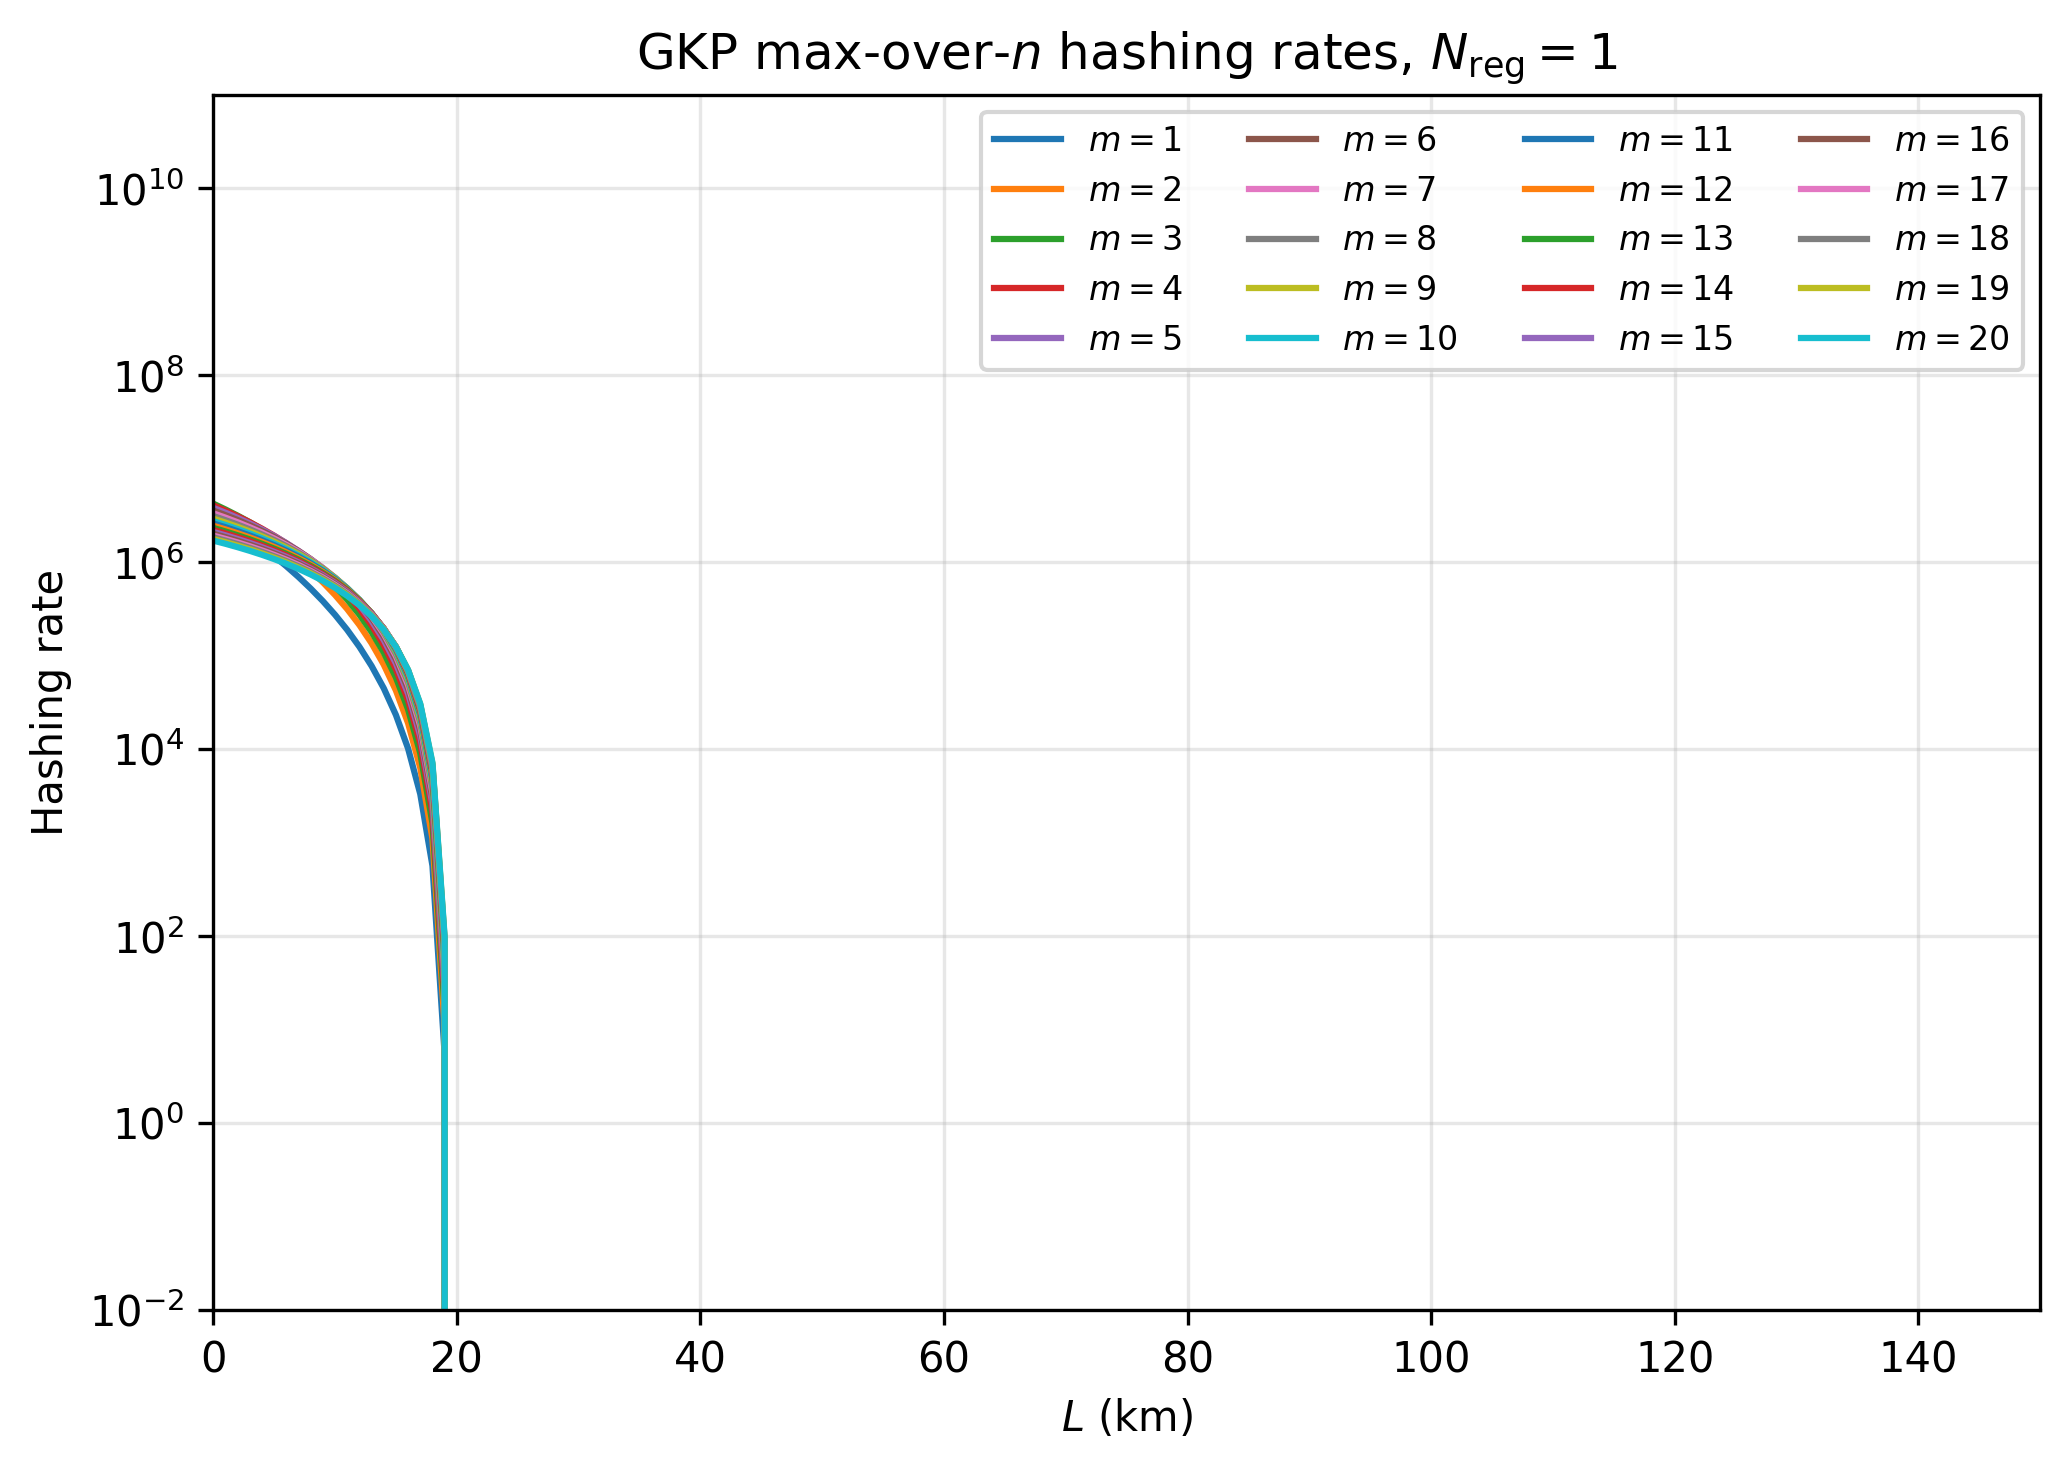


Plotting max-over-n curves for Nreg = 2


/var/folders/sf/j_bpvxs106x0w5f73qjrvpfh0000gn/T/ipykernel_9096/2814269702.py:60: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale("log")


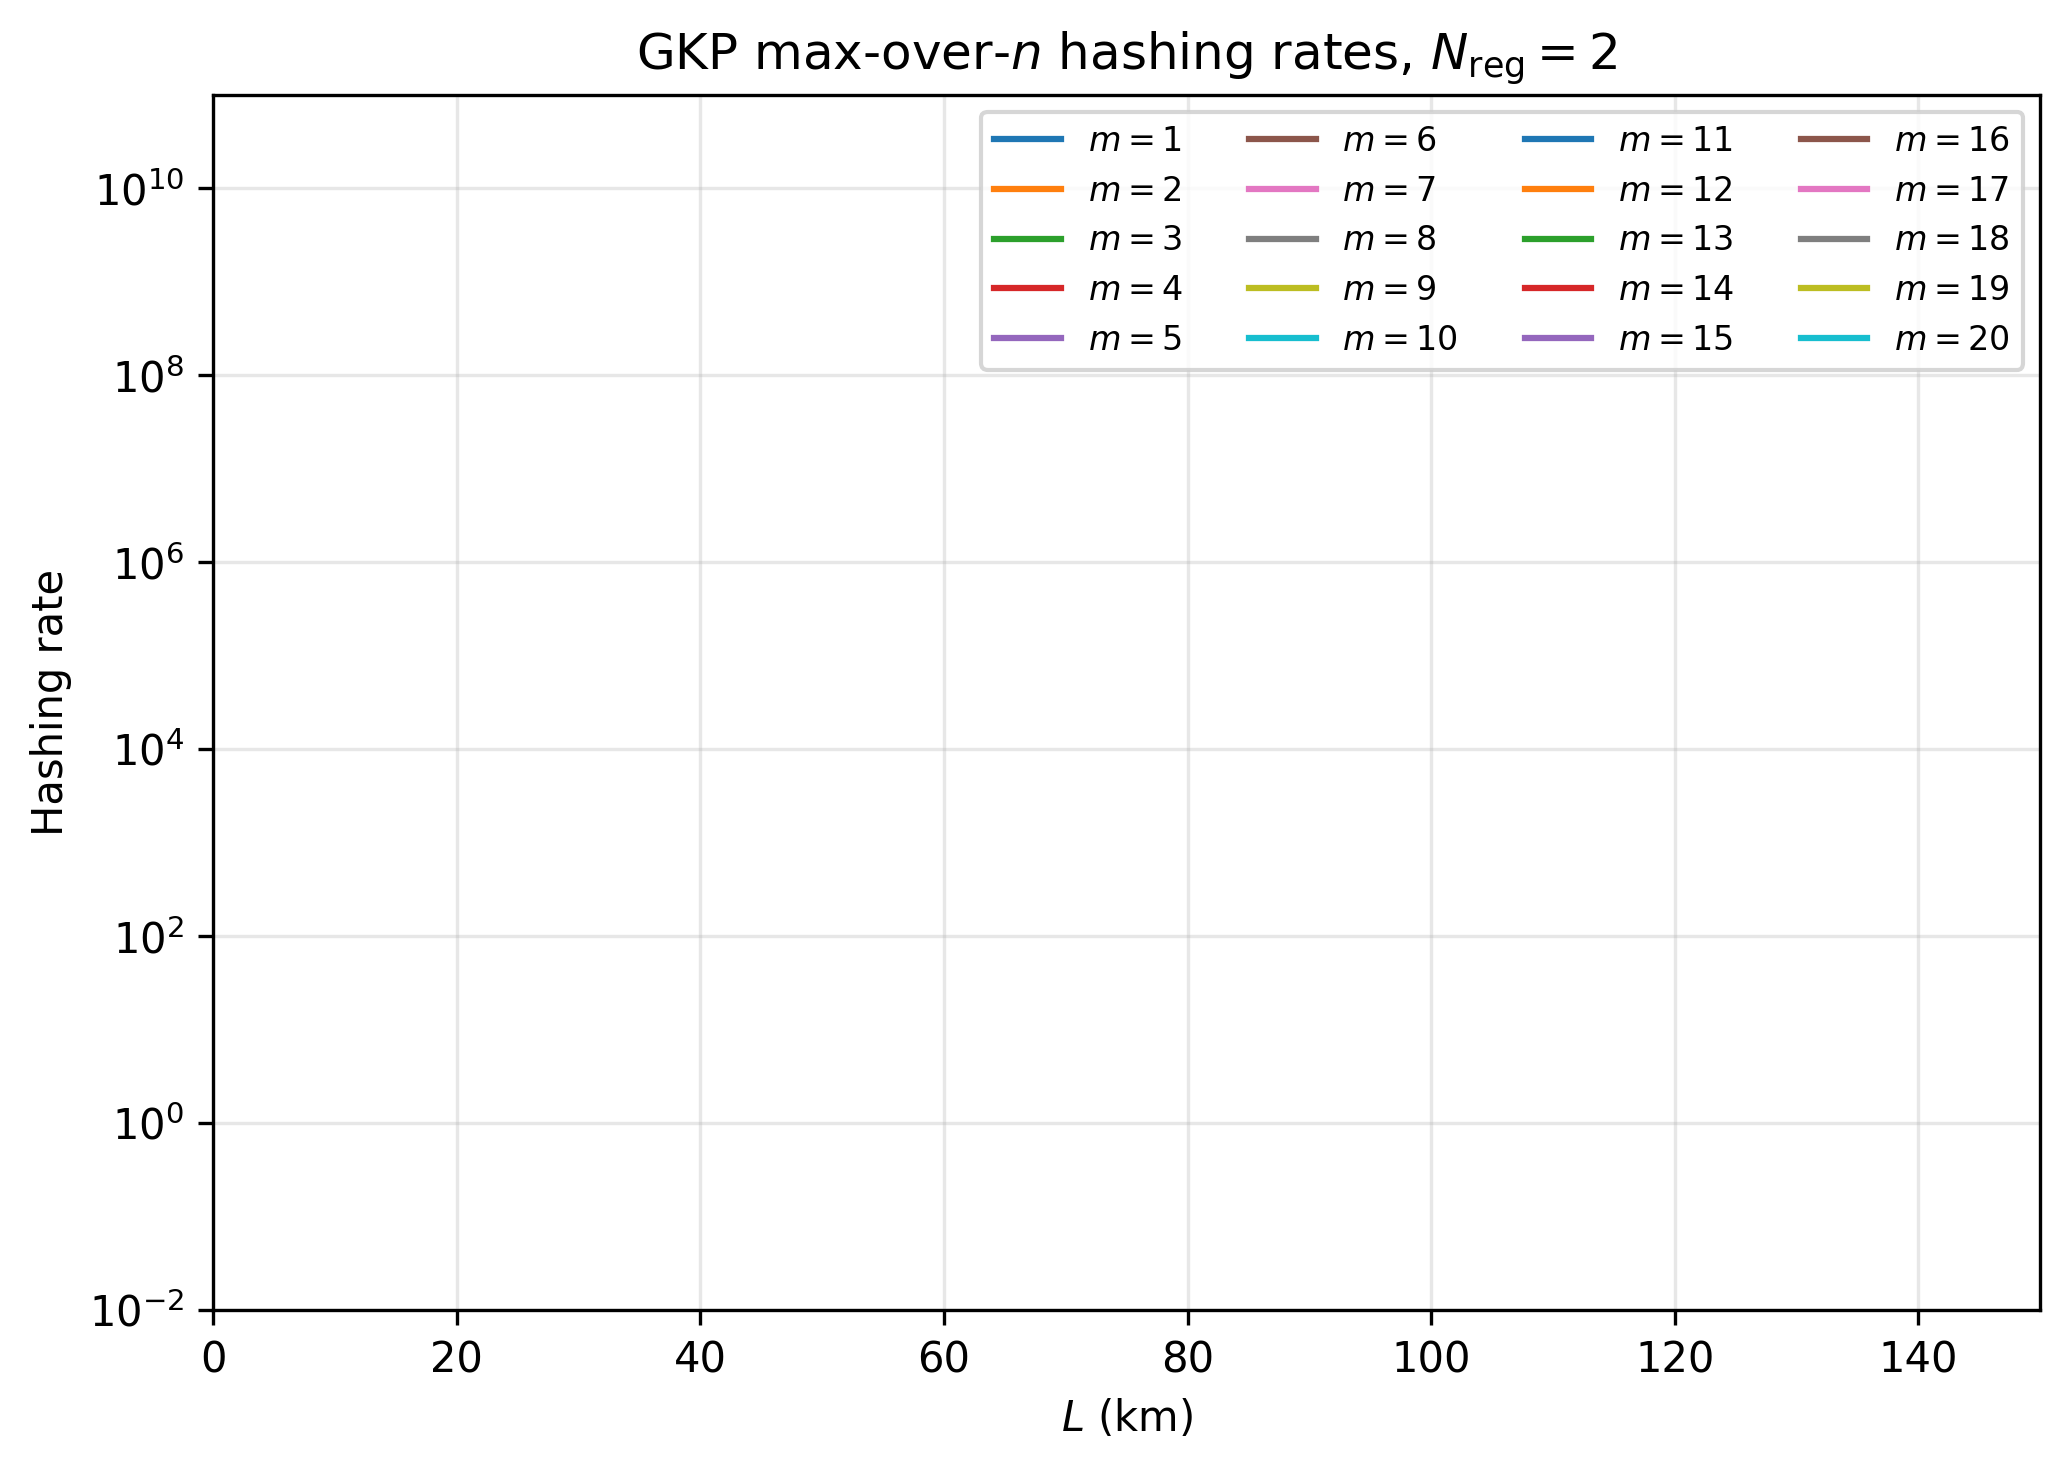


Plotting max-over-n curves for Nreg = 3


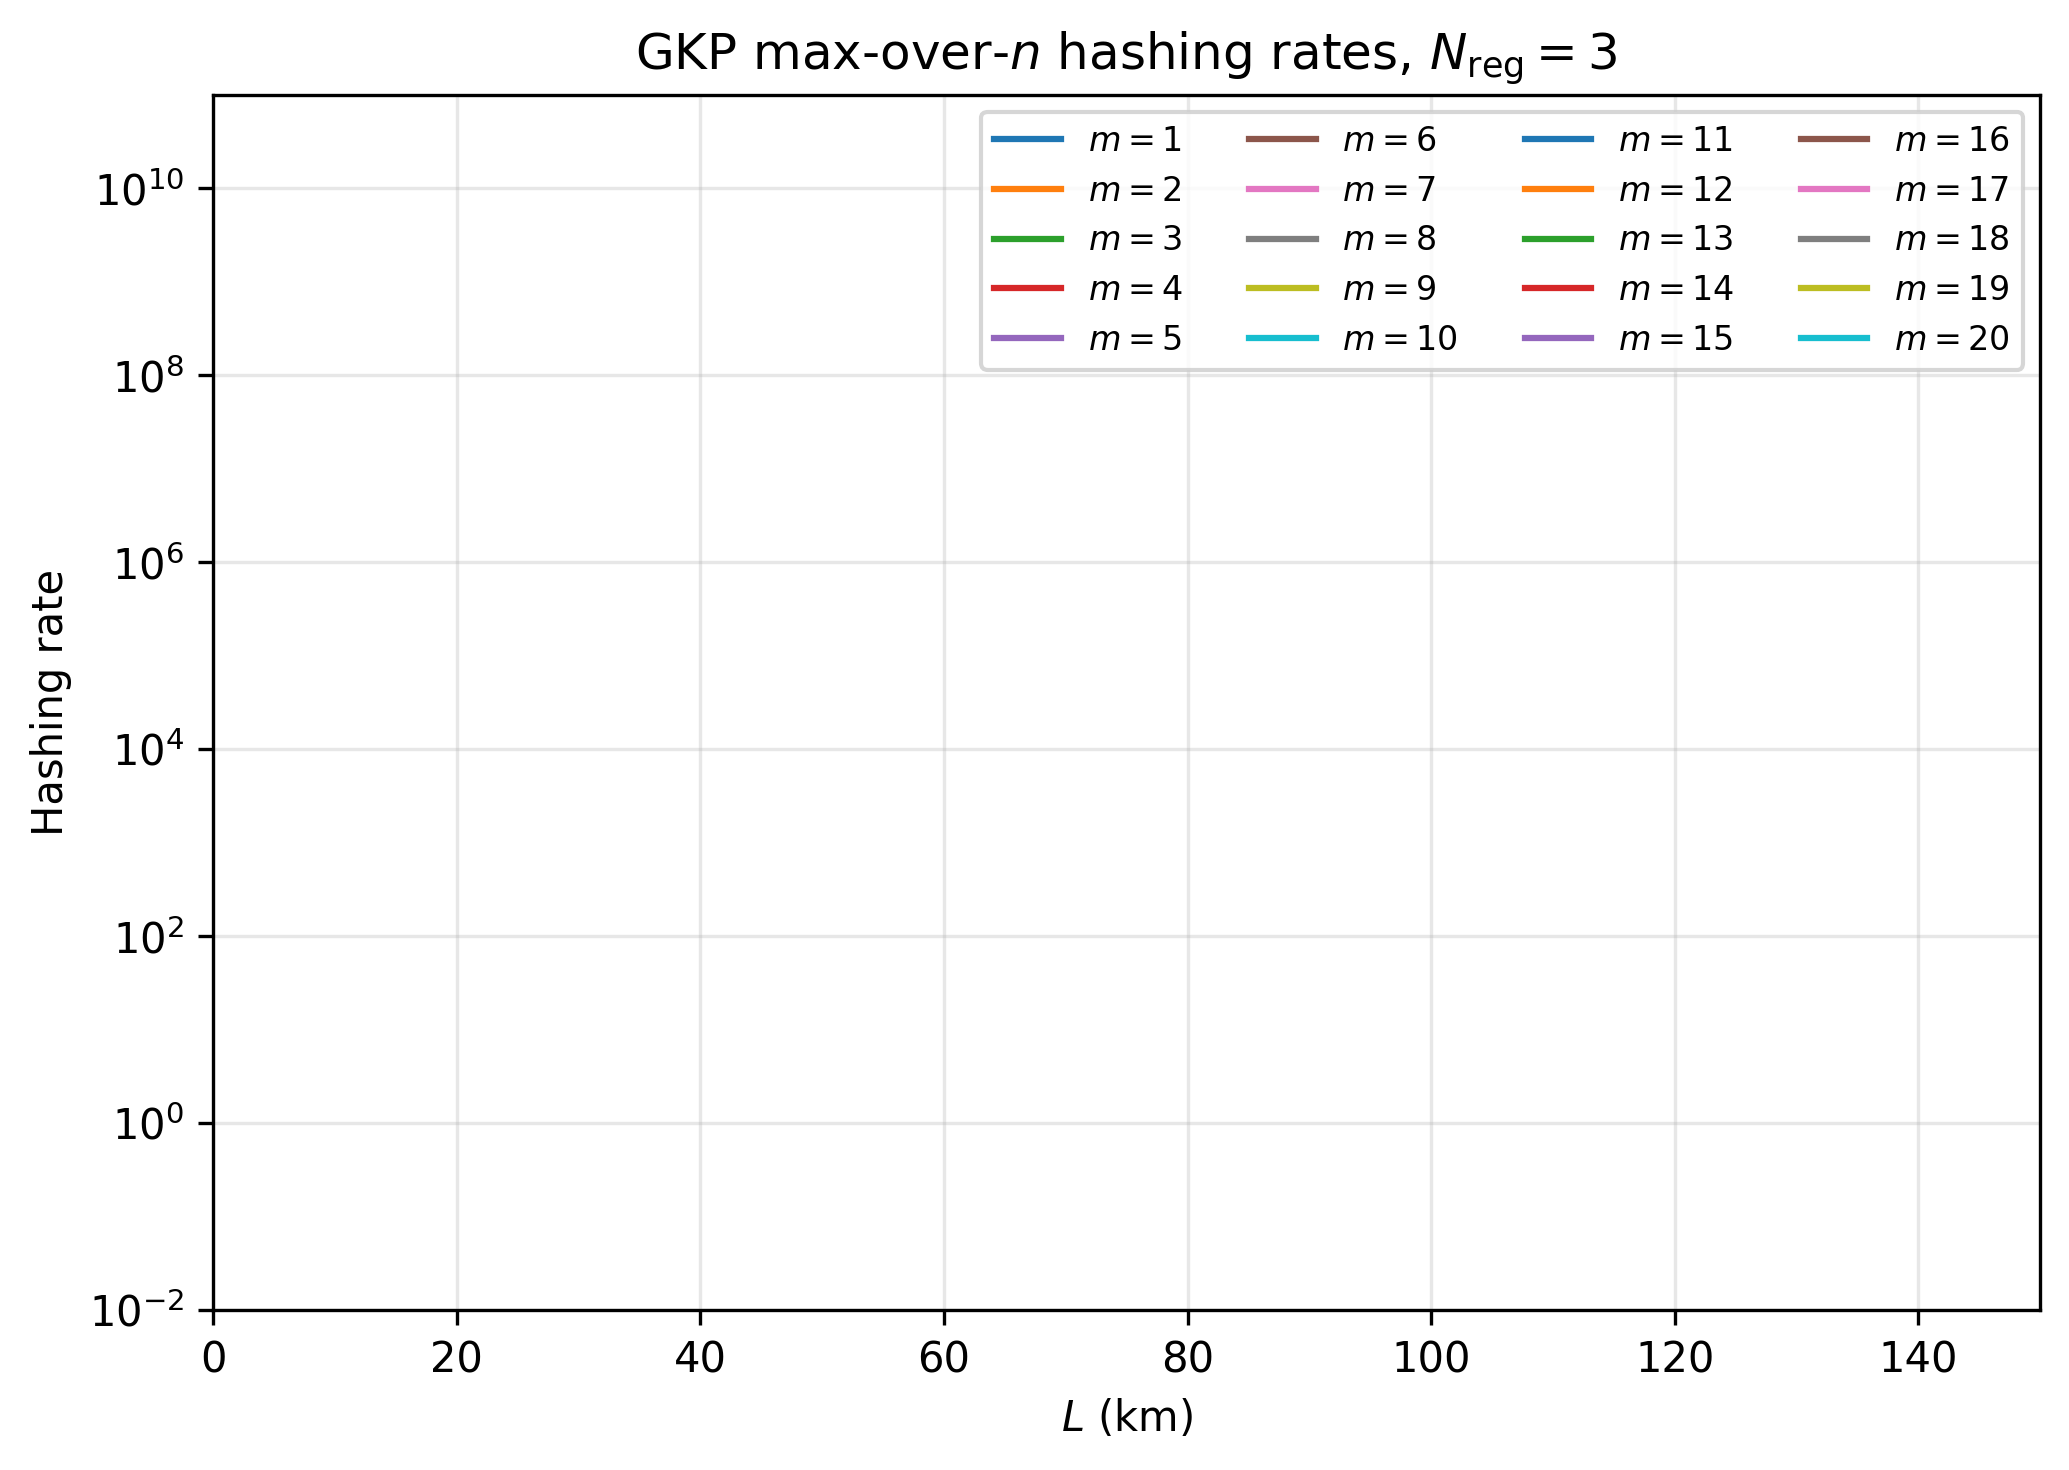


Plotting max-over-n curves for Nreg = 4


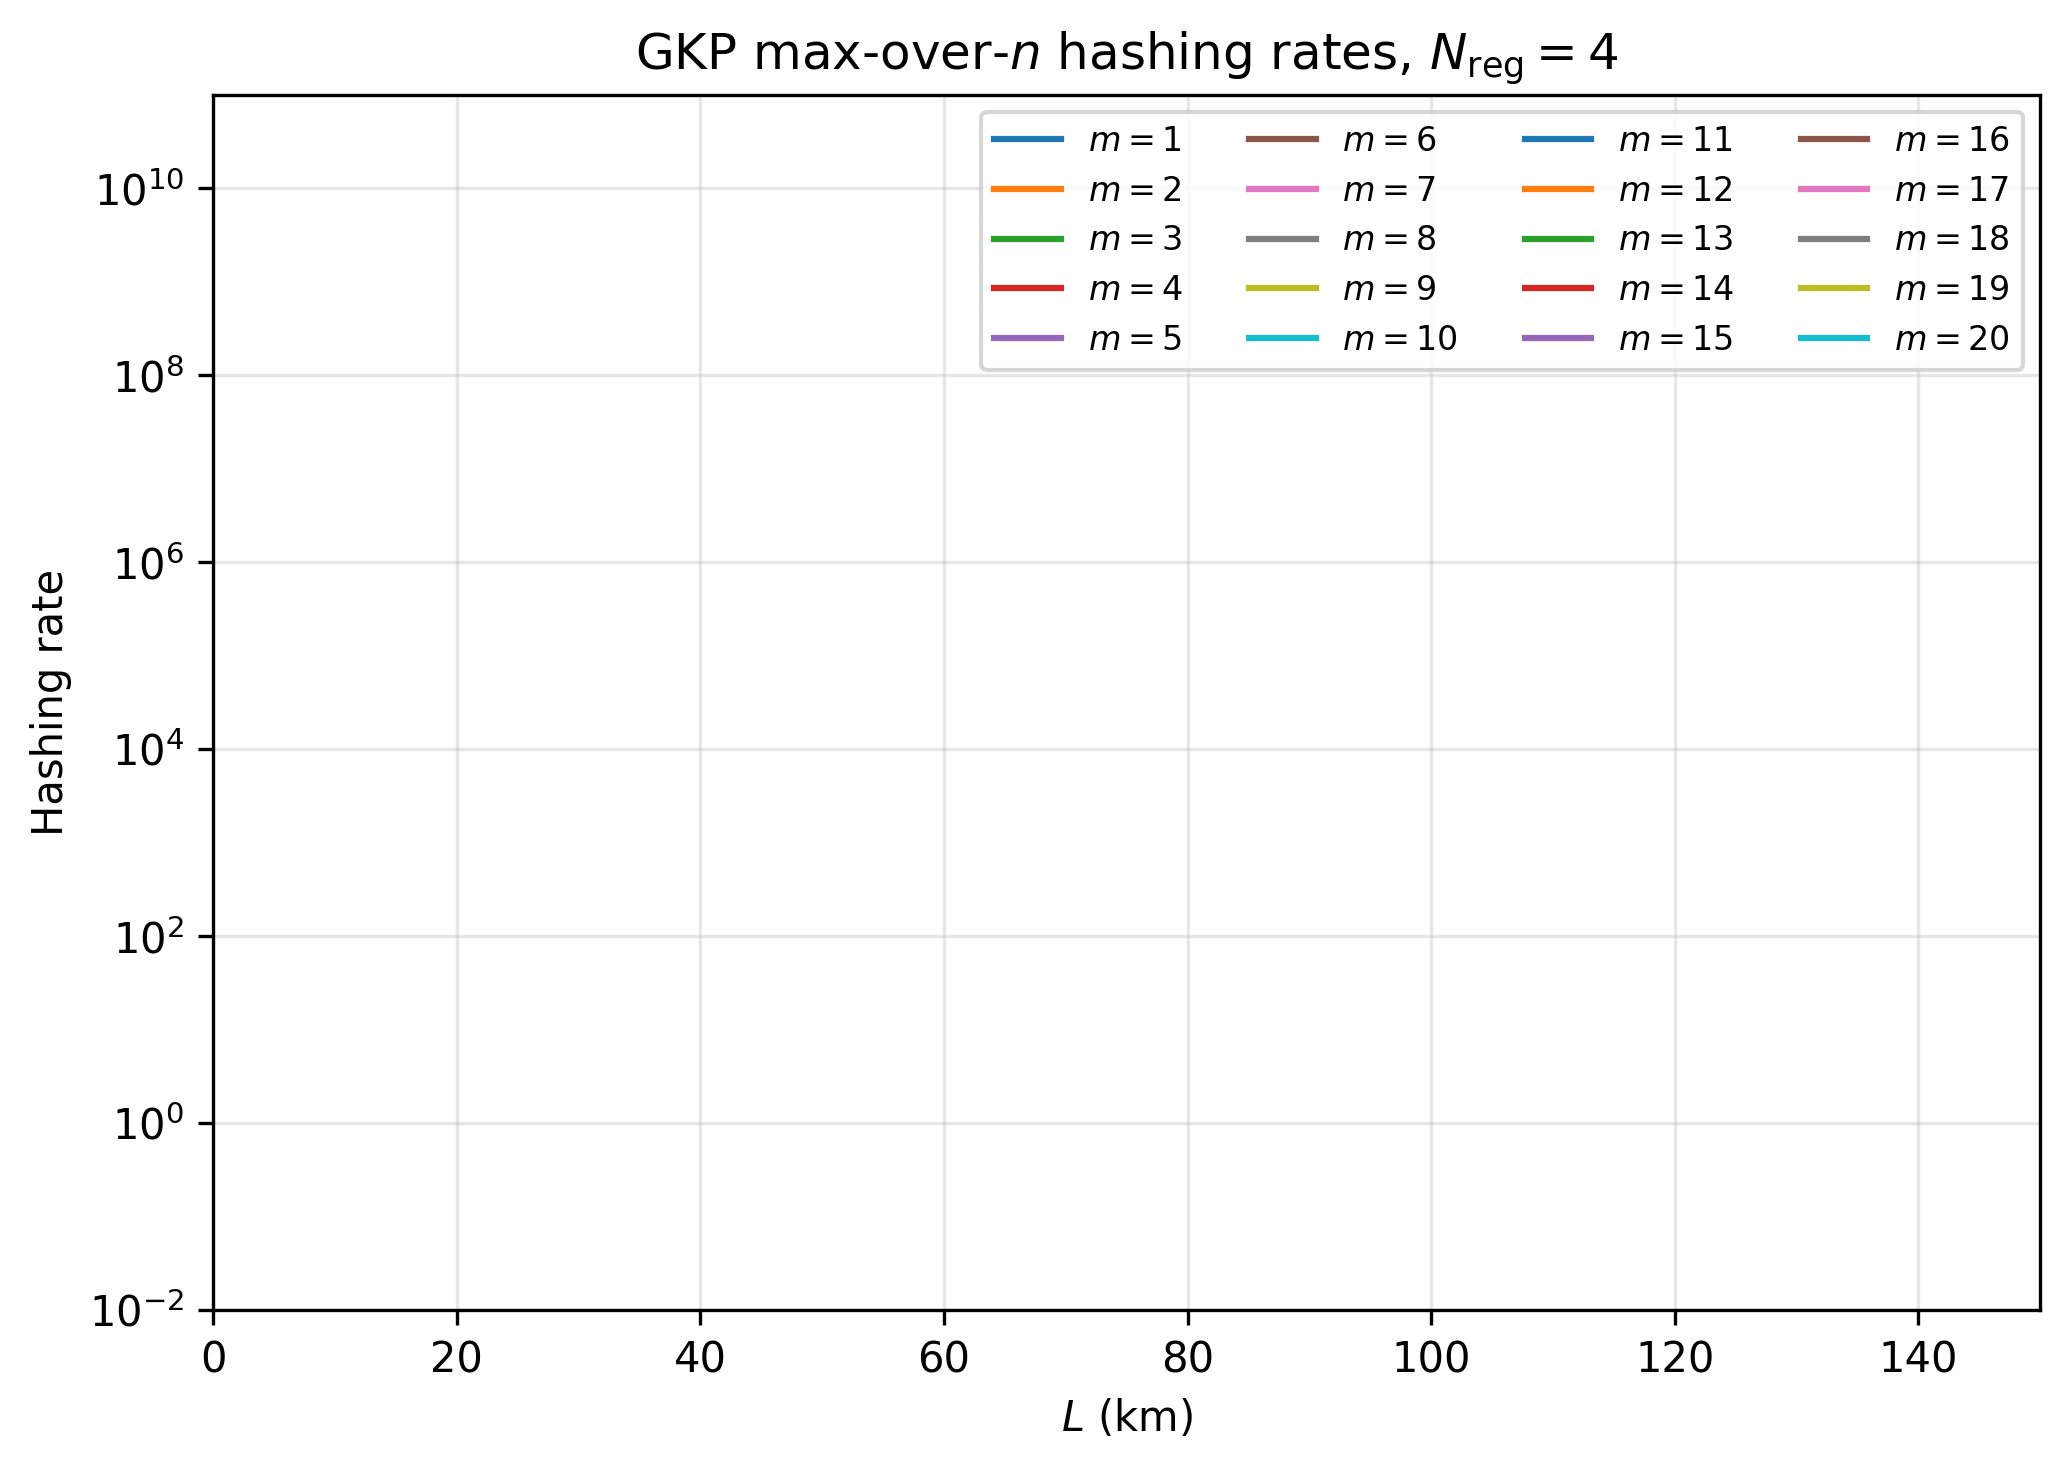


Plotting max-over-n curves for Nreg = 5


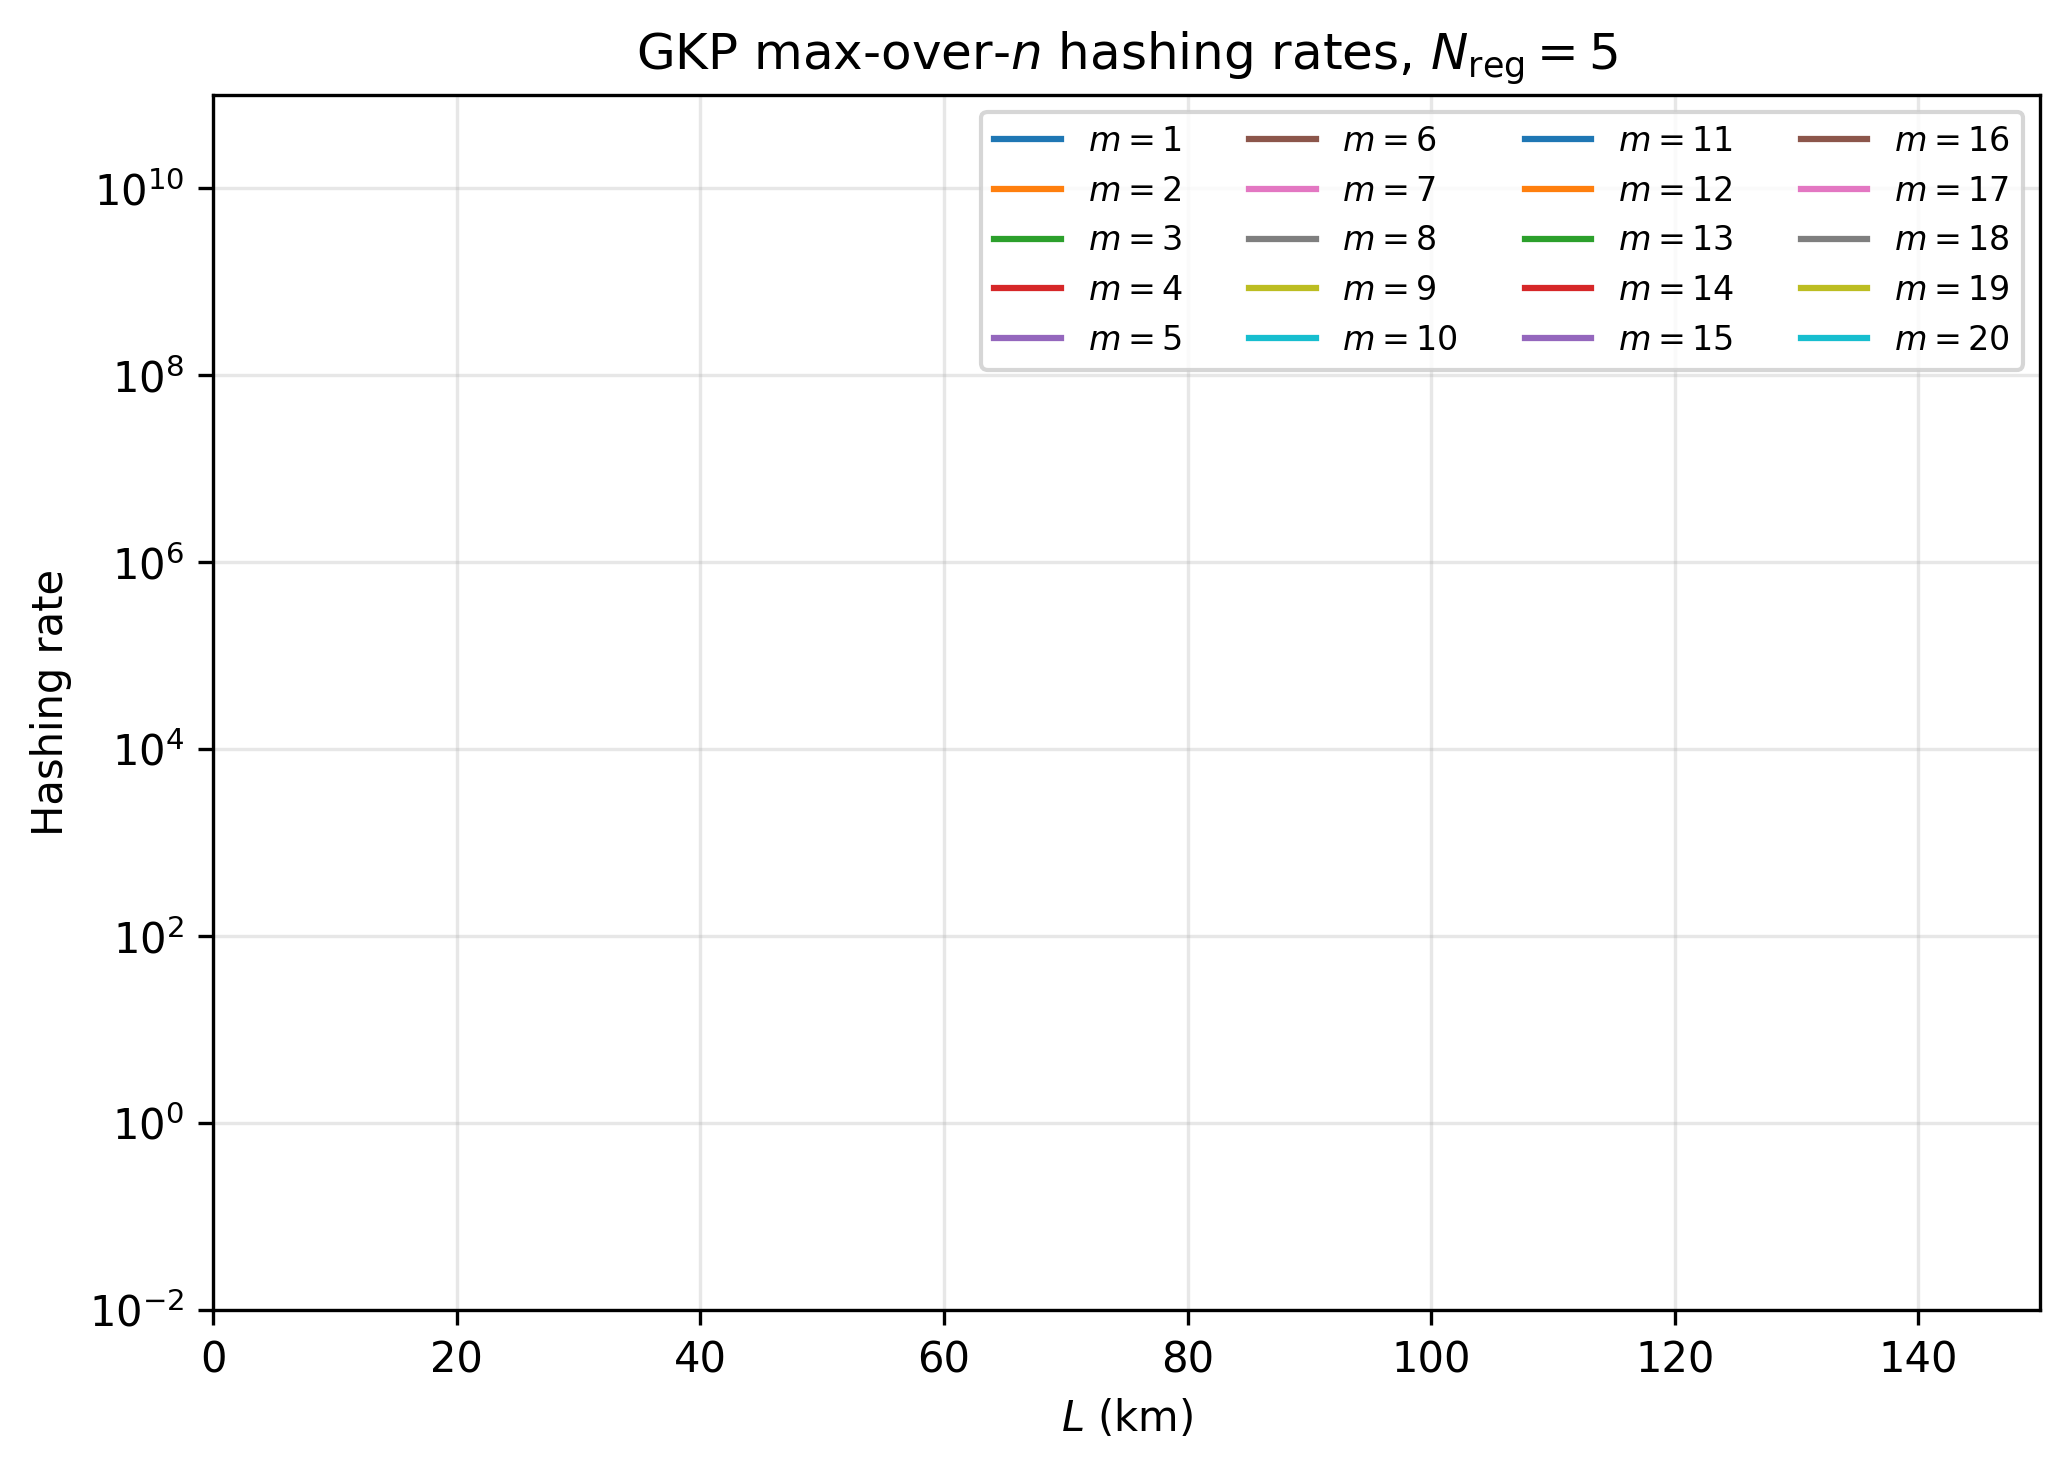


Plotting max-over-n curves for Nreg = 6


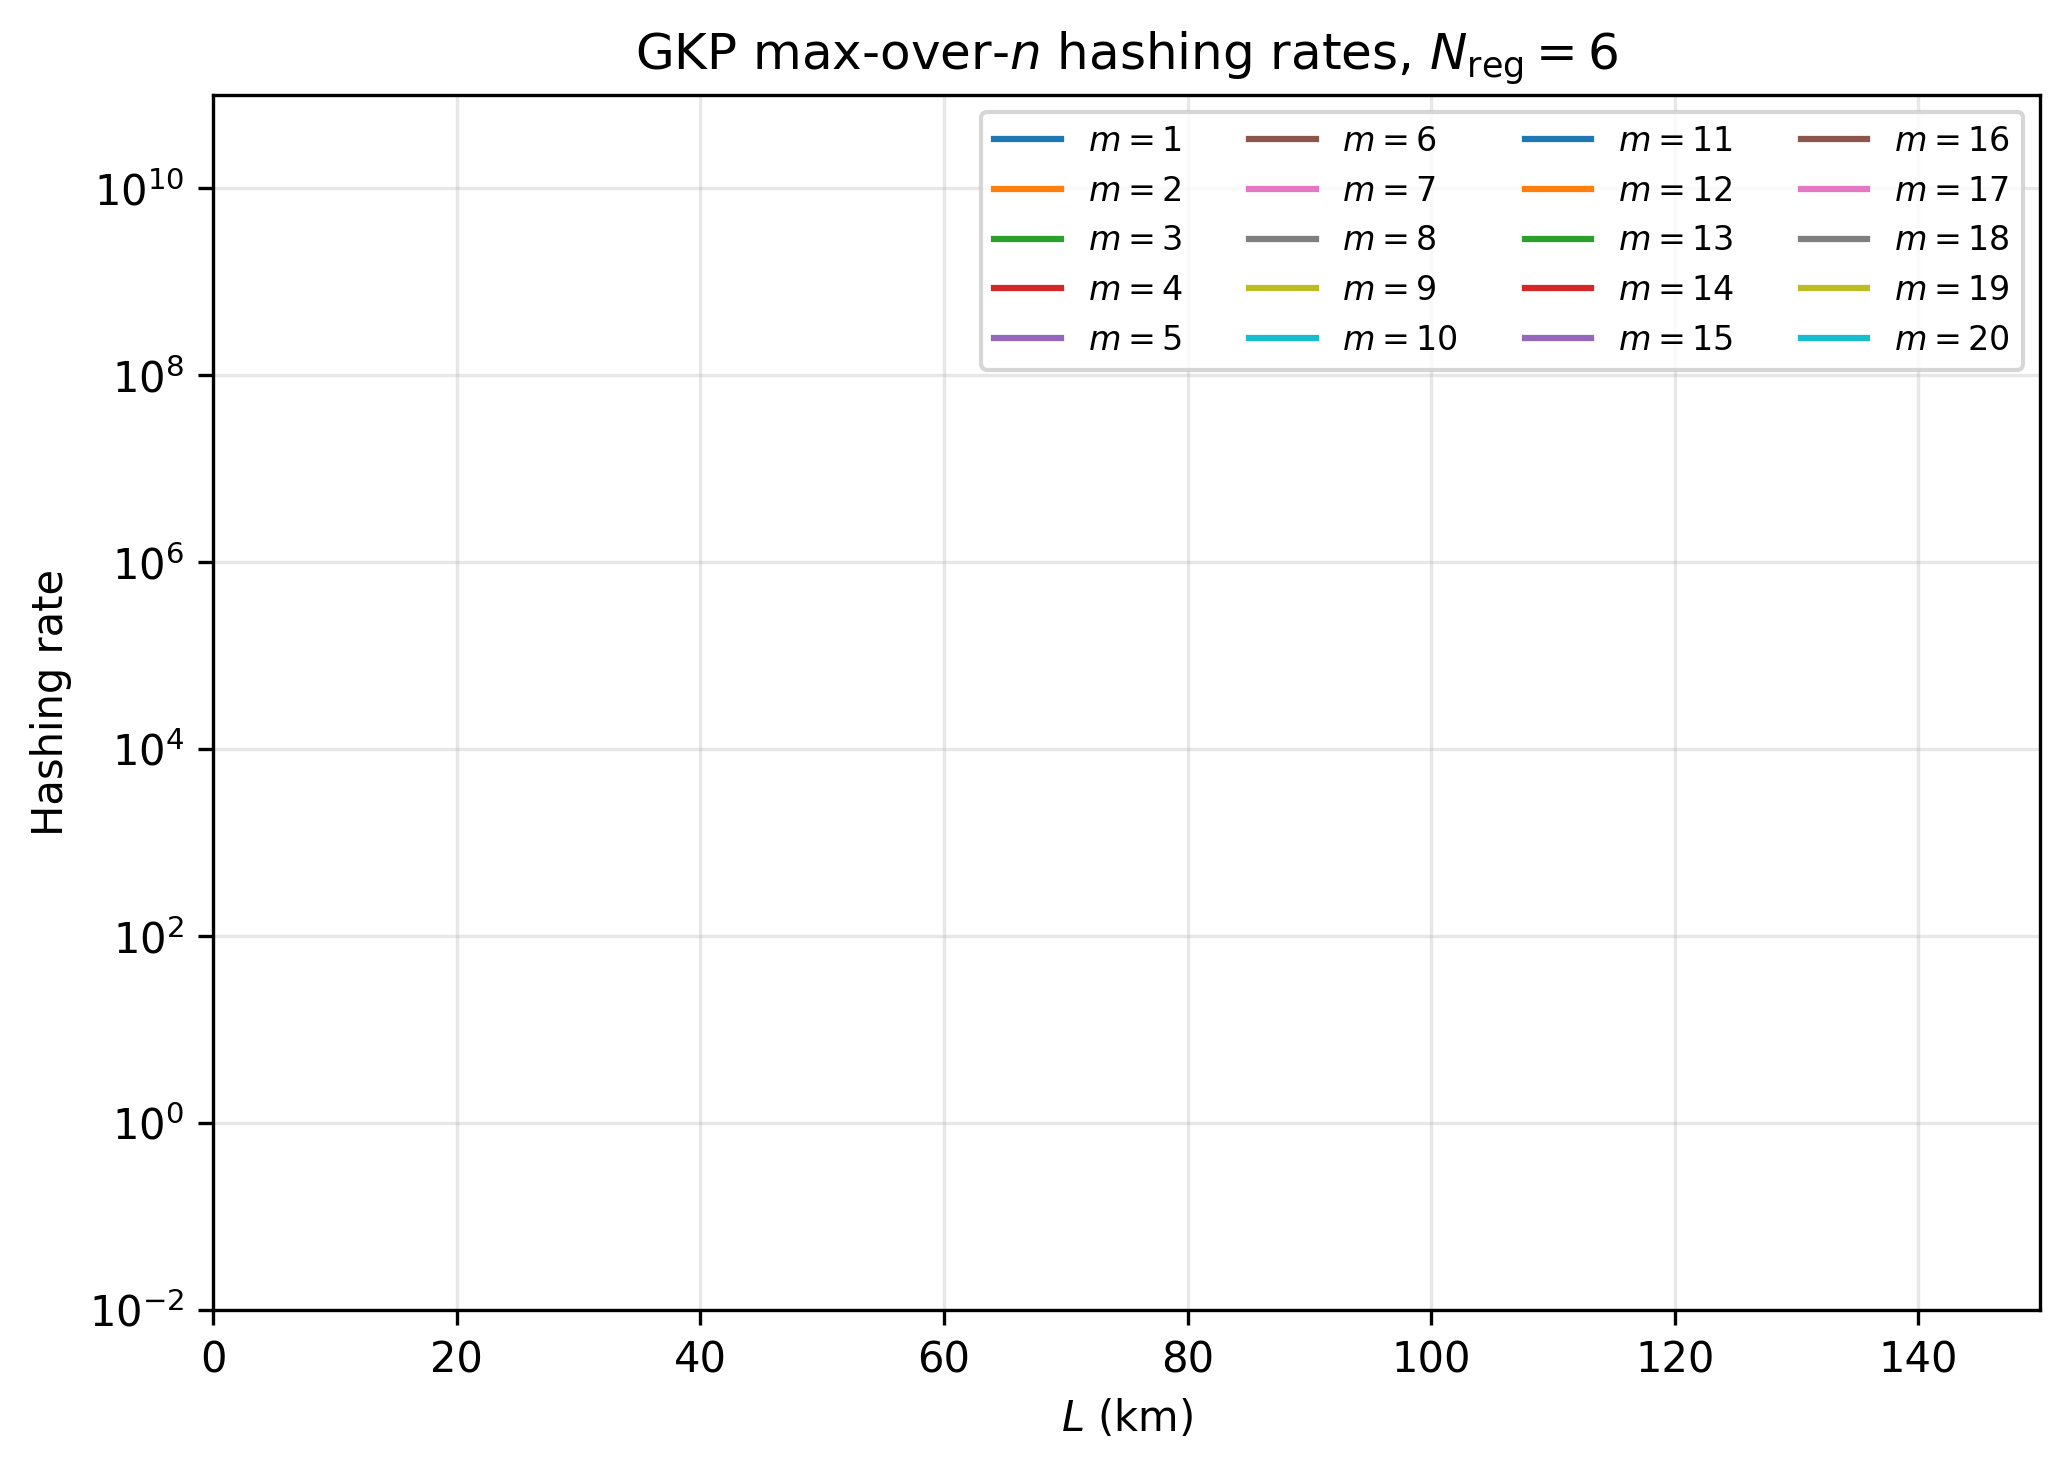


Plotting max-over-n curves for Nreg = 7


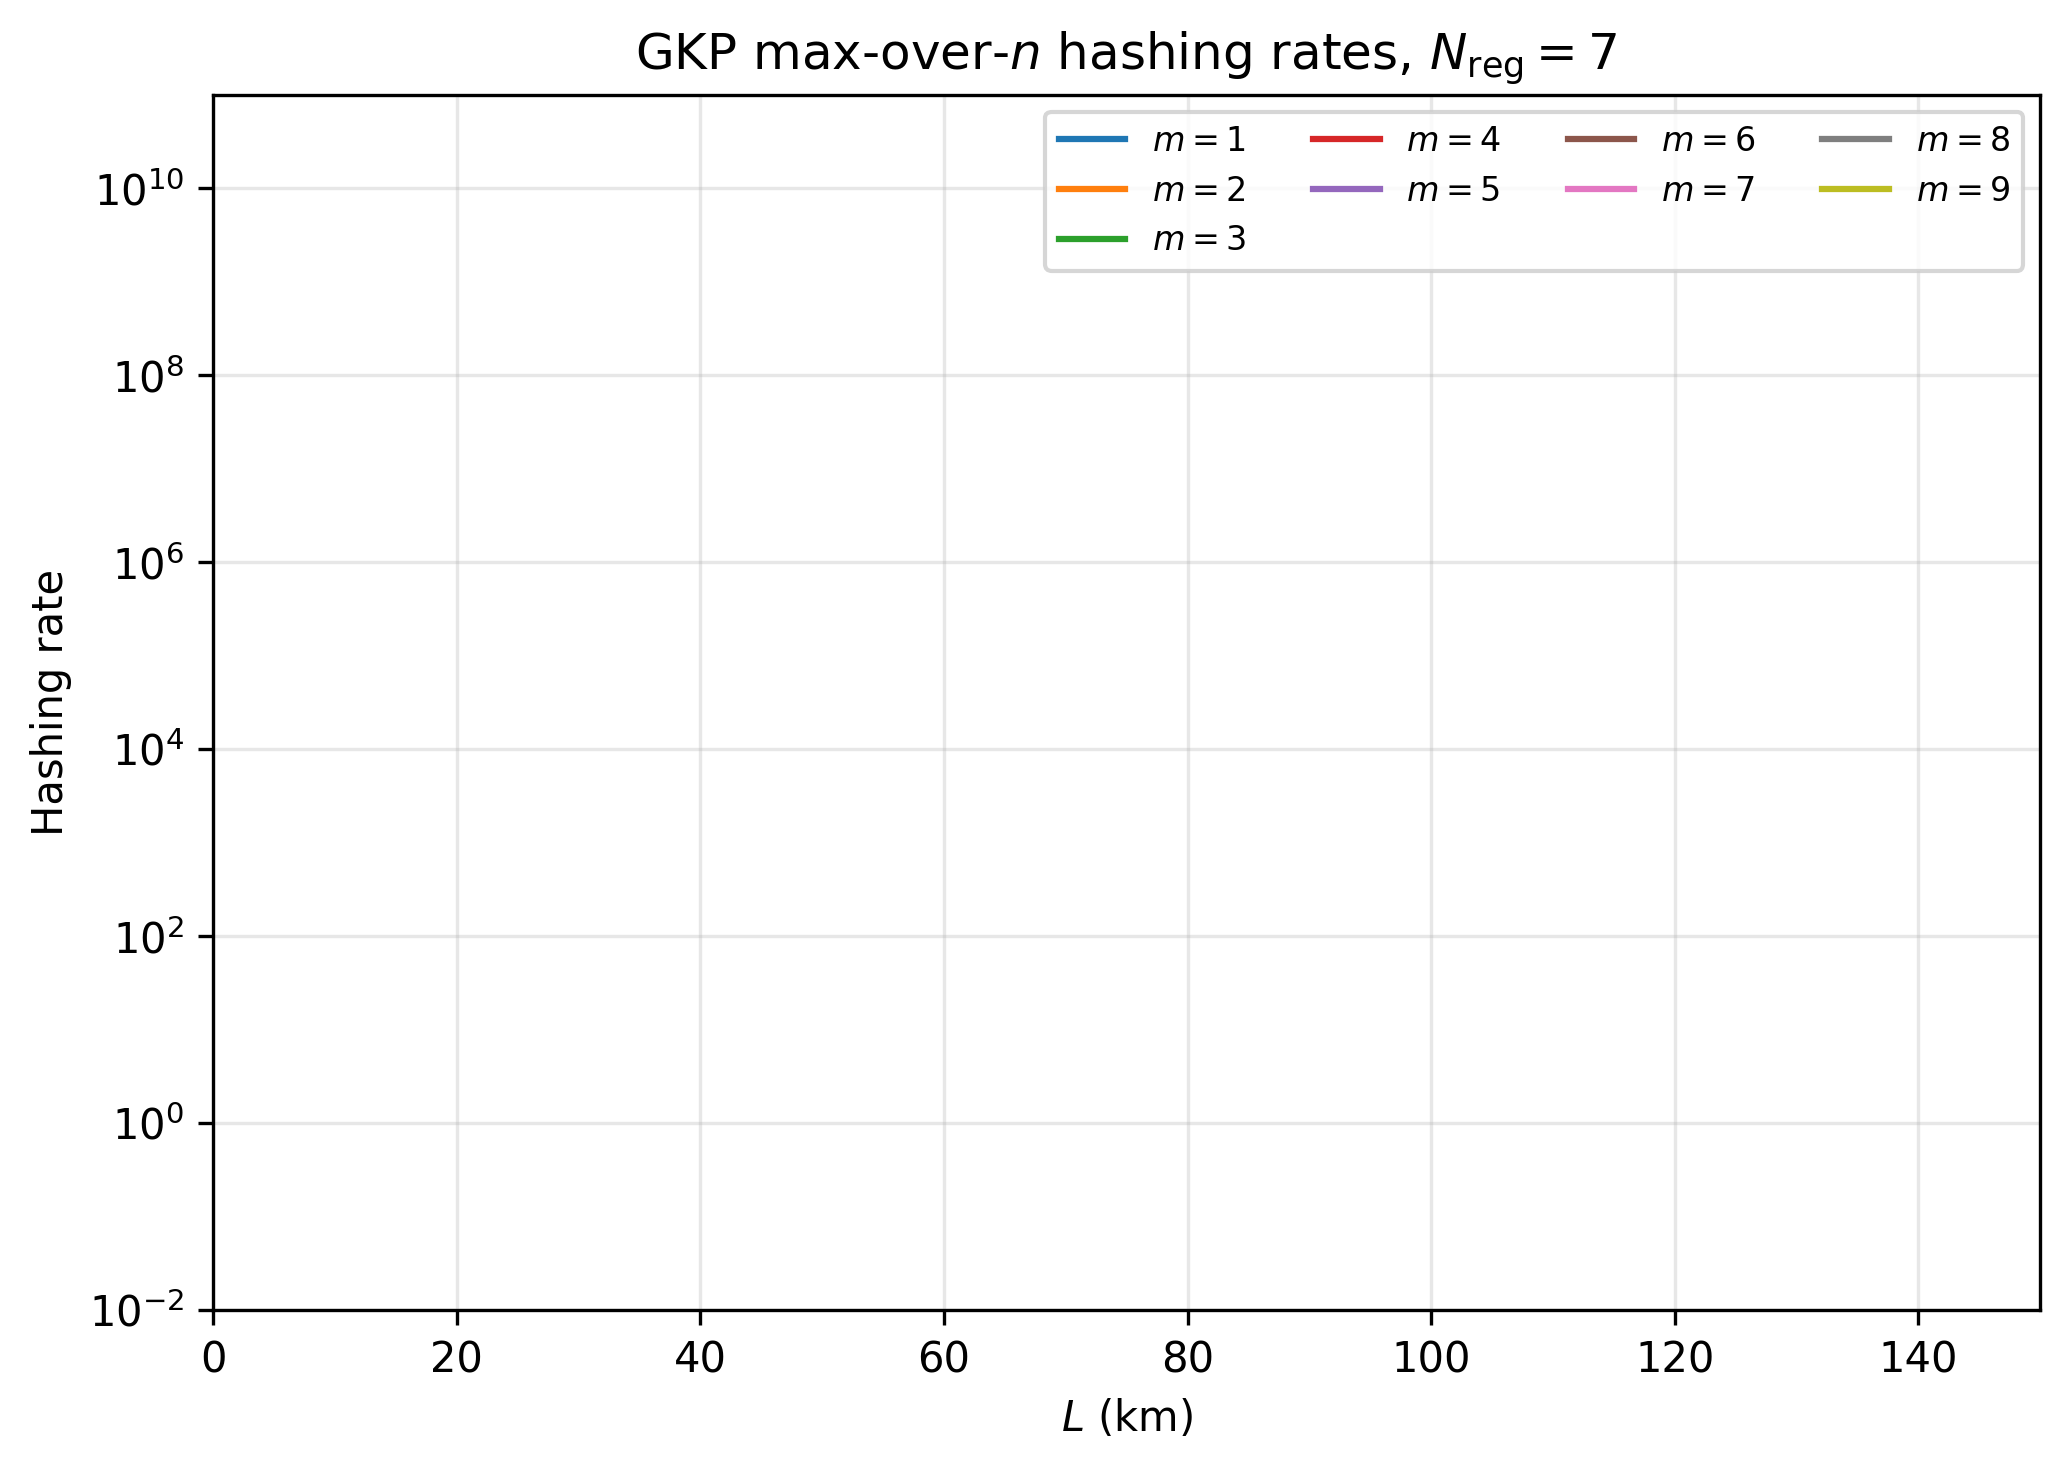


Plotting max-over-n curves for Nreg = 8


KeyError: 8

In [16]:
# ============================================================
# Plot max-over-n hashing-rate curves for all m
# for each fixed Nreg
# ============================================================

for Nreg in Nreg_values:

    print(f"\nPlotting max-over-n curves for Nreg = {Nreg}")

    available_m = sorted(all_results[Nreg].keys())

    fig, ax = plt.subplots(
        figsize=(7, 5),
        dpi=300
    )

    for m in available_m:

        out = all_results[Nreg][m]

        # --------------------------------------------
        # Collect the fixed-n curves
        # --------------------------------------------

        fixed_n_curves = []

        for n in n_vals:
            curve = np.asarray(
                out["fixed_n_data"][n]["rate"],
                dtype=float
            )
            fixed_n_curves.append(curve)

        # --------------------------------------------
        # Maximum over n for this fixed m
        # --------------------------------------------

        fixed_n_curves = np.vstack(fixed_n_curves)

        max_over_n = np.max(
            fixed_n_curves,
            axis=0
        )

        # --------------------------------------------
        # Plot this m curve
        # --------------------------------------------

        ax.plot(
            out["Ls"],
            max_over_n,
            linewidth=1.5,
            label=f"$m={m}$"
        )

    # --------------------------------------------
    # Formatting
    # --------------------------------------------

    ax.set_yscale("log")

    ax.set_xlabel("$L$ (km)")
    ax.set_ylabel("Hashing rate")
    ax.set_title(
        f"GKP max-over-$n$ hashing rates, $N_{{\\rm reg}}={Nreg}$"
    )

    ax.set_xlim(0, 150)
    ax.set_ylim(1e-2, 1e11)

    ax.grid(
        True,
        which="both",
        alpha=0.3
    )

    ax.legend(
        fontsize=8,
        ncol=4
    )

    plt.tight_layout()

    fig_path = os.path.join(
        output_dir,
        f"gkp_max_over_n_all_m_Nreg_{Nreg}.png"
    )

    plt.savefig(
        fig_path,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nDone.")

In [18]:
completed_results = {
    Nreg: all_results[Nreg]
    for Nreg in sorted(all_results.keys())
}

for Nreg in sorted(completed_results.keys()):
    print(
        Nreg,
        sorted(completed_results[Nreg].keys())
    )

1 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
2 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
3 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
4 [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np